
Global time origin: 2021-05-10

OVERALL DATA REPORT
                 metric                     value
         number_of_rows                    221895
        number_of_pmecs                       635
             start_date 2021-05-10 00:00:00+00:00
               end_date 2023-05-15 00:00:00+00:00
number_of_calendar_days                       736
       minimum_pressure                       0.0
        median_pressure                      3.43
          mean_pressure                  3.344595
       maximum_pressure                      3.91
 total_raw_measurements                   5060590

PRESSURE QUANTILES
 quantile  pressure_bar
    0.001          0.08
    0.010          0.19
    0.050          3.02
    0.250          3.34
    0.500          3.43
    0.750          3.48
    0.950          3.57
    0.990          3.63
    0.999          3.88

RAW MEASUREMENTS PER PMEC-DAY
statistic  raw_measurements_per_pmec_day
    count                       221895.0
     mean               

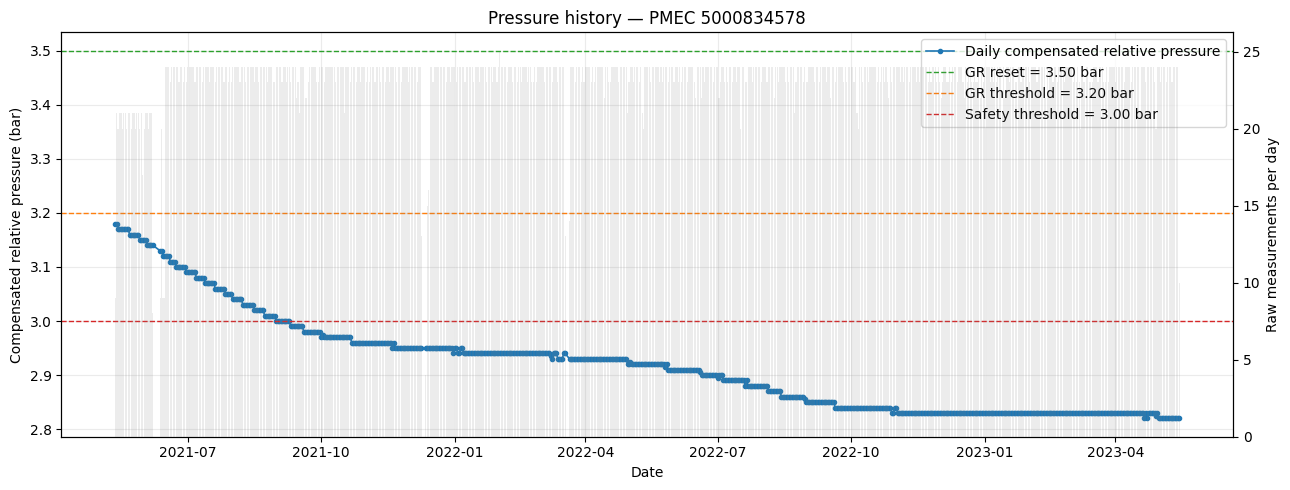

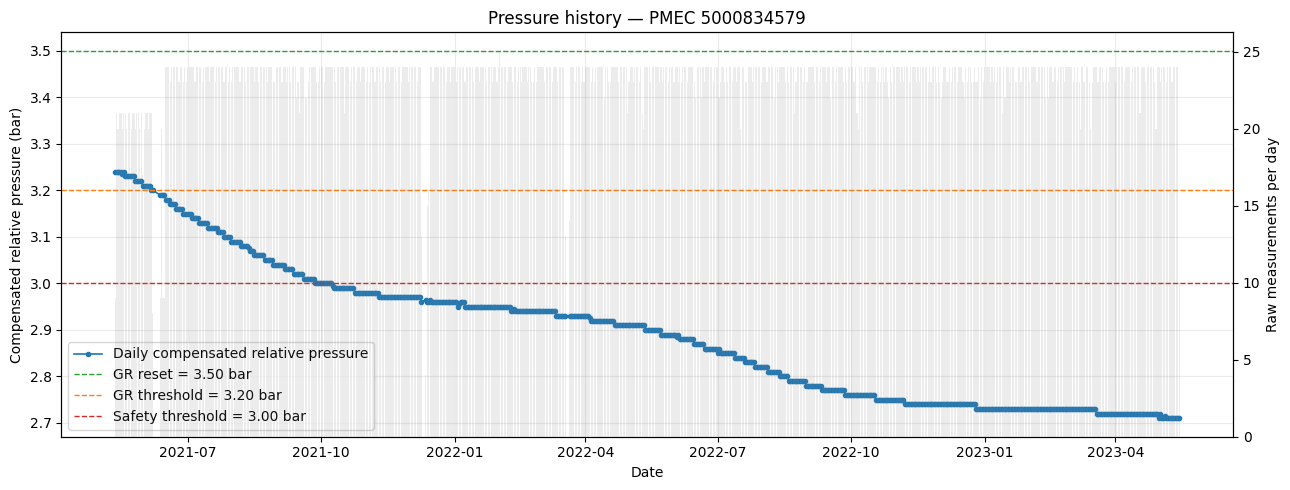

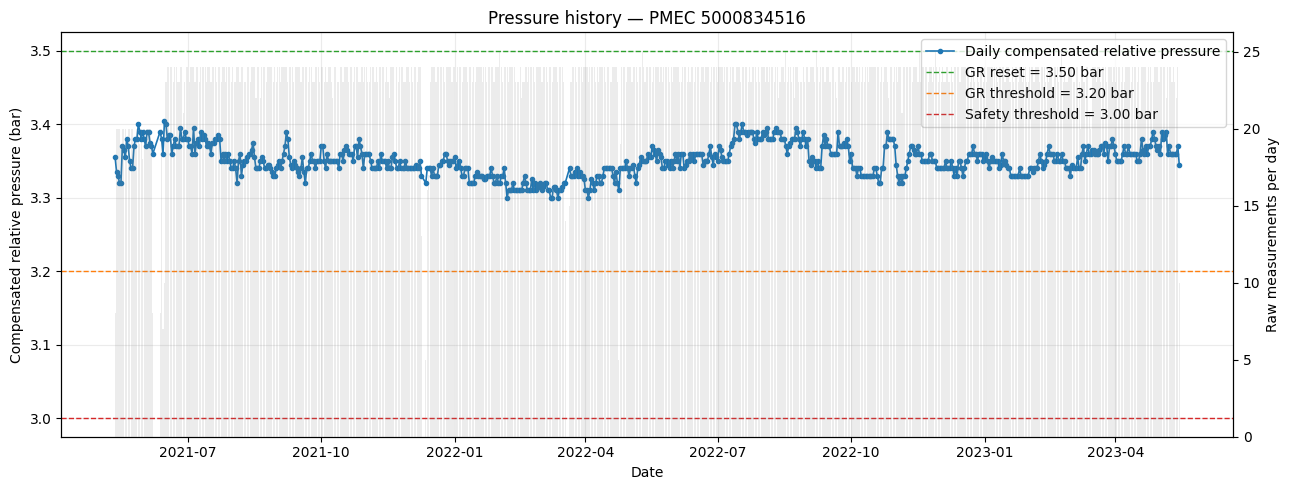

Saved 221,895 daily PMEC observations to: /Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/Uncertainty_20261012/clean_daily_pressure_data.csv


In [ ]:
# data filtering and cleaning for PMEC pressure time series
from __future__ import annotations

from pathlib import Path
from typing import Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. Configuration
# ============================================================

DATE_COLUMN = "dateMeasure"
PMEC_ID_COLUMN = "csemCur"
PRESSURE_COLUMN = "compensatedRelativePressure"

REQUIRED_COLUMNS = [
    DATE_COLUMN,
    PMEC_ID_COLUMN,
    PRESSURE_COLUMN,
]


# ============================================================
# 2. CSV loading and cleaning
# ============================================================

def read_pressure_data(
    csv_path: str | Path,
    sep: str = ",",
    encoding: Optional[str] = None,
    dayfirst: bool = False,
    daily_aggregation: str = "median",
) -> pd.DataFrame:
    """
    Load and clean only the three required columns from the raw CSV.

    Required raw CSV columns:
        - dateMeasure
        - csemCur
        - compensatedRelativePressure

    Parameters
    ----------
    csv_path:
        Path to CSV file.
    sep:
        Field separator. Use ';' if the CSV is semicolon-separated.
    encoding:
        Optional encoding such as 'utf-8', 'latin1', or 'utf-8-sig'.
    dayfirst:
        Set True when dates are stored as DD/MM/YYYY.
    daily_aggregation:
        One of: 'median', 'mean', 'last', 'first'.

    Returns
    -------
    pd.DataFrame:
        Columns:
            timestamp       : normalized daily date
            pmec_id         : caisson identifier, stored as string
            pressure_obs    : daily pressure observation in bar
            n_measurements  : number of raw measurements aggregated that day
    """

    # Read only the necessary columns.
    raw = pd.read_csv(
        csv_path,
        sep=sep,
        usecols=REQUIRED_COLUMNS,
        encoding=encoding,
        low_memory=False,
    )

    # Parse dates.
    raw[DATE_COLUMN] = pd.to_datetime(
        raw[DATE_COLUMN],
        errors="coerce",
        dayfirst=dayfirst,
    )

    # Convert PMEC IDs to stable strings.
    raw[PMEC_ID_COLUMN] = (
        raw[PMEC_ID_COLUMN]
        .astype("string")
        .str.strip()
    )

    # Safely convert pressure to numeric.
    # Supports strings such as "3,245" when decimal comma appears.
    raw[PRESSURE_COLUMN] = (
        raw[PRESSURE_COLUMN]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
        .replace(
            {
                "": pd.NA,
                "nan": pd.NA,
                "None": pd.NA,
                "NULL": pd.NA,
                "null": pd.NA,
            }
        )
    )

    raw[PRESSURE_COLUMN] = pd.to_numeric(
        raw[PRESSURE_COLUMN],
        errors="coerce",
    )

    # Keep only valid modeling records.
    raw = raw.dropna(
        subset=[
            DATE_COLUMN,
            PMEC_ID_COLUMN,
            PRESSURE_COLUMN,
        ]
    ).copy()

    # Remove blank PMEC IDs.
    raw = raw.loc[
        raw[PMEC_ID_COLUMN].str.len() > 0
    ].copy()

    # Normalize timestamps to daily resolution.
    raw["timestamp"] = raw[DATE_COLUMN].dt.normalize()

    # Rename into the standard model interface.
    raw = raw.rename(
        columns={
            PMEC_ID_COLUMN: "pmec_id",
            PRESSURE_COLUMN: "pressure_obs_raw",
        }
    )

    # Aggregate multiple measurements for the same PMEC on one day.
    if daily_aggregation == "median":
        pressure_agg = "median"
    elif daily_aggregation == "mean":
        pressure_agg = "mean"
    elif daily_aggregation == "first":
        pressure_agg = "first"
    elif daily_aggregation == "last":
        pressure_agg = "last"
    else:
        raise ValueError(
            "daily_aggregation must be one of: "
            "'median', 'mean', 'first', 'last'."
        )

    daily_data = (
        raw.groupby(
            ["timestamp", "pmec_id"],
            as_index=False,
            sort=True,
        )
        .agg(
            pressure_obs=("pressure_obs_raw", pressure_agg),
            n_measurements=("pressure_obs_raw", "count"),
        )
        .sort_values(
            ["pmec_id", "timestamp"]
        )
        .reset_index(drop=True)
    )

    # Final numerical safety check.
    daily_data["pressure_obs"] = pd.to_numeric(
        daily_data["pressure_obs"],
        errors="coerce",
    )

    daily_data = daily_data.dropna(
        subset=["pressure_obs"]
    ).reset_index(drop=True)

    return daily_data


# ============================================================
# 3. Calendar index
# ============================================================

def add_daily_time_index(
    daily_data: pd.DataFrame,
    origin_date: Optional[str | pd.Timestamp] = None,
) -> Tuple[pd.DataFrame, pd.Timestamp]:
    """
    Add a global integer day index.

    Missing days are intentionally not inserted here. In the future
    Kalman loop, a missing PMEC/day will trigger prediction without
    a measurement update.

    Output columns:
        timestamp, pmec_id, pressure_obs, n_measurements, time
    """

    required = {"timestamp", "pmec_id", "pressure_obs"}
    missing = required.difference(daily_data.columns)

    if missing:
        raise ValueError(
            f"daily_data is missing required columns: {sorted(missing)}"
        )

    data = daily_data.copy()
    data["timestamp"] = pd.to_datetime(data["timestamp"]).dt.normalize()

    if origin_date is None:
        origin = data["timestamp"].min()
    else:
        origin = pd.Timestamp(origin_date).normalize()

    data["time"] = (
        data["timestamp"] - origin
    ).dt.days.astype(int)

    data = (
        data.sort_values(["pmec_id", "time"])
        .reset_index(drop=True)
    )

    return data, origin


# ============================================================
# 4. Basic filtering utilities
# ============================================================

def filter_pressure_range(
    data: pd.DataFrame,
    min_pressure: Optional[float] = None,
    max_pressure: Optional[float] = None,
) -> pd.DataFrame:
    """
    Remove clearly impossible values if and only if you know
    physically justified limits for compensated relative pressure.

    Example:
        clean = filter_pressure_range(
            clean,
            min_pressure=0.0,
            max_pressure=5.0,
        )

    Do not set a narrow 3.0-3.5 interval here because values below
    3.0 may be important safety events and values above 3.5 may
    reveal actual GR resets or calibration effects.
    """

    result = data.copy()

    if min_pressure is not None:
        result = result.loc[
            result["pressure_obs"] >= min_pressure
        ]

    if max_pressure is not None:
        result = result.loc[
            result["pressure_obs"] <= max_pressure
        ]

    return result.reset_index(drop=True)


def select_pmecs(
    data: pd.DataFrame,
    pmec_ids: Optional[list[str]] = None,
    min_observations: Optional[int] = None,
) -> pd.DataFrame:
    """
    Optionally retain selected PMECs or PMECs with enough daily data.

    For the first pilot, a practical selection is:
        min_observations = 30
    """

    result = data.copy()

    if pmec_ids is not None:
        pmec_ids = [str(x) for x in pmec_ids]
        result = result.loc[
            result["pmec_id"].isin(pmec_ids)
        ].copy()

    if min_observations is not None:
        counts = result.groupby("pmec_id").size()
        retained = counts.loc[
            counts >= min_observations
        ].index

        result = result.loc[
            result["pmec_id"].isin(retained)
        ].copy()

    return result.reset_index(drop=True)


# ============================================================
# 5. Data quality reports
# ============================================================

def build_data_quality_report(
    data: pd.DataFrame,
) -> dict[str, pd.DataFrame]:
    """
    Return summary tables instead of only printing them.
    """

    if data.empty:
        raise ValueError("Input data is empty.")

    overall = pd.DataFrame(
        {
            "metric": [
                "number_of_rows",
                "number_of_pmecs",
                "start_date",
                "end_date",
                "number_of_calendar_days",
                "minimum_pressure",
                "median_pressure",
                "mean_pressure",
                "maximum_pressure",
                "total_raw_measurements",
            ],
            "value": [
                len(data),
                data["pmec_id"].nunique(),
                data["timestamp"].min(),
                data["timestamp"].max(),
                (
                    data["timestamp"].max()
                    - data["timestamp"].min()
                ).days
                + 1,
                data["pressure_obs"].min(),
                data["pressure_obs"].median(),
                data["pressure_obs"].mean(),
                data["pressure_obs"].max(),
                data["n_measurements"].sum(),
            ],
        }
    )

    by_pmec = (
        data.groupby("pmec_id")
        .agg(
            n_daily_observations=("timestamp", "count"),
            first_date=("timestamp", "min"),
            last_date=("timestamp", "max"),
            min_pressure=("pressure_obs", "min"),
            median_pressure=("pressure_obs", "median"),
            mean_pressure=("pressure_obs", "mean"),
            max_pressure=("pressure_obs", "max"),
            avg_raw_measurements_per_day=(
                "n_measurements",
                "mean",
            ),
        )
        .sort_values(
            "n_daily_observations",
            ascending=False,
        )
        .reset_index()
    )

    quantiles = (
        data["pressure_obs"]
        .quantile(
            [0.001, 0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999]
        )
        .rename("pressure_bar")
        .reset_index()
        .rename(columns={"index": "quantile"})
    )

    observation_count_distribution = (
        data["n_measurements"]
        .describe()
        .rename("raw_measurements_per_pmec_day")
        .reset_index()
        .rename(columns={"index": "statistic"})
    )

    duplicate_pmec_day_count = pd.DataFrame(
        {
            "metric": ["duplicate_pmec_day_rows"],
            "value": [
                int(
                    data.duplicated(
                        subset=["timestamp", "pmec_id"]
                    ).sum()
                )
            ],
        }
    )

    return {
        "overall": overall,
        "by_pmec": by_pmec,
        "pressure_quantiles": quantiles,
        "raw_measurement_counts": observation_count_distribution,
        "duplicates": duplicate_pmec_day_count,
    }


def print_data_quality_report(
    report: dict[str, pd.DataFrame],
    n_pmecs: int = 20,
) -> None:
    """
    Pretty-print a report made by build_data_quality_report().
    """

    print("\n" + "=" * 70)
    print("OVERALL DATA REPORT")
    print("=" * 70)
    print(report["overall"].to_string(index=False))

    print("\n" + "=" * 70)
    print("PRESSURE QUANTILES")
    print("=" * 70)
    print(report["pressure_quantiles"].to_string(index=False))

    print("\n" + "=" * 70)
    print("RAW MEASUREMENTS PER PMEC-DAY")
    print("=" * 70)
    print(report["raw_measurement_counts"].to_string(index=False))

    print("\n" + "=" * 70)
    print("DUPLICATE PMEC-DAY CHECK")
    print("=" * 70)
    print(report["duplicates"].to_string(index=False))

    print("\n" + "=" * 70)
    print(f"PMEC SUMMARY: TOP {n_pmecs}")
    print("=" * 70)
    print(
        report["by_pmec"]
        .head(n_pmecs)
        .to_string(index=False)
    )


# ============================================================
# 6. Missing-calendar-day analysis
# ============================================================

def missing_day_report(
    data: pd.DataFrame,
) -> pd.DataFrame:
    """
    For each PMEC, quantify calendar gaps.

    This is useful because the future Kalman filter should predict
    through missing dates without measurement updates.
    """

    rows = []

    for pmec_id, group in data.groupby("pmec_id"):
        dates = (
            group["timestamp"]
            .drop_duplicates()
            .sort_values()
        )

        if len(dates) <= 1:
            rows.append(
                {
                    "pmec_id": pmec_id,
                    "n_observed_days": len(dates),
                    "first_date": dates.min() if len(dates) else pd.NaT,
                    "last_date": dates.max() if len(dates) else pd.NaT,
                    "calendar_span_days": 0,
                    "missing_days_inside_span": 0,
                    "largest_gap_days": 0,
                }
            )
            continue

        date_diffs = dates.diff().dt.days.dropna()

        calendar_span = (
            dates.max() - dates.min()
        ).days + 1

        missing_days = calendar_span - len(dates)

        largest_gap = max(
            0,
            int(date_diffs.max()) - 1
        )

        rows.append(
            {
                "pmec_id": pmec_id,
                "n_observed_days": len(dates),
                "first_date": dates.min(),
                "last_date": dates.max(),
                "calendar_span_days": calendar_span,
                "missing_days_inside_span": missing_days,
                "largest_gap_days": largest_gap,
            }
        )

    return (
        pd.DataFrame(rows)
        .sort_values(
            ["missing_days_inside_span", "largest_gap_days"],
            ascending=False,
        )
        .reset_index(drop=True)
    )


# ============================================================
# 7. Plotting utility
# ============================================================

def plot_pmec_pressure(
    data: pd.DataFrame,
    pmec_id: str,
    start_date: Optional[str | pd.Timestamp] = None,
    end_date: Optional[str | pd.Timestamp] = None,
    show_raw_count: bool = False,
    p_reset: float = 3.5,
    p_gr: float = 3.2,
    p_safe: float = 3.0,
) -> None:
    """
    Plot the daily compensated relative pressure for one PMEC.
    """

    subset = data.loc[
        data["pmec_id"] == str(pmec_id)
    ].copy()

    if subset.empty:
        raise ValueError(f"PMEC '{pmec_id}' is not present in data.")

    if start_date is not None:
        subset = subset.loc[
            subset["timestamp"] >= pd.Timestamp(start_date)
        ]

    if end_date is not None:
        subset = subset.loc[
            subset["timestamp"] <= pd.Timestamp(end_date)
        ]

    subset = subset.sort_values("timestamp")

    if subset.empty:
        raise ValueError(
            "No observations remain after applying the date filter."
        )

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.plot(
        subset["timestamp"],
        subset["pressure_obs"],
        marker="o",
        markersize=3,
        linewidth=1.2,
        label="Daily compensated relative pressure",
    )

    ax.axhline(
        p_reset,
        linestyle="--",
        linewidth=1,
        color="tab:green",
        label=f"GR reset = {p_reset:.2f} bar",
    )

    ax.axhline(
        p_gr,
        linestyle="--",
        linewidth=1,
        color="tab:orange",
        label=f"GR threshold = {p_gr:.2f} bar",
    )

    ax.axhline(
        p_safe,
        linestyle="--",
        linewidth=1,
        color="tab:red",
        label=f"Safety threshold = {p_safe:.2f} bar",
    )

    ax.set_title(f"Pressure history — PMEC {pmec_id}")
    ax.set_xlabel("Date")
    ax.set_ylabel("Compensated relative pressure (bar)")
    ax.grid(alpha=0.25)
    ax.legend(loc="best")

    if show_raw_count:
        ax2 = ax.twinx()
        ax2.bar(
            subset["timestamp"],
            subset["n_measurements"],
            alpha=0.15,
            width=0.8,
            color="gray",
            label="Raw measurements per day",
        )
        ax2.set_ylabel("Raw measurements per day")

    plt.tight_layout()
    plt.show()


# ============================================================
# 8. Save cleaned data
# ============================================================

def save_clean_pressure_data(
    data: pd.DataFrame,
    output_path: str | Path,
) -> None:
    """
    Save the standardized daily pressure dataset for later stages:
    GR detection, cycle segmentation, Kalman filtering, and optimization.
    """

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    data.to_csv(
        output_path,
        index=False,
        date_format="%Y-%m-%d",
    )

    print(
        f"Saved {len(data):,} daily PMEC observations to: "
        f"{output_path}"
    )


# ============================================================
# 9. Example execution
# ============================================================

if __name__ == "__main__":

    # --------------------------------------------------------
    # A. Define your raw file path
    # --------------------------------------------------------
    CSV_PATH = "/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/Uncertainty-data/monitoring_output.csv"

    # If your file uses ';' rather than ',':
    # CSV_SEPARATOR = ";"
    CSV_SEPARATOR = ","

    # If dates look like 31/12/2025:
    # DATE_DAY_FIRST = True
    DATE_DAY_FIRST = False

    # --------------------------------------------------------
    # B. Read ONLY:
    #    dateMeasure, csemCur, compensatedRelativePressure
    # --------------------------------------------------------
    daily_pressure = read_pressure_data(
        csv_path=CSV_PATH,
        sep=CSV_SEPARATOR,
        encoding=None,
        dayfirst=DATE_DAY_FIRST,
        daily_aggregation="median",
    )

    # --------------------------------------------------------
    # C. Add global daily integer time index
    # --------------------------------------------------------
    daily_pressure, origin_date = add_daily_time_index(
        daily_data=daily_pressure
    )

    print(f"\nGlobal time origin: {origin_date.date()}")

    # --------------------------------------------------------
    # D. Optional: remove values that are impossible by physics.
    # Confirm these broad limits with your domain knowledge.
    # --------------------------------------------------------
    daily_pressure = filter_pressure_range(
        data=daily_pressure,
        min_pressure=0.0,
        max_pressure=10.0,
    )

    # --------------------------------------------------------
    # E. Optional: retain PMECs with enough history.
    # For the first Kalman prototype, use at least 30 daily points.
    # --------------------------------------------------------
    daily_pressure = select_pmecs(
        data=daily_pressure,
        pmec_ids=None,
        min_observations=30,
    )

    # --------------------------------------------------------
    # F. Produce data-quality summaries
    # --------------------------------------------------------
    report = build_data_quality_report(daily_pressure)
    print_data_quality_report(report, n_pmecs=20)

    gaps = missing_day_report(daily_pressure)

    print("\n" + "=" * 70)
    print("PMECS WITH THE LARGEST OBSERVATION GAPS")
    print("=" * 70)
    print(gaps.head(20).to_string(index=False))

    # --------------------------------------------------------
    # G. Display a few PMEC pressure trajectories
    # --------------------------------------------------------
    pmecs_to_plot = (
        report["by_pmec"]
        .head(3)["pmec_id"]
        .astype(str)
        .tolist()
    )

    for pmec_id in pmecs_to_plot:
        plot_pmec_pressure(
            data=daily_pressure,
            pmec_id=pmec_id,
            show_raw_count=True,
            p_reset=3.5,
            p_gr=3.2,
            p_safe=3.0,
        )

    # --------------------------------------------------------
    # H. Save the clean standardized table
    # --------------------------------------------------------
    save_clean_pressure_data(
        data=daily_pressure,
        output_path="/Users/wenbo.wu/Documents/Documents - Wenbo WU/Thesis/RTE_use_case/RTE_dashboard/Uncertainty_20261012/clean_daily_pressure_data.csv",
    )

In [106]:
# identity zigzag patterns in the pressure time series for each PMEC ID

import pandas as pd
import numpy as np
from scipy.signal import find_peaks


def detect_zigzag(
    df: pd.DataFrame,
    min_cycles: int = 3,
    min_rel_amplitude: float = 0.10,
    min_abs_amplitude: float = 0.5,
    min_slope: float = 0.0,
    smooth_window: int = 3,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    识别每个 pmec_id 的 pressure_obs 是否呈 zigzag（反复上下波动）。

    Parameters
    ----------
    df:
        必须包含列：
        ['timestamp', 'pmec_id', 'pressure_obs', 'n_measurements', 'time']
        其中 time 应为可用于排序/计算斜率的数值时间。

    min_cycles:
        至少需要多少个完整“上升+下降”周期。

    min_rel_amplitude:
        峰谷振幅至少占该 pmec 压力总波动范围的比例。
        例如 0.10 表示振幅至少为 range 的 10%。

    min_abs_amplitude:
        峰谷振幅的绝对下限，用于避免把纯测量噪声判为 zigzag。
        单位与 pressure_obs 相同。

    min_slope:
        每个上升/下降段的平均斜率绝对值下限。
        单位为 pressure_obs / time。设为 0 表示不筛选斜率。

    smooth_window:
        中位数平滑窗口。设为 1 表示不平滑。

    Returns
    -------
    results:
        每个 pmec_id 一行，包含 is_zigzag、周期数、平均振幅等。

    segments:
        检测到的交替上升/下降段，便于人工核查。
    """
    required = {"timestamp", "pmec_id", "pressure_obs", "n_measurements", "time"}
    missing = required - set(df.columns)
    if missing:
        raise ValueError(f"CSV 缺少列: {missing}")

    results = []
    all_segments = []

    for pmec_id, g in df.sort_values("time").groupby("pmec_id", sort=False):
        y = g["pressure_obs"].astype(float).to_numpy()
        t = g["time"].astype(float).to_numpy()
        n = len(y)

        row = {
            "pmec_id": pmec_id,
            "n_points": n,
            "is_zigzag": False,
            "n_cycles": 0,
            "n_extrema": 0,
            "median_amplitude": np.nan,
            "pressure_range": np.nan,
            "reason": "",
        }

        if n < 2 * min_cycles + 1:
            row["reason"] = "not enough points"
            results.append(row)
            continue

        # 轻度中位数平滑，抑制单点噪声；不影响整体趋势
        if smooth_window > 1:
            y_smooth = (
                pd.Series(y)
                .rolling(smooth_window, center=True, min_periods=1)
                .median()
                .to_numpy()
            )
        else:
            y_smooth = y.copy()

        pressure_range = float(np.ptp(y_smooth))
        row["pressure_range"] = pressure_range

        if pressure_range <= 0:
            row["reason"] = "constant pressure"
            results.append(row)
            continue

        # 峰/谷显著性阈值：相对振幅和绝对振幅取较大者
        prominence = max(
            min_rel_amplitude * pressure_range,
            min_abs_amplitude / 2,
        )

        peak_idx, _ = find_peaks(y_smooth, prominence=prominence)
        trough_idx, _ = find_peaks(-y_smooth, prominence=prominence)

        # 合并并强制峰谷交替
        extrema = sorted(
            [(i, "peak") for i in peak_idx]
            + [(i, "trough") for i in trough_idx]
        )

        alternating = []
        for idx, kind in extrema:
            if not alternating or alternating[-1][1] != kind:
                alternating.append((idx, kind))

        row["n_extrema"] = len(alternating)

        # zigzag 至少需要：peak-trough-peak-trough...
        if len(alternating) < 2 * min_cycles + 1:
            row["reason"] = "not enough alternating peaks/troughs"
            results.append(row)
            continue

        segment_rows = []
        amplitudes = []
        slopes_ok = True

        for (i1, kind1), (i2, kind2) in zip(alternating[:-1], alternating[1:]):
            dy = y_smooth[i2] - y_smooth[i1]
            dt = t[i2] - t[i1]

            if dt <= 0:
                slopes_ok = False
                break

            slope = dy / dt
            amplitude = abs(dy)

            amplitudes.append(amplitude)
            segment_rows.append(
                {
                    "pmec_id": pmec_id,
                    "start_index": i1,
                    "end_index": i2,
                    "start_time": t[i1],
                    "end_time": t[i2],
                    "direction": "up" if dy > 0 else "down",
                    "delta_pressure": dy,
                    "duration": dt,
                    "mean_slope": slope,
                }
            )

            if abs(slope) < min_slope:
                slopes_ok = False

        all_segments.extend(segment_rows)

        n_cycles = (len(alternating) - 1) // 2
        median_amplitude = float(np.median(amplitudes)) if amplitudes else np.nan

        row["n_cycles"] = n_cycles
        row["median_amplitude"] = median_amplitude

        amplitude_ok = median_amplitude >= min_abs_amplitude

        if n_cycles < min_cycles:
            row["reason"] = "too few cycles"
        elif not amplitude_ok:
            row["reason"] = "amplitude too small"
        elif not slopes_ok:
            row["reason"] = "some segments have insufficient slope"
        else:
            row["is_zigzag"] = True
            row["reason"] = "zigzag detected"

        results.append(row)

    return pd.DataFrame(results), pd.DataFrame(all_segments)


# ============ 使用方法 ============

csv_path = "clean_daily_pressure_data.csv"

df = pd.read_csv(csv_path)

# 如果 time 是字符串时间，先转成数值，例如秒：
# df["time"] = pd.to_datetime(df["time"])
# df["time"] = (df["time"] - df["time"].min()).dt.total_seconds()

results, segments = detect_zigzag(
    df,
    min_cycles=3,              # 至少 3 个完整上下周期
    min_rel_amplitude=0.10,    # 振幅至少占整体压力波动范围的 10%
    min_abs_amplitude=0.5,     # 振幅至少 0.5 个 pressure 单位
    min_slope=0.0,             # 不额外限制斜率
    smooth_window=3,           # 3 点中位数平滑
)

# 只看被判定为 zigzag 的 pmec
zigzag_pmecs = results.loc[results["is_zigzag"], "pmec_id"]

print(results)
print("\nZigzag PMEC IDs:")
print(zigzag_pmecs.tolist())

# 保存结果
results.to_csv("pmec_zigzag_results.csv", index=False)
segments.to_csv("pmec_zigzag_segments.csv", index=False)

        pmec_id  n_points  is_zigzag  n_cycles  n_extrema  median_amplitude  \
0    5000834900       572      False         0          0               NaN   
1    5000834902       571      False         0          0               NaN   
2    5000834891       314      False         0          0               NaN   
3    5000834901       571      False         0          0               NaN   
4    5000834895       571      False         0          0               NaN   
..          ...       ...        ...       ...        ...               ...   
630  5000818616        37      False         0          0               NaN   
631  5000818644        32      False         0          0               NaN   
632  5000818492        83      False         0          0               NaN   
633  5000818493        83      False         0          0               NaN   
634  5000818612        75      False         0          0               NaN   

     pressure_range                                

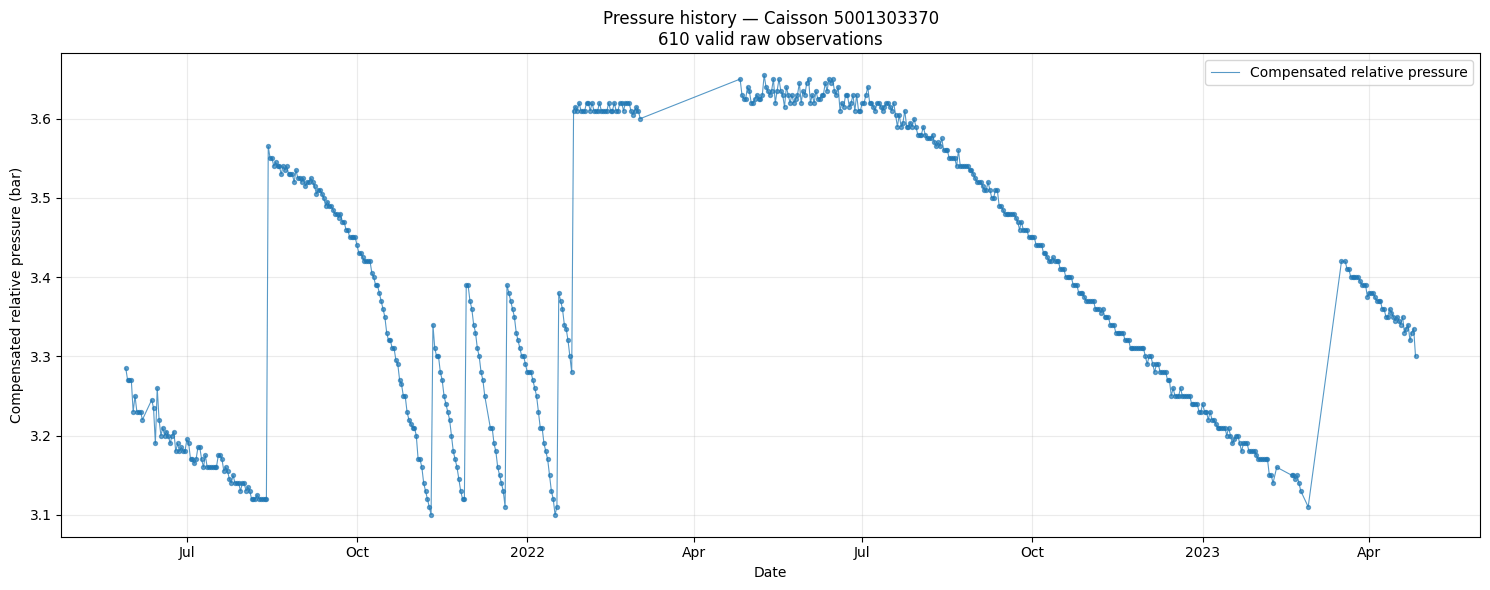

Caisson: 5001303370
Number of valid observations: 610
Date range: 2021-05-29 00:00:00 to 2023-04-26 00:00:00

Pressure summary (bar):
count       610.0
mean     3.389705
std      0.171438
min           3.1
25%          3.23
50%        3.3775
75%          3.55
max         3.655
Name: pressure_obs, dtype: Float64


In [115]:
# data visualization: given a PMEC ID, plot the daily compensated relative pressure over time

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


def plot_raw_pressure_for_caisson(
    csv_path: str | Path,
    caisson_id: str,
    sep: str = ",",
    encoding: str | None = None,
    dayfirst: bool = False,
    show_line: bool = True,
    show_points: bool = True,
    point_size: float = 8,
    line_width: float = 0.8,
    figsize: tuple[float, float] = (15, 6),
) -> pd.DataFrame:
    """
    Read only the necessary columns from the raw CSV and plot all valid
    compensatedRelativePressure measurements for one given caisson.

    Parameters
    ----------
    csv_path:
        Path to the raw CSV file.

    caisson_id:
        Value of pmec_id identifying the caisson to plot.
        It is compared as a string.

    sep:
        CSV separator, typically ',' or ';'.

    encoding:
        Optional encoding, e.g. 'utf-8-sig', 'latin1', or 'cp1252'.

    dayfirst:
        True if dateMeasure uses DD/MM/YYYY format.

    show_line:
        If True, connect consecutive observations by a line.

    show_points:
        If True, draw every raw measurement as a point.

    Returns
    -------
    pd.DataFrame:
        The cleaned raw observations plotted, with:
        timestamp, pmec_id, compensatedRelativePressure.
    """

    date_col = "timestamp"
    id_col = "pmec_id"
    pressure_col = "pressure_obs"

    raw = pd.read_csv(
        csv_path,
        sep=sep,
        encoding=encoding,
        usecols=[date_col, id_col, pressure_col],
        low_memory=False,
    )

    raw[id_col] = raw[id_col].astype("string").str.strip()

    raw[date_col] = pd.to_datetime(
        raw[date_col],
        errors="coerce",
        dayfirst=dayfirst,
    )

    raw[pressure_col] = (
        raw[pressure_col]
        .astype("string")
        .str.strip()
        .str.replace(",", ".", regex=False)
        .replace(
            {
                "": pd.NA,
                "nan": pd.NA,
                "None": pd.NA,
                "NULL": pd.NA,
                "null": pd.NA,
            }
        )
    )

    raw[pressure_col] = pd.to_numeric(
        raw[pressure_col],
        errors="coerce",
    )

    selected = raw.loc[
        raw[id_col].astype(str) == str(caisson_id)
    ].copy()

    # Remove missing values
    selected = selected.dropna(
        subset=[date_col, pressure_col]
    )

    # Remove pressure observations below 2.5 bar
    selected = selected.loc[
        selected[pressure_col] >= 2.5
    ].copy()

    # Sort by date
    selected = (
        selected.sort_values(date_col)
        .reset_index(drop=True)
    )

    if selected.empty:
        available_ids = raw[id_col].dropna().unique()[:20]

        raise ValueError(
            f"Caisson '{caisson_id}' was not found, or it has no valid "
            f"date/pressure observations.\n"
            f"Examples of available csemCur values: {available_ids}"
        )

    fig, ax = plt.subplots(figsize=figsize)

    if show_line:
        ax.plot(
            selected[date_col],
            selected[pressure_col],
            color="tab:blue",
            linewidth=line_width,
            alpha=0.75,
            label="Compensated relative pressure",
        )

    if show_points:
        ax.scatter(
            selected[date_col],
            selected[pressure_col],
            color="tab:blue",
            s=point_size,
            alpha=0.65,
            zorder=3,
            label="Raw pressure observation" if not show_line else None,
        )

    ax.set_title(
        f"Pressure history — Caisson {caisson_id}\n"
        f"{len(selected):,} valid raw observations"
    )
    ax.set_xlabel("Date")
    ax.set_ylabel("Compensated relative pressure (bar)")

    ax.grid(True, alpha=0.25)

    locator = mdates.AutoDateLocator()
    formatter = mdates.ConciseDateFormatter(locator)

    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(formatter)

    if show_line or show_points:
        ax.legend(loc="best")

    plt.tight_layout()
    plt.show()

    print(f"Caisson: {caisson_id}")
    print(f"Number of valid observations: {len(selected):,}")
    print(
        f"Date range: {selected[date_col].min()} "
        f"to {selected[date_col].max()}"
    )
    print("\nPressure summary (bar):")
    print(selected[pressure_col].describe())

    return selected


# ============================================================
# Example usage
# ============================================================

CSV_PATH = "clean_daily_pressure_data.csv"

# CAISSON_ID = "5001319493"
CAISSON_ID = "5001303370"

caisson_data = plot_raw_pressure_for_caisson(
    csv_path=CSV_PATH,
    caisson_id=CAISSON_ID,
    sep=",",              # Change to ";" if needed
    encoding=None,        # Try "utf-8-sig" or "latin1" if needed
    dayfirst=False,       # Change to True for DD/MM/YYYY
    show_line=True,
    show_points=True,
)







In [ ]:
# detect suspected GR events in the cleaned daily pressure data
from pathlib import Path

import numpy as np
import pandas as pd


EVENT_COLUMNS = [
    "pmec_id",
    "candidate_date",
    "last_before_date",
    "gap_days",
    "pressure_before",
    "pressure_after",
    "jump_bar",
    "before_median",
    "after_median",
    "median_increase_bar",
    "persistence_fraction",
    "near_reset",
    "status",
]


def detect_suspected_gr_events(
    daily_data: pd.DataFrame,
    pmec_ids: list[str],
    min_jump_bar: float = 0.10,
    min_median_increase_bar: float = 0.08,
    window_points: int = 3,
    min_points_per_side: int = 2,
    max_window_span_days: int = 7,
    persistence_fraction: float = 0.80,
    max_gap_days: int = 2,
    merge_within_days: int = 3,
    reset_pressure: float = 3.5,
    reset_tolerance: float = 0.15,
) -> pd.DataFrame:
    """
    Detect suspected GR events in cleaned daily pressure data.

    Required input columns:
        timestamp, pmec_id, pressure_obs

    candidate_date:
        First higher-pressure observation following a detected jump.
        It is NOT necessarily the exact GR execution time.

    status:
        probable_gr:
            Persistent jump with sufficiently close observations.
        uncertain_time:
            Persistent jump across a long observation gap.

    near_reset:
        Additional diagnostic only; not a mandatory detection condition.
    """

    required = {"timestamp", "pmec_id", "pressure_obs"}
    missing = required.difference(daily_data.columns)

    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    if not 0 < persistence_fraction <= 1:
        raise ValueError("persistence_fraction must be in (0, 1].")

    if not 1 <= min_points_per_side <= window_points:
        raise ValueError(
            "Require 1 <= min_points_per_side <= window_points."
        )

    if min_jump_bar <= 0 or min_median_increase_bar <= 0:
        raise ValueError("Pressure increase thresholds must be positive.")

    data = daily_data.copy()
    data["timestamp"] = pd.to_datetime(
        data["timestamp"], errors="coerce"
    ).dt.normalize()
    data["pmec_id"] = data["pmec_id"].astype("string").str.strip()
    data["pressure_obs"] = pd.to_numeric(
        data["pressure_obs"], errors="coerce"
    )

    valid = (
        data["timestamp"].notna()
        & data["pmec_id"].notna()
        & np.isfinite(data["pressure_obs"])
    )
    data = data.loc[valid].copy()

    requested_ids = list(
        dict.fromkeys(str(x).strip() for x in pmec_ids)
    )
    data = data.loc[data["pmec_id"].isin(requested_ids)]

    # This detector expects one observation per PMEC per calendar day.
    if data.duplicated(["pmec_id", "timestamp"]).any():
        raise ValueError(
            "Duplicate PMEC-day rows found. "
            "Please use the daily aggregated dataset."
        )

    events = []

    for pmec_id in requested_ids:
        group = (
            data.loc[data["pmec_id"] == pmec_id]
            .sort_values("timestamp")
            .reset_index(drop=True)
        )

        if len(group) < 2 * min_points_per_side:
            continue

        dates = group["timestamp"]
        pressures = group["pressure_obs"].to_numpy(dtype=float)
        candidates = []

        for k in range(1, len(group)):
            jump = pressures[k] - pressures[k - 1]

            if jump < min_jump_bar:
                continue

            before = group.iloc[max(0, k - window_points):k]
            after = group.iloc[k:min(len(group), k + window_points)]

            if (
                len(before) < min_points_per_side
                or len(after) < min_points_per_side
            ):
                continue

            before_span = (
                before["timestamp"].iloc[-1]
                - before["timestamp"].iloc[0]
            ).days
            after_span = (
                after["timestamp"].iloc[-1]
                - after["timestamp"].iloc[0]
            ).days

            if (
                before_span > max_window_span_days
                or after_span > max_window_span_days
            ):
                continue

            before_median = float(before["pressure_obs"].median())
            after_median = float(after["pressure_obs"].median())
            median_increase = after_median - before_median

            if median_increase < min_median_increase_bar:
                continue

            # Check that the post-jump observations stay above
            # the pre-jump baseline by the specified pressure margin.
            sustained_fraction = float(
                (
                    after["pressure_obs"]
                    >= before_median + min_median_increase_bar
                ).mean()
            )

            if sustained_fraction < persistence_fraction:
                continue

            gap_days = int((dates.iloc[k] - dates.iloc[k - 1]).days)
            near_reset = (
                abs(after_median - reset_pressure) <= reset_tolerance
            )

            candidates.append({
                "pmec_id": pmec_id,
                "candidate_date": dates.iloc[k],
                "last_before_date": dates.iloc[k - 1],
                "gap_days": gap_days,
                "pressure_before": float(pressures[k - 1]),
                "pressure_after": float(pressures[k]),
                "jump_bar": float(jump),
                "before_median": before_median,
                "after_median": after_median,
                "median_increase_bar": median_increase,
                "persistence_fraction": sustained_fraction,
                "near_reset": bool(near_reset),
                "status": (
                    "probable_gr"
                    if gap_days <= max_gap_days
                    else "uncertain_time"
                ),
            })

        # Merge nearby candidates, such as a refill spread across two days.
        # Retain the largest jump in each nearby candidate group.
        merged = []

        for event in candidates:
            if merged:
                separation = (
                    event["candidate_date"]
                    - merged[-1]["candidate_date"]
                ).days

                if separation <= merge_within_days:
                    if event["jump_bar"] > merged[-1]["jump_bar"]:
                        merged[-1] = event
                    continue

            merged.append(event)

        events.extend(merged)

    result = pd.DataFrame(events, columns=EVENT_COLUMNS)

    if not result.empty:
        result = (
            result.sort_values(["pmec_id", "candidate_date"])
            .reset_index(drop=True)
        )

    return result


def print_gr_events_by_pmec(
    events: pd.DataFrame,
    pmec_ids: list[str],
    daily_data: pd.DataFrame,
) -> None:
    """Print suspected events separately for each requested PMEC."""

    available_ids = set(
        daily_data["pmec_id"].astype("string").str.strip().dropna()
    )

    for pmec_id in dict.fromkeys(str(x).strip() for x in pmec_ids):
        print("\n" + "=" * 72)
        print(f"PMEC / caisson: {pmec_id}")
        print("=" * 72)

        if pmec_id not in available_ids:
            print("该编号未出现在输入数据中。")
            continue

        subset = events.loc[events["pmec_id"] == pmec_id]

        if subset.empty:
            print("未发现满足当前规则的疑似 GR 事件。")
            continue

        print(f"发现 {len(subset)} 个疑似事件：")

        for _, event in subset.iterrows():
            before_date = event["last_before_date"].strftime("%Y-%m-%d")
            candidate_date = event["candidate_date"].strftime("%Y-%m-%d")

            print(
                f"\n  候选日期：{candidate_date}"
                f"\n  观测边界：{before_date} → {candidate_date}"
                f"（间隔 {event['gap_days']} 天）"
                f"\n  相邻压力：{event['pressure_before']:.4f}"
                f" → {event['pressure_after']:.4f} bar"
                f"\n  上升幅度：{event['jump_bar']:.4f} bar"
                f"\n  前后中位数：{event['before_median']:.4f}"
                f" → {event['after_median']:.4f} bar"
                f"\n  后续维持比例："
                f"{event['persistence_fraction']:.0%}"
                f"\n  接近 3.5 bar："
                f"{'是' if event['near_reset'] else '否'}"
                f"\n  状态：{event['status']}"
            )


if __name__ == "__main__":
    # Use the cleaned DAILY dataset, not the original sensor CSV.
    CSV_PATH = "clean_daily_pressure_data.csv"

    # Replace these with the PMEC IDs you selected.
    PMEC_IDS = [
        "5001319493",
        "5000818612",
        "5000818616",
        "5000834560",
        "5001319385",
        "5001303342",
        "5001319422",
        "5001303370",
    ]

    daily_data = pd.read_csv(
        CSV_PATH,
        dtype={"pmec_id": "string"},
    )

    gr_candidates = detect_suspected_gr_events(
        daily_data=daily_data,
        pmec_ids=PMEC_IDS,
        min_jump_bar=0.10,
        min_median_increase_bar=0.08,
        window_points=3,
        min_points_per_side=2,
        max_window_span_days=7,
        persistence_fraction=0.80,
        max_gap_days=2,
        merge_within_days=3,
        reset_pressure=3.5,
        reset_tolerance=0.15,
    )

    print_gr_events_by_pmec(
        events=gr_candidates,
        pmec_ids=PMEC_IDS,
        daily_data=daily_data,
    )

    output_path = Path("suspected_gr_events.csv")
    gr_candidates.to_csv(
        output_path,
        index=False,
        date_format="%Y-%m-%d",
    )

    print(f"\n已保存 {len(gr_candidates)} 个候选事件：{output_path}")


PMEC / caisson: 5001319493
发现 5 个疑似事件：

  候选日期：2021-08-04
  观测边界：2021-08-03 → 2021-08-04（间隔 1 天）
  相邻压力：3.0900 → 3.3900 bar
  上升幅度：0.3000 bar
  前后中位数：3.0800 → 3.3800 bar
  后续维持比例：100%
  接近 3.5 bar：是
  状态：probable_gr

  候选日期：2021-11-10
  观测边界：2021-11-09 → 2021-11-10（间隔 1 天）
  相邻压力：3.2000 → 3.4700 bar
  上升幅度：0.2700 bar
  前后中位数：3.1800 → 3.4700 bar
  后续维持比例：100%
  接近 3.5 bar：是
  状态：probable_gr

  候选日期：2022-03-21
  观测边界：2022-03-18 → 2022-03-21（间隔 3 天）
  相邻压力：3.2000 → 3.5200 bar
  上升幅度：0.3200 bar
  前后中位数：3.2000 → 3.5000 bar
  后续维持比例：100%
  接近 3.5 bar：是
  状态：uncertain_time

  候选日期：2022-08-11
  观测边界：2022-08-10 → 2022-08-11（间隔 1 天）
  相邻压力：3.2200 → 3.5300 bar
  上升幅度：0.3100 bar
  前后中位数：3.2200 → 3.5200 bar
  后续维持比例：100%
  接近 3.5 bar：是
  状态：probable_gr

  候选日期：2023-01-31
  观测边界：2023-01-30 → 2023-01-31（间隔 1 天）
  相邻压力：3.1600 → 3.4800 bar
  上升幅度：0.3200 bar
  前后中位数：3.1600 → 3.4800 bar
  后续维持比例：100%
  接近 3.5 bar：是
  状态：probable_gr

PMEC / caisson: 5000818612
发现 1 个疑似事件：

  候选日期：2023-04-05
  观测边界：2023-0

In [ ]:
# delete manually the events that are not GR events, and keep the confirmed GR events in a separate CSV file for further analysis(suspected_gr_events_reviewed.csv).
import pandas as pd

# 人工检查后需要删除的 (PMEC ID, 候选日期)
events_to_remove = pd.DataFrame(
    [
        ("5001319385", "2022-04-27"),
        ("5001303342", "2022-01-24"),
        ("5001319422", "2022-12-06"),
        ("5001303370", "2021-08-14"),
        ("5001303370", "2022-01-26"),
        ("5001303370", "2023-03-17"),
    ],
    columns=["pmec_id", "candidate_date"],
)

# 创建副本，保留之前的自动检测结果
gr_candidates_reviewed = gr_candidates.copy()

# 统一 ID 和日期格式
gr_candidates_reviewed["pmec_id"] = (
    gr_candidates_reviewed["pmec_id"]
    .astype("string")
    .str.strip()
)

gr_candidates_reviewed["candidate_date"] = pd.to_datetime(
    gr_candidates_reviewed["candidate_date"],
    errors="raise",
)

# 按“PMEC ID + 日历日期”匹配，避免误删其他 PMEC 的事件
result_keys = pd.MultiIndex.from_arrays(
    [
        gr_candidates_reviewed["pmec_id"],
        gr_candidates_reviewed["candidate_date"].dt.normalize(),
    ]
)

remove_keys = pd.MultiIndex.from_arrays(
    [
        events_to_remove["pmec_id"],
        pd.to_datetime(events_to_remove["candidate_date"]),
    ]
)

remove_mask = result_keys.isin(remove_keys)

# 保存删除记录，方便追踪人工审核
removed_events = gr_candidates_reviewed.loc[remove_mask].copy()

# 删除匹配的候选事件
gr_candidates_reviewed = (
    gr_candidates_reviewed.loc[~remove_mask]
    .sort_values(["pmec_id", "candidate_date"])
    .reset_index(drop=True)
)

print(f"删除前：{len(gr_candidates)} 条候选事件")
print(f"实际删除：{len(removed_events)} 条候选事件")
print(f"删除后：{len(gr_candidates_reviewed)} 条候选事件")

print("\n实际删除的事件：")
print(
    removed_events[["pmec_id", "candidate_date"]]
    .to_string(index=False)
)

# 检查是否有指定事件未匹配到
matched_keys = result_keys[remove_mask]
missing_mask = ~remove_keys.isin(matched_keys)

if missing_mask.any():
    print("\n注意：以下指定事件未在原结果中找到：")
    print(events_to_remove.loc[missing_mask].to_string(index=False))

# 保存审核后的结果，保留原始自动检测文件
gr_candidates_reviewed.to_csv(
    "suspected_gr_events_reviewed.csv",
    index=False,
    date_format="%Y-%m-%d",
)

removed_events.to_csv(
    "suspected_gr_events_removed.csv",
    index=False,
    date_format="%Y-%m-%d",
)

删除前：34 条候选事件
实际删除：6 条候选事件
删除后：28 条候选事件

实际删除的事件：
   pmec_id candidate_date
5001303342     2022-01-24
5001303370     2021-08-14
5001303370     2022-01-26
5001303370     2023-03-17
5001319385     2022-04-27
5001319422     2022-12-06


In [119]:
# clean the "clean_daily_pressure_data.csv", keep selected pmecs and separate the data according to the confirmed GR events in "suspected_gr_events_reviewed.csv" for further analysis.
"""
1.Retain only the specified PMECs;

2.For PMECs with at least two GR events, retain data spanning from the date of the first GR event to the date of the last GR event, including all records from both the start and end dates;

3.For PMECs with only a single GR event, retain all data;

4.Add a "GR executed" column: mark records on the day of a GR event as 1, and all other records as 0.

"""

from pathlib import Path

import pandas as pd


def prepare_daily_pressure_data_with_gr(
    daily_csv_path: str | Path,
    gr_events_csv_path: str | Path,
    pmec_ids: list[str],
    output_csv_path: str | Path = "pressure_data_with_gr.csv",
    no_event_policy: str = "keep_all",
) -> pd.DataFrame:
    """
    Input daily CSV:
        timestamp, pmec_id, pressure_obs, n_measurements, time

    Input reviewed GR events CSV:
        pmec_id, candidate_date, ...
    
    Output:
        Original daily columns + GR executed

    Rules:
        >= 2 distinct GR dates:
            Keep records from first to last GR date, inclusive.
        == 1 GR date:
            Keep all records.
        == 0 GR dates:
            keep_all -> Keep all records; GR executed = 0.
            drop     -> Exclude the PMEC.
    """

    if no_event_policy not in {"keep_all", "drop"}:
        raise ValueError(
            "no_event_policy 必须是 'keep_all' 或 'drop'。"
        )

    selected_ids = list(
        dict.fromkeys(str(x).strip() for x in pmec_ids)
    )

    if not selected_ids:
        raise ValueError("pmec_ids 不能为空。")

    # 1. Read the already-cleaned daily data.
    data = pd.read_csv(
        daily_csv_path,
        dtype={"pmec_id": "string"},
        encoding="utf-8-sig",
    )

    required_columns = {
        "timestamp",
        "pmec_id",
        "pressure_obs",
        "n_measurements",
        "time",
    }

    missing = required_columns.difference(data.columns)

    if missing:
        raise ValueError(
            f"日级压力 CSV 缺少字段：{sorted(missing)}"
        )

    data["pmec_id"] = data["pmec_id"].str.strip()
    data = data.loc[data["pmec_id"].isin(selected_ids)].copy()

    if data.empty:
        raise ValueError("文件中没有找到指定的 PMEC。")

    data["timestamp"] = pd.to_datetime(
        data["timestamp"],
        errors="raise",
    ).dt.normalize()

    if data["timestamp"].isna().any():
        raise ValueError("压力数据存在空日期，请先检查。")

    if data.duplicated(["pmec_id", "timestamp"]).any():
        raise ValueError(
            "同一个 PMEC 同一天存在多条记录，"
            "请确认输入的是清洗后的日级数据。"
        )

    # 2. Read the manually reviewed GR events.
    events = pd.read_csv(
        gr_events_csv_path,
        dtype={"pmec_id": "string"},
        encoding="utf-8-sig",
    )

    missing = {"pmec_id", "candidate_date"}.difference(events.columns)

    if missing:
        raise ValueError(
            f"GR 事件 CSV 缺少字段：{sorted(missing)}"
        )

    events["pmec_id"] = events["pmec_id"].str.strip()
    events = events.loc[
        events["pmec_id"].isin(selected_ids)
    ].copy()

    events["_gr_date"] = pd.to_datetime(
        events["candidate_date"],
        errors="raise",
    ).dt.normalize()

    if events["_gr_date"].isna().any():
        raise ValueError("GR 事件表存在空日期，请先检查。")

    events = (
        events.drop_duplicates(["pmec_id", "_gr_date"])
        .sort_values(["pmec_id", "_gr_date"])
    )

    # 3. Crop and label each PMEC separately.
    result_parts = []
    summary_rows = []

    for pmec_id in selected_ids:
        pmec_data = (
            data.loc[data["pmec_id"] == pmec_id]
            .sort_values("timestamp")
            .copy()
        )

        if pmec_data.empty:
            print(f"注意：PMEC {pmec_id} 未出现在压力数据中。")
            continue

        gr_dates = pd.DatetimeIndex(
            events.loc[
                events["pmec_id"] == pmec_id,
                "_gr_date",
            ]
        ).sort_values()

        n_events = len(gr_dates)
        rows_before = len(pmec_data)

        if n_events >= 2:
            first_gr = gr_dates[0]
            last_gr = gr_dates[-1]

            pmec_data = pmec_data.loc[
                pmec_data["timestamp"].between(
                    first_gr,
                    last_gr,
                    inclusive="both",
                )
            ].copy()

            rule = "首个到最后一个 GR 日期，包含首尾"

        elif n_events == 1:
            rule = "只有一个 GR，保留全部数据"

        else:
            if no_event_policy == "drop":
                print(f"PMEC {pmec_id} 没有 GR 事件，已跳过。")
                continue

            rule = "没有 GR，保留全部数据"
            print(
                f"注意：PMEC {pmec_id} 没有 GR 事件，"
                "GR executed 全部设为 0。"
            )

        pmec_data["GR executed"] = (
            pmec_data["timestamp"].isin(gr_dates).astype("int8")
        )

        # Warn about GR dates without an observed pressure row.
        observed_dates = pd.DatetimeIndex(
            pmec_data["timestamp"]
        )
        missing_event_dates = gr_dates.difference(observed_dates)

        if len(missing_event_dates):
            date_text = ", ".join(
                date.strftime("%Y-%m-%d")
                for date in missing_event_dates
            )
            print(
                f"注意：PMEC {pmec_id} 的以下 GR 日期"
                f"没有压力记录，无法标记：{date_text}"
            )

        summary_rows.append({
            "pmec_id": pmec_id,
            "n_gr_events": n_events,
            "rows_before": rows_before,
            "rows_after": len(pmec_data),
            "first_retained_date": pmec_data["timestamp"].min(),
            "last_retained_date": pmec_data["timestamp"].max(),
            "marked_gr_days": int(pmec_data["GR executed"].sum()),
            "rule": rule,
        })

        result_parts.append(pmec_data)

    if not result_parts:
        raise ValueError("处理后没有可保留的数据。")

    result = (
        pd.concat(result_parts, ignore_index=True)
        .sort_values(["pmec_id", "timestamp"])
        .reset_index(drop=True)
    )

    if result.empty:
        raise ValueError(
            "截取后数据为空，请检查 GR 日期与压力数据的时间范围。"
        )

    # 4. Save without changing the original time index.
    output_path = Path(output_csv_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    result.to_csv(
        output_path,
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d",
    )

    print("\n各 PMEC 处理结果：")
    print(pd.DataFrame(summary_rows).to_string(index=False))
    print(f"\n共保留 {len(result):,} 条日级记录。")
    print(f"已保存到：{output_path}")

    return result



if __name__ == "__main__":
    PMEC_IDS = [
        "5001319493",
        "5000818612",
        "5000818616",
        "5000834560",
        "5001319385",
        "5001303342",
        "5001319422",
        "5001303370",
        
    ]
pressure_with_gr = prepare_daily_pressure_data_with_gr(
    daily_csv_path="clean_daily_pressure_data.csv",
    gr_events_csv_path="suspected_gr_events_reviewed.csv",
    pmec_ids=PMEC_IDS,
    output_csv_path="pressure_data_with_gr.csv",
    no_event_policy="keep_all",
)




各 PMEC 处理结果：
   pmec_id  n_gr_events  rows_before  rows_after first_retained_date last_retained_date  marked_gr_days               rule
5001319493            5          693         536          2021-08-04         2023-01-31               5 首个到最后一个 GR 日期，包含首尾
5000818612            1           75          75          2023-03-01         2023-05-15               1     只有一个 GR，保留全部数据
5000818616            1           37          37          2023-02-22         2023-05-15               1     只有一个 GR，保留全部数据
5000834560            2          697         370          2021-09-15         2022-09-23               2 首个到最后一个 GR 日期，包含首尾
5001319385            6          520         123          2022-07-17         2022-11-16               6 首个到最后一个 GR 日期，包含首尾
5001303342            3          621         151          2021-06-25         2021-11-22               3 首个到最后一个 GR 日期，包含首尾
5001319422            6          683         326          2021-07-24         2022-06-18               6 首个到最后一个 GR 日期，包含首尾
50

In [ ]:
# add cycle tag based on the GR identified, differentiate the ocmplete and incomlete cycles
"""| 新字段            | 含义                        |
| -------------- | ------------------------- |
| cycle_id       | 每个 PMEC 内独立编号的周期          |
| cycle_start_gr | 已知起始 GR 日期；未知为空           |
| cycle_end_gr   | 已知下一次 GR 日期；未知为空          |
| cycle_type     | 完整或哪一侧不完整                 |
| days_since_gr  | 从已知起始 GR 起经过的日历天数；起点未知时为空 |
| is_gr_day      | 是否为 GR 当天                 |
| valid_pressure | 压力能否作为有限数值使用              |
| use_for_fit    | 该行是否可供后续拟合使用              |
| fit_candidate  | 整个周期是否通过初步数据筛选            |"""





from pathlib import Path

import numpy as np
import pandas as pd


def label_gr_cycles(
    data: pd.DataFrame,
    min_fit_points: int = 10,
    min_fit_span_days: int = 14,
    max_allowed_missing_gap_days: int = 7,
    exclude_gr_day_from_fit: bool = True,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    根据 GR executed 给日级压力数据标记周期。

    必需列：
        timestamp, pmec_id, pressure_obs, GR executed

    cycle_id：
        0：首个已知 GR 之前的片段，或完全没有 GR 的片段
        1：第一个已知 GR 开始的周期
        2：第二个已知 GR 开始的周期
        ...

    默认拟合筛选条件仅为初始实验设置，不是已标定的物理标准。
    """

    required = {
        "timestamp", "pmec_id", "pressure_obs", "GR executed"
    }
    missing = required.difference(data.columns)

    if missing:
        raise ValueError(f"缺少字段：{sorted(missing)}")

    if min_fit_points < 2:
        raise ValueError("min_fit_points 必须至少为 2。")

    if min_fit_span_days < 0 or max_allowed_missing_gap_days < 0:
        raise ValueError("时间跨度和缺测阈值不能为负数。")

    labelled = data.copy()
    labelled["pmec_id"] = (
        labelled["pmec_id"].astype("string").str.strip()
    )
    labelled["timestamp"] = pd.to_datetime(
        labelled["timestamp"], errors="raise"
    ).dt.normalize()

    if (
        labelled["pmec_id"].isna().any()
        or labelled["pmec_id"].eq("").any()
        or labelled["timestamp"].isna().any()
    ):
        raise ValueError("PMEC 编号或日期存在空值。")

    gr_flag = pd.to_numeric(
        labelled["GR executed"], errors="raise"
    )

    if gr_flag.isna().any() or not gr_flag.isin([0, 1]).all():
        raise ValueError("GR executed 必须全部为 0 或 1。")

    labelled["GR executed"] = gr_flag.astype("int8")

    if labelled.duplicated(["pmec_id", "timestamp"]).any():
        raise ValueError("同一个 PMEC 同一天存在多条记录，请输入日级数据。")

    labelled = (
        labelled.sort_values(["pmec_id", "timestamp"])
        .reset_index(drop=True)
    )

    labelled["cycle_id"] = (
        labelled.groupby("pmec_id")["GR executed"]
        .cumsum()
        .astype(int)
    )
    labelled["is_gr_day"] = labelled["GR executed"].eq(1)

    pressure_numeric = pd.to_numeric(
        labelled["pressure_obs"], errors="coerce"
    )
    labelled["valid_pressure"] = np.isfinite(
        pressure_numeric.to_numpy(dtype=float, na_value=np.nan)
    )

    labelled["use_for_fit"] = labelled["valid_pressure"]

    if exclude_gr_day_from_fit:
        labelled["use_for_fit"] &= ~labelled["is_gr_day"]

    labelled["cycle_start_gr"] = pd.NaT
    labelled["cycle_end_gr"] = pd.NaT
    labelled["cycle_type"] = ""
    labelled["days_since_gr"] = pd.Series(
        pd.NA, index=labelled.index, dtype="Int64"
    )

    summary_rows = []

    for pmec_id, pmec_data in labelled.groupby("pmec_id", sort=False):
        gr_dates = (
            pmec_data.loc[pmec_data["is_gr_day"], "timestamp"]
            .sort_values()
            .tolist()
        )
        n_gr = len(gr_dates)

        for cycle_id, cycle_data in pmec_data.groupby(
            "cycle_id", sort=True
        ):
            cycle_id = int(cycle_id)
            indices = cycle_data.index

            if cycle_id == 0:
                start_gr = pd.NaT
                end_gr = gr_dates[0] if n_gr else pd.NaT
            else:
                start_gr = gr_dates[cycle_id - 1]
                end_gr = (
                    gr_dates[cycle_id]
                    if cycle_id < n_gr
                    else pd.NaT
                )

            has_start = pd.notna(start_gr)
            has_end = pd.notna(end_gr)

            if has_start and has_end:
                cycle_type = "complete"
            elif not has_start and has_end:
                cycle_type = "left_incomplete"
            elif has_start and not has_end:
                cycle_type = "right_incomplete"
            else:
                cycle_type = "both_unknown"

            labelled.loc[indices, "cycle_start_gr"] = start_gr
            labelled.loc[indices, "cycle_end_gr"] = end_gr
            labelled.loc[indices, "cycle_type"] = cycle_type

            if has_start:
                labelled.loc[indices, "days_since_gr"] = (
                    cycle_data["timestamp"] - start_gr
                ).dt.days.to_numpy()

            fit_data = cycle_data.loc[cycle_data["use_for_fit"]]
            n_fit = len(fit_data)

            fit_span = (
                int(
                    (
                        fit_data["timestamp"].max()
                        - fit_data["timestamp"].min()
                    ).days
                )
                if n_fit >= 2
                else 0
            )

            first_observation = cycle_data["timestamp"].min()
            last_observation = cycle_data["timestamp"].max()

            # 对已知边界之间的日历区间计算缺测。
            # 起始 GR 日属于本周期；结束 GR 日不属于本周期。
            coverage_start = (
                start_gr if has_start else first_observation
            )
            coverage_end = (
                end_gr - pd.Timedelta(days=1)
                if has_end
                else last_observation
            )

            expected_days = pd.date_range(
                coverage_start, coverage_end, freq="D"
            )
            observed_days = pd.DatetimeIndex(
                cycle_data["timestamp"]
            )
            observed_mask = expected_days.isin(observed_days)

            largest_missing_run = 0
            current_run = 0

            for observed in observed_mask:
                if observed:
                    current_run = 0
                else:
                    current_run += 1
                    largest_missing_run = max(
                        largest_missing_run, current_run
                    )

            missing_days = int((~observed_mask).sum())

            enough_data = (
                n_fit >= min_fit_points
                and fit_span >= min_fit_span_days
            )
            gap_acceptable = (
                largest_missing_run <= max_allowed_missing_gap_days
            )

            # 这是拟合前的数据筛选，不是线性模型质量认证。
            fit_candidate = (
                enough_data
                and gap_acceptable
                and cycle_type != "both_unknown"
            )

            reasons = []

            if n_fit < min_fit_points:
                reasons.append("too_few_fit_points")
            if fit_span < min_fit_span_days:
                reasons.append("fit_span_too_short")
            if not gap_acceptable:
                reasons.append("long_missing_gap")
            if cycle_type == "both_unknown":
                reasons.append("cycle_boundaries_unverified")

            summary_rows.append({
                "pmec_id": pmec_id,
                "cycle_id": cycle_id,
                "cycle_type": cycle_type,
                "cycle_start_gr": start_gr,
                "cycle_end_gr": end_gr,
                "boundary_complete": has_start and has_end,
                "gr_interval_days": (
                    (end_gr - start_gr).days
                    if has_start and has_end
                    else np.nan
                ),
                "first_observation": first_observation,
                "last_observation": last_observation,
                "n_rows": len(cycle_data),
                "n_fit_points": n_fit,
                "fit_span_days": fit_span,
                "missing_days_in_interval": missing_days,
                "largest_missing_run_days": largest_missing_run,
                "fit_candidate": fit_candidate,
                "screening_notes": (
                    ";".join(reasons) if reasons else "passed"
                ),
            })

    summary = pd.DataFrame(summary_rows)

    if not summary.empty:
        summary = (
            summary.sort_values(["pmec_id", "cycle_id"])
            .reset_index(drop=True)
        )

        labelled = labelled.merge(
            summary[["pmec_id", "cycle_id", "fit_candidate"]],
            on=["pmec_id", "cycle_id"],
            how="left",
            validate="many_to_one",
        )

    return labelled, summary


# ============================================================
# 运行
# ============================================================

daily_data = pd.read_csv(
    "pressure_data_with_gr.csv",
    dtype={"pmec_id": "string"},
    encoding="utf-8-sig",
)

cycle_data, cycle_summary = label_gr_cycles(
    data=daily_data,
    min_fit_points=10,
    min_fit_span_days=14,
    max_allowed_missing_gap_days=7,
    exclude_gr_day_from_fit=True,
)

output_dir = Path("cycle_results")
output_dir.mkdir(parents=True, exist_ok=True)

cycle_data.to_csv(
    output_dir / "pressure_data_with_cycles.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d",
)

cycle_summary.to_csv(
    output_dir / "cycle_summary.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d",
)

print("\n各周期类型数量：")
print(
    cycle_summary.groupby(["pmec_id", "cycle_type"])
    .size()
    .unstack(fill_value=0)
    .to_string()
)

print("\n逐周期摘要：")
print(cycle_summary.to_string(index=False))


各周期类型数量：
cycle_type  complete  left_incomplete  right_incomplete
pmec_id                                                
5000818612         0                1                 1
5000818616         0                1                 1
5000834560         1                0                 1
5001303342         2                0                 1
5001303370         3                0                 1
5001319385         5                0                 1
5001319422         5                0                 1
5001319493         4                0                 1

逐周期摘要：
   pmec_id  cycle_id       cycle_type cycle_start_gr cycle_end_gr  boundary_complete  gr_interval_days first_observation last_observation  n_rows  n_fit_points  fit_span_days  missing_days_in_interval  largest_missing_run_days  fit_candidate                       screening_notes
5000818612         0  left_incomplete            NaT   2023-04-05              False               NaN        2023-03-01       2023-04-04     


Cycle-by-cycle regression summary:
   pmec_id  cycle_id       cycle_type  n_fit_points  fit_span_days  alpha_hat  alpha_ci_low  alpha_ci_high  r_squared  residual_rmse covariance_method                 fit_status                                                            diagnostic_notes
5000818612         0  left_incomplete            35             34   0.003125      0.002726       0.003523   0.947454       0.007432               HAC decreasing_trend_supported                                                                        none
5000818612         1 right_incomplete            39             39   0.002428      0.002077       0.002778   0.871190       0.010587               HC3 decreasing_trend_supported missing_days_autocorrelation_not_corrected;strong_lag1_residual_correlation
5000818616         0  left_incomplete            16             61        NaN           NaN            NaN        NaN            NaN                                      skipped                         

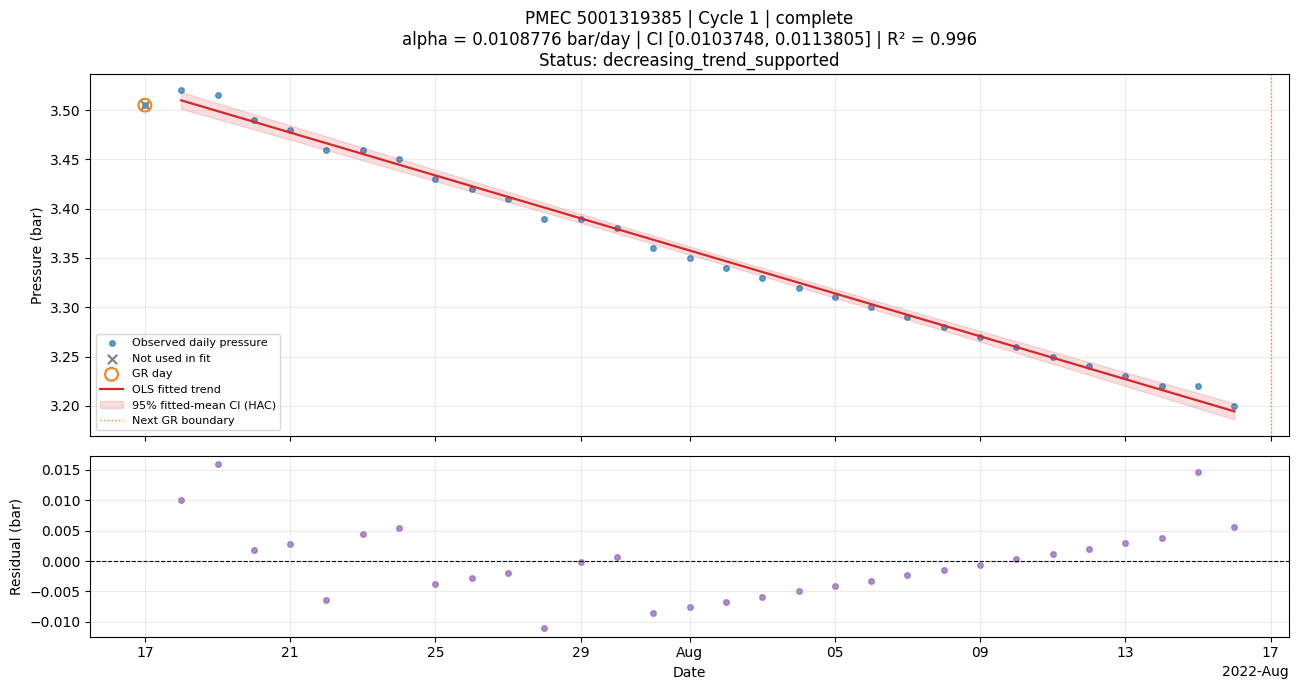

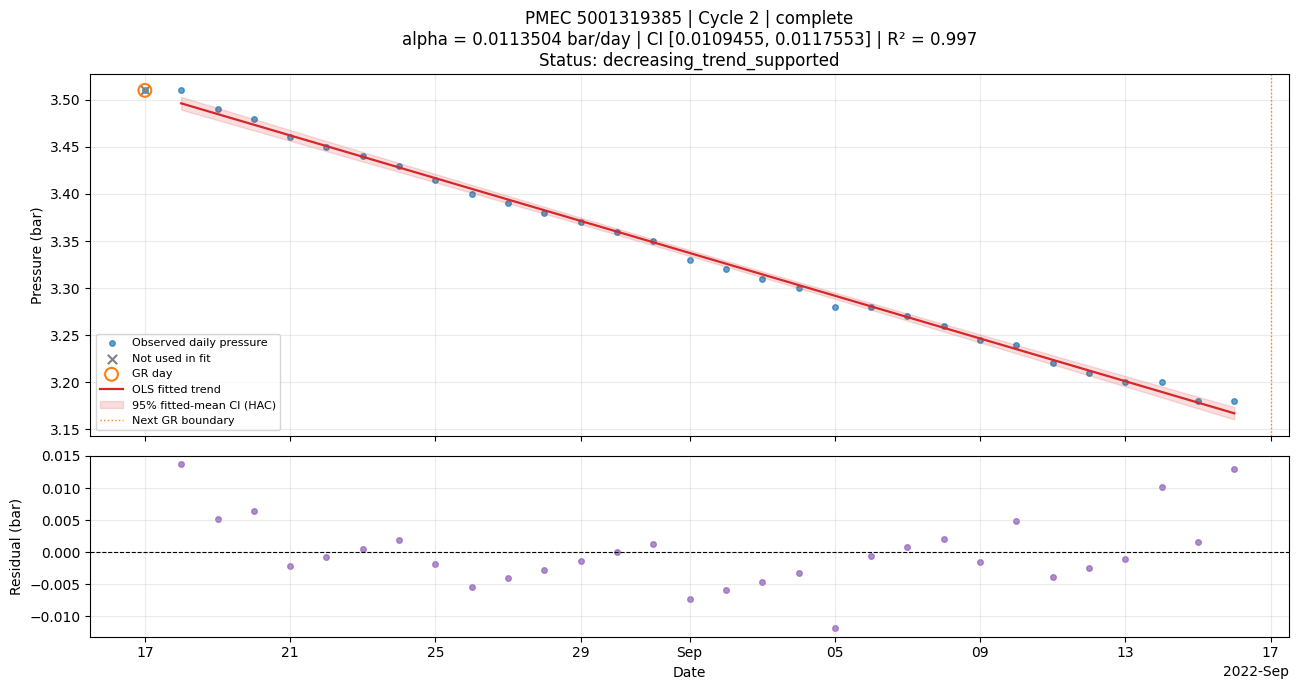

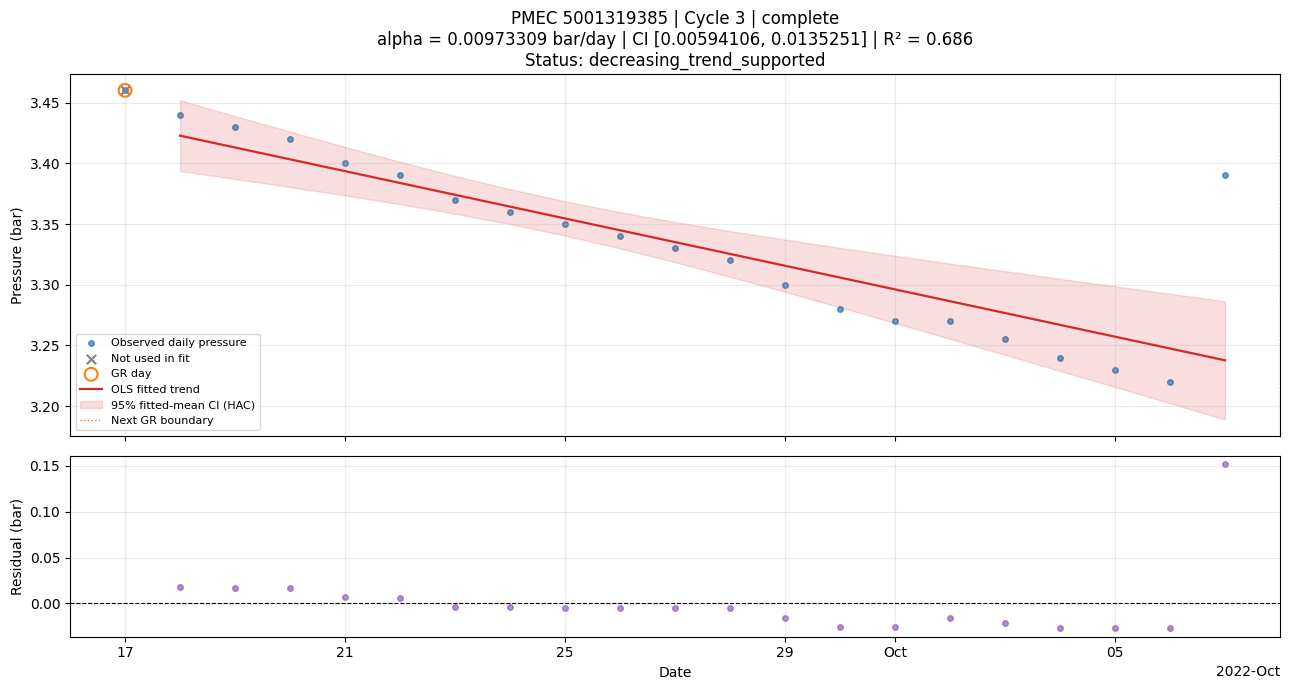

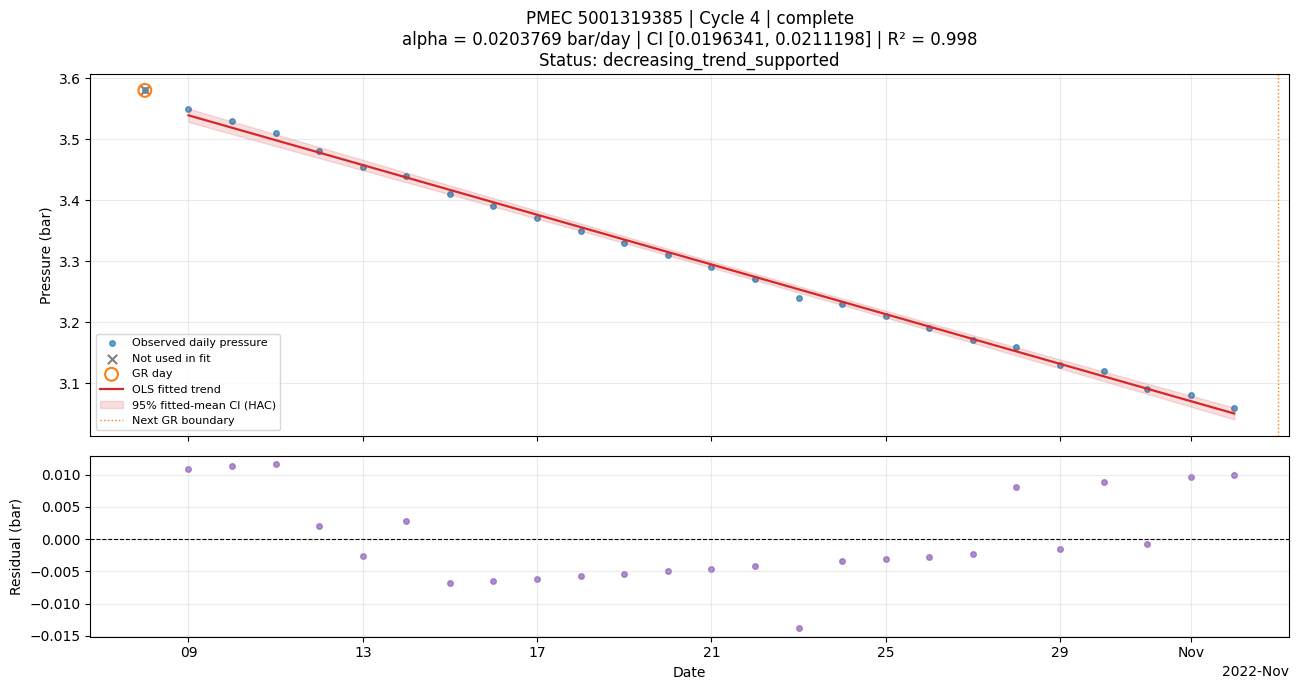

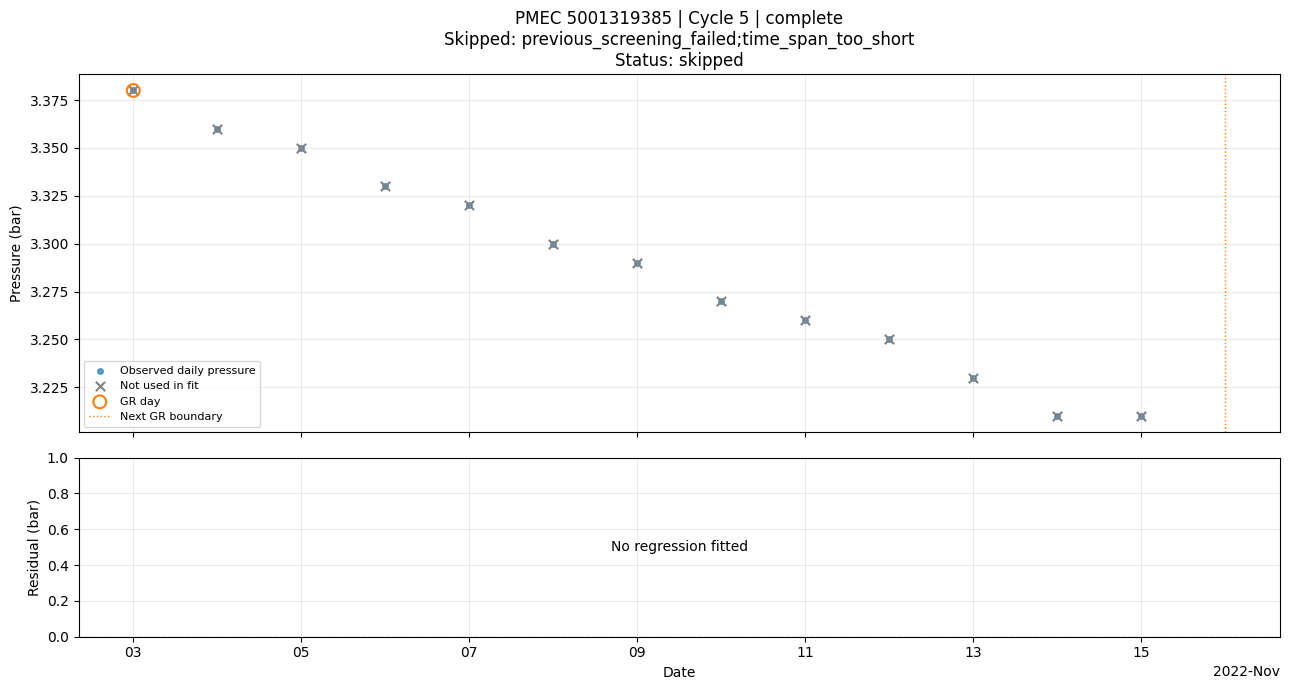

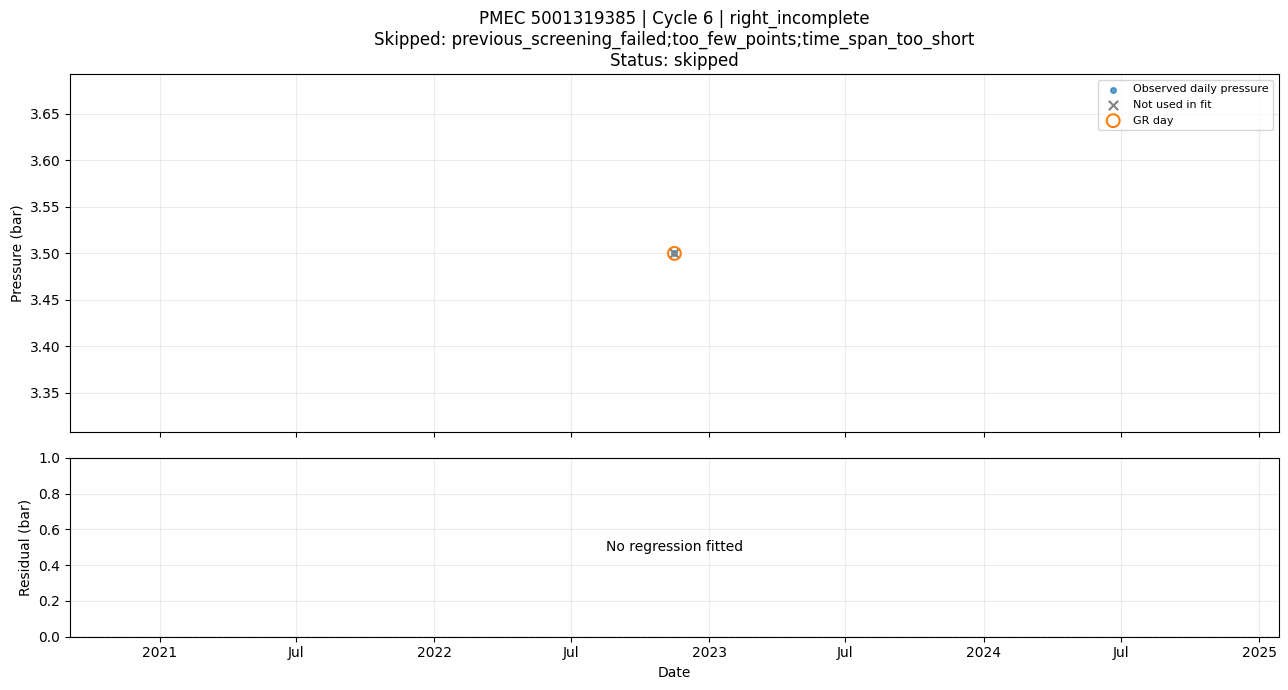

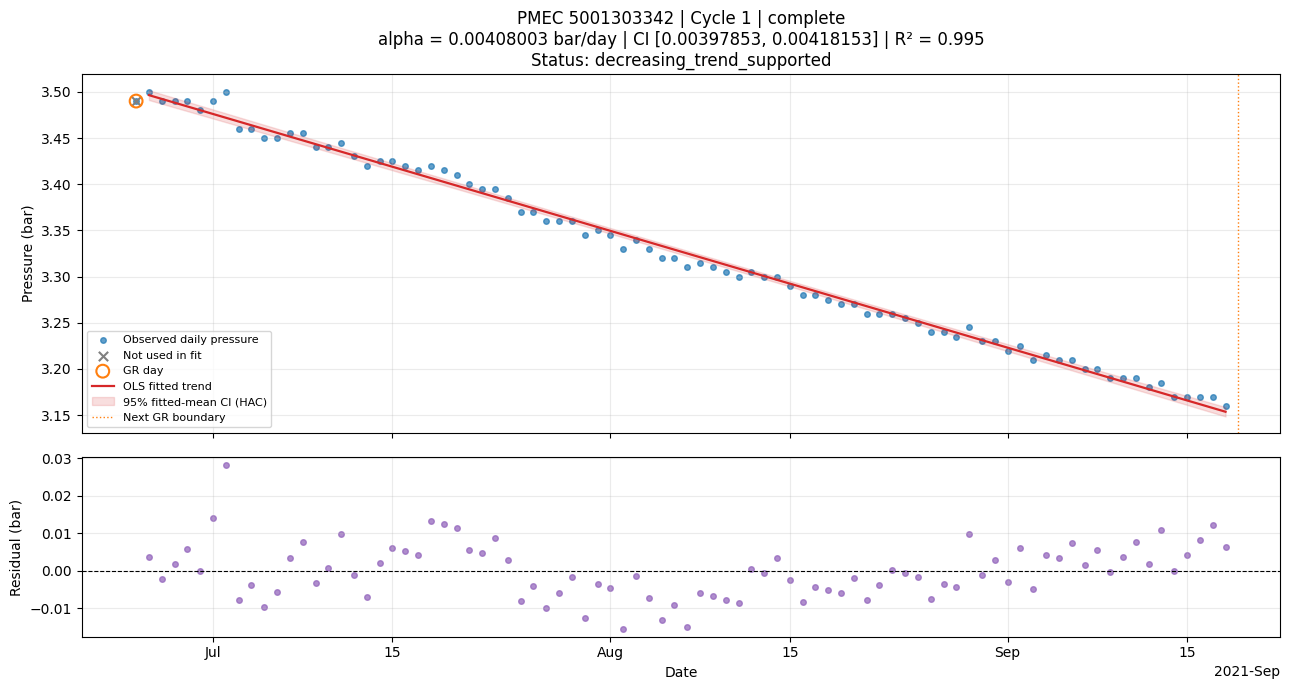

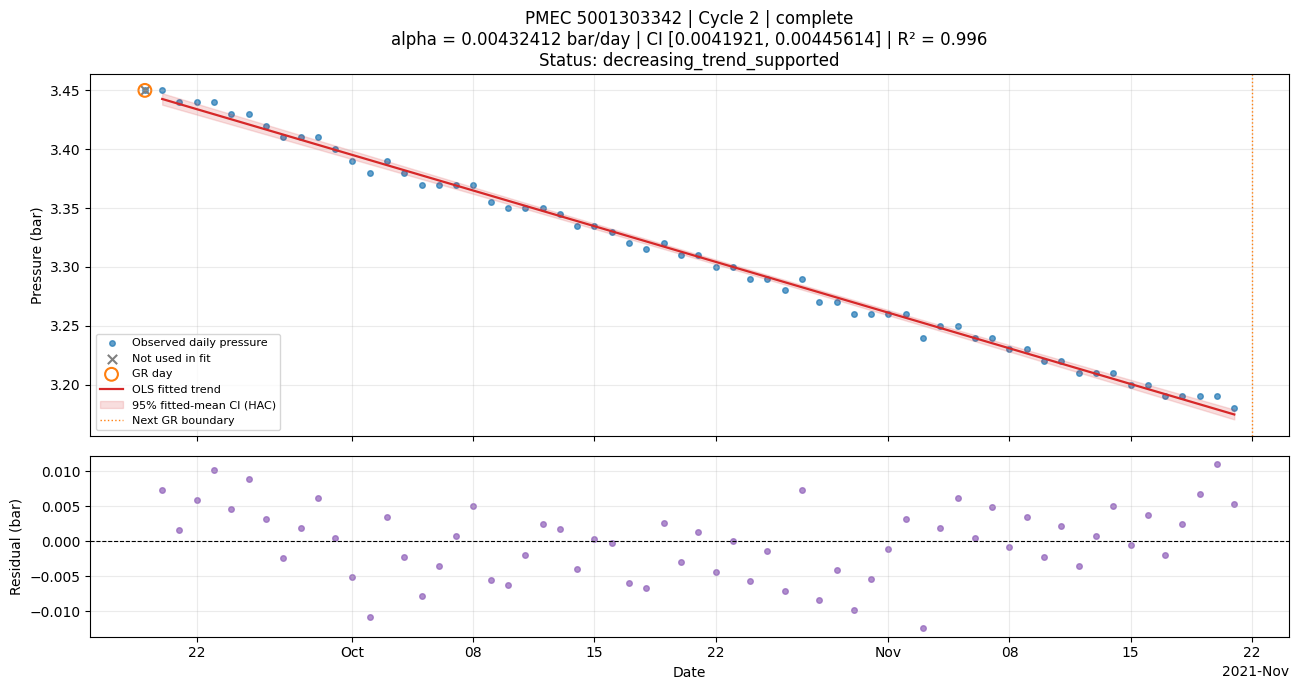

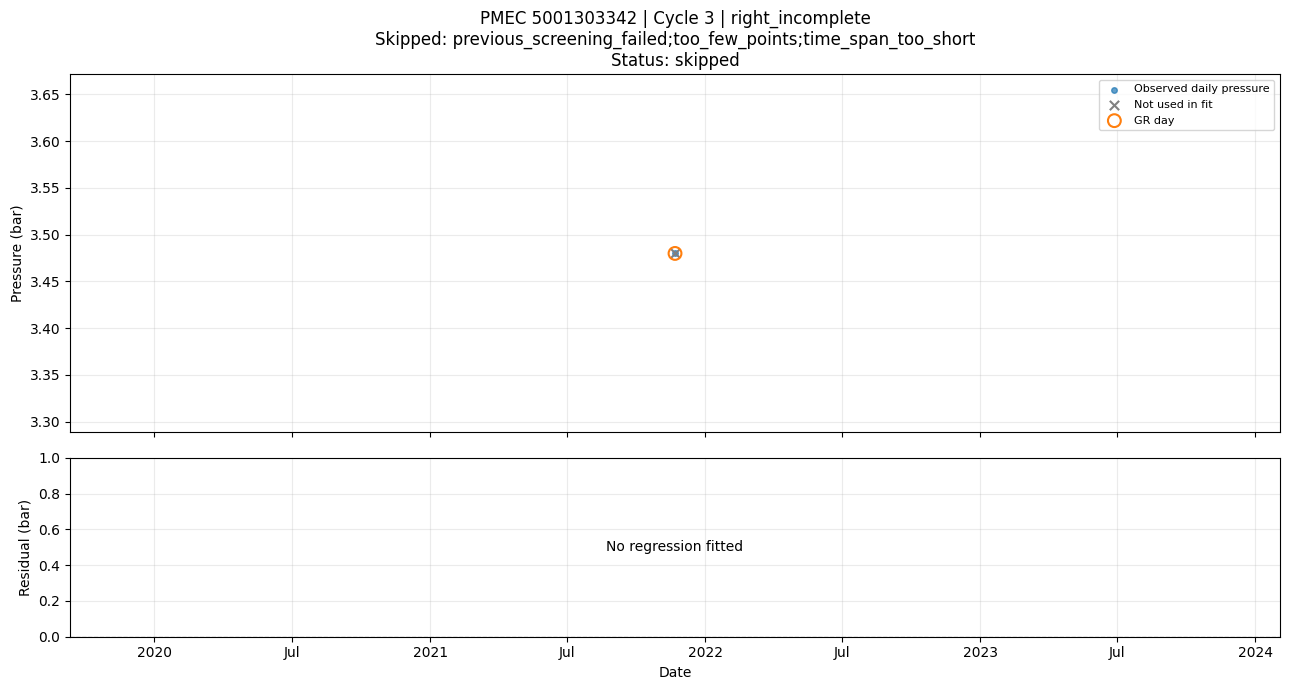

In [122]:
# linear regression and analysis for each cycle

from pathlib import Path
import re

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ============================================================
# 1. Input preparation
# ============================================================

def parse_boolean_column(series: pd.Series, name: str) -> pd.Series:
    """Support booleans read from memory or a saved CSV."""
    text = series.astype("string").str.strip().str.lower()

    mapping = {
        "true": True,
        "false": False,
        "1": True,
        "0": False,
        "1.0": True,
        "0.0": False,
    }

    parsed = text.map(mapping)

    if parsed.isna().any():
        bad_values = series.loc[parsed.isna()].unique()
        raise ValueError(
            f"Column '{name}' contains invalid boolean values: {bad_values}"
        )

    return parsed.astype(bool)


def prepare_cycle_fit_input(data: pd.DataFrame) -> pd.DataFrame:
    required = {
        "timestamp",
        "pmec_id",
        "pressure_obs",
        "cycle_id",
        "cycle_type",
        "GR executed",
    }

    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    result = data.copy()

    if result.empty:
        raise ValueError("Input cycle data is empty.")

    result["pmec_id"] = (
        result["pmec_id"].astype("string").str.strip()
    )

    if (
        result["pmec_id"].isna().any()
        or result["pmec_id"].eq("").any()
    ):
        raise ValueError("Missing or empty PMEC IDs.")

    result["timestamp"] = pd.to_datetime(
        result["timestamp"], errors="raise"
    ).dt.normalize()

    if result["timestamp"].isna().any():
        raise ValueError("Missing timestamps.")

    if result.duplicated(["pmec_id", "timestamp"]).any():
        raise ValueError(
            "Duplicate PMEC-day rows found. Use daily aggregated data."
        )

    cycle_ids = pd.to_numeric(result["cycle_id"], errors="raise")

    if (
        cycle_ids.isna().any()
        or not np.isfinite(cycle_ids.to_numpy(dtype=float)).all()
        or (cycle_ids < 0).any()
        or (cycle_ids != np.floor(cycle_ids)).any()
    ):
        raise ValueError("cycle_id must contain non-negative integers.")

    result["cycle_id"] = cycle_ids.astype(int)

    gr_flag = pd.to_numeric(result["GR executed"], errors="raise")

    if gr_flag.isna().any() or not gr_flag.isin([0, 1]).all():
        raise ValueError("GR executed must contain only 0 and 1.")

    result["GR executed"] = gr_flag.astype("int8")

    result["pressure_numeric"] = pd.to_numeric(
        result["pressure_obs"], errors="coerce"
    ).astype(float)

    if "use_for_fit" in result.columns:
        result["use_for_fit"] = parse_boolean_column(
            result["use_for_fit"], "use_for_fit"
        )
    else:
        result["use_for_fit"] = True

    if "fit_candidate" in result.columns:
        result["fit_candidate"] = parse_boolean_column(
            result["fit_candidate"], "fit_candidate"
        )

    valid_types = {
        "complete",
        "left_incomplete",
        "right_incomplete",
        "both_unknown",
    }

    if (
        result["cycle_type"].isna().any()
        or not result["cycle_type"].isin(valid_types).all()
    ):
        raise ValueError("Invalid or missing cycle_type.")

    for column in ["cycle_start_gr", "cycle_end_gr"]:
        if column in result.columns:
            result[column] = pd.to_datetime(
                result[column], errors="raise"
            )

    return (
        result.sort_values(["pmec_id", "cycle_id", "timestamp"])
        .reset_index(drop=True)
    )


# ============================================================
# 2. Cycle-by-cycle regression
# ============================================================

def fit_pressure_cycles(
    cycle_data: pd.DataFrame,
    min_fit_points: int = 10,
    min_fit_span_days: int = 14,
    confidence_level: float = 0.95,
    exclude_gr_day: bool = True,
    respect_previous_screening: bool = True,
    allow_both_unknown: bool = False,
    hac_maxlags: int = 7,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Fit pressure = intercept + slope * elapsed_calendar_days
    for each (pmec_id, cycle_id).

    alpha_hat = -slope, in bar/day.

    Returned tables:
        fit_summary:
            One row per cycle, including skipped cycles.
        fitted_data:
            All original rows plus fit-use flags, predictions and residuals.
    """

    if min_fit_points < 3:
        raise ValueError("min_fit_points must be at least 3.")

    if min_fit_span_days < 0:
        raise ValueError("min_fit_span_days must be non-negative.")

    if not 0 < confidence_level < 1:
        raise ValueError("confidence_level must be in (0, 1).")

    if hac_maxlags < 0:
        raise ValueError("hac_maxlags must be non-negative.")

    data = prepare_cycle_fit_input(cycle_data)

    # Initialize output columns, so rerunning replaces prior fit results.
    data["used_in_cycle_fit"] = False

    for column in [
        "days_from_fit_reference",
        "fitted_pressure",
        "fit_mean_ci_low",
        "fit_mean_ci_high",
        "residual",
    ]:
        data[column] = np.nan

    summaries = []

    for (pmec_id, cycle_id), group in data.groupby(
        ["pmec_id", "cycle_id"], sort=True
    ):
        if group["cycle_type"].nunique() != 1:
            raise ValueError(
                f"Inconsistent cycle_type: PMEC {pmec_id}, cycle {cycle_id}"
            )

        cycle_type = group["cycle_type"].iloc[0]

        finite_pressure = np.isfinite(
            group["pressure_numeric"].to_numpy()
        )

        eligible = (
            group["use_for_fit"]
            & pd.Series(finite_pressure, index=group.index)
        )

        if exclude_gr_day:
            eligible &= group["GR executed"].eq(0)

        fit_rows = group.loc[eligible].copy()
        n_fit = len(fit_rows)

        fit_span = (
            int(
                (
                    fit_rows["timestamp"].max()
                    - fit_rows["timestamp"].min()
                ).days
            )
            if n_fit >= 2
            else 0
        )

        record = {
            "pmec_id": pmec_id,
            "cycle_id": int(cycle_id),
            "cycle_type": cycle_type,
            "n_rows": len(group),
            "n_fit_points": n_fit,
            "fit_span_days": fit_span,
            "first_observation": group["timestamp"].min(),
            "last_observation": group["timestamp"].max(),
            "reference_date": pd.NaT,
            "fit_performed": False,
            "fit_status": "",
            "alpha_hat": np.nan,
            "alpha_se": np.nan,
            "alpha_ci_low": np.nan,
            "alpha_ci_high": np.nan,
            "intercept_hat": np.nan,
            "slope_hat": np.nan,
            "r_squared": np.nan,
            "residual_rmse": np.nan,
            "residual_mae": np.nan,
            "residual_sigma": np.nan,
            "residual_lag1_calendar_corr": np.nan,
            "n_lag1_pairs": 0,
            "covariance_method": "",
            "hac_lags": np.nan,
            "diagnostic_notes": "",
        }

        for column in ["cycle_start_gr", "cycle_end_gr"]:
            record[column] = (
                group[column].iloc[0]
                if column in group.columns
                else pd.NaT
            )

        skip_reasons = []

        if respect_previous_screening and "fit_candidate" in group.columns:
            if group["fit_candidate"].nunique() != 1:
                raise ValueError(
                    f"Inconsistent fit_candidate: {pmec_id}, {cycle_id}"
                )
            if not bool(group["fit_candidate"].iloc[0]):
                skip_reasons.append("previous_screening_failed")

        if cycle_type == "both_unknown" and not allow_both_unknown:
            skip_reasons.append("boundaries_unverified")

        if n_fit < min_fit_points:
            skip_reasons.append("too_few_points")

        if fit_span < min_fit_span_days:
            skip_reasons.append("time_span_too_short")

        if skip_reasons:
            record["fit_status"] = "skipped"
            record["diagnostic_notes"] = ";".join(skip_reasons)
            summaries.append(record)
            continue

        reference_date = fit_rows["timestamp"].min()

        x = (
            fit_rows["timestamp"] - reference_date
        ).dt.days.to_numpy(dtype=float)

        y = fit_rows["pressure_numeric"].to_numpy(dtype=float)

        X = np.column_stack([np.ones(n_fit), x])
        ols = sm.OLS(y, X).fit()

        day_gaps = (
            fit_rows["timestamp"].diff().dt.days.dropna()
        )
        consecutive_daily = bool(day_gaps.eq(1).all())

        notes = []

        if consecutive_daily:
            n_lags = min(hac_maxlags, n_fit - 2)

            inference = ols.get_robustcov_results(
                cov_type="HAC",
                maxlags=n_lags,
                use_correction=True,
                use_t=True,
            )

            covariance_method = "HAC"
        else:
            n_lags = np.nan

            inference = ols.get_robustcov_results(
                cov_type="HC3",
                use_t=True,
            )

            covariance_method = "HC3"
            notes.append("missing_days_autocorrelation_not_corrected")

        slope_hat = float(ols.params[1])
        alpha_hat = -slope_hat

        parameter_ci = np.asarray(
            inference.conf_int(alpha=1.0 - confidence_level)
        )
        slope_ci_low, slope_ci_high = parameter_ci[1]

        # Reversing sign also reverses the interval endpoints.
        alpha_ci_low = -float(slope_ci_high)
        alpha_ci_high = -float(slope_ci_low)

        residuals = np.asarray(ols.resid)
        sse = float(np.sum(residuals**2))
        rmse = float(np.sqrt(sse / n_fit))
        mae = float(np.mean(np.abs(residuals)))
        residual_sigma = float(np.sqrt(sse / (n_fit - 2)))

        # Genuine 1-calendar-day residual correlation.
        residual_series = pd.Series(
            residuals,
            index=pd.DatetimeIndex(fit_rows["timestamp"]),
        ).asfreq("D")

        lag_pairs = pd.concat(
            [
                residual_series.rename("current"),
                residual_series.shift(1).rename("previous"),
            ],
            axis=1,
        ).dropna()

        n_lag_pairs = len(lag_pairs)
        lag1_corr = np.nan

        if (
            n_lag_pairs >= 3
            and lag_pairs["current"].std() > 0
            and lag_pairs["previous"].std() > 0
        ):
            lag1_corr = float(
                lag_pairs["current"].corr(lag_pairs["previous"])
            )

        if alpha_ci_high < 0:
            fit_status = "increasing_pressure_review"
        elif alpha_ci_low > 0:
            fit_status = "decreasing_trend_supported"
        else:
            fit_status = "slope_uncertain"

        if (
            np.isfinite(lag1_corr)
            and abs(lag1_corr) > 0.5
        ):
            notes.append("strong_lag1_residual_correlation")

        if alpha_hat <= 0:
            notes.append("nonpositive_alpha_do_not_force_positive")

        # Avoid reporting numerical R² for essentially constant pressure.
        r_squared = (
            float(ols.rsquared)
            if np.ptp(y) > 1e-12
            else np.nan
        )

        if not np.isfinite(r_squared):
            notes.append("nearly_constant_pressure")

        # Evaluate the fitted mean on all recorded days of this cycle.
        x_all = (
            group["timestamp"] - reference_date
        ).dt.days.to_numpy(dtype=float)

        X_all = np.column_stack([
            np.ones(len(group)),
            x_all,
        ])

        prediction = inference.get_prediction(
            X_all
        ).summary_frame(alpha=1.0 - confidence_level)

        data.loc[group.index, "days_from_fit_reference"] = x_all
        data.loc[group.index, "fitted_pressure"] = (
            prediction["mean"].to_numpy()
        )
        data.loc[group.index, "fit_mean_ci_low"] = (
            prediction["mean_ci_lower"].to_numpy()
        )
        data.loc[group.index, "fit_mean_ci_high"] = (
            prediction["mean_ci_upper"].to_numpy()
        )

        # Only actual fit points receive regression residuals.
        data.loc[fit_rows.index, "used_in_cycle_fit"] = True
        data.loc[fit_rows.index, "residual"] = residuals

        record.update({
            "reference_date": reference_date,
            "fit_performed": True,
            "fit_status": fit_status,
            "alpha_hat": alpha_hat,
            "alpha_se": float(inference.bse[1]),
            "alpha_ci_low": alpha_ci_low,
            "alpha_ci_high": alpha_ci_high,
            "intercept_hat": float(ols.params[0]),
            "slope_hat": slope_hat,
            "r_squared": r_squared,
            "residual_rmse": rmse,
            "residual_mae": mae,
            "residual_sigma": residual_sigma,
            "residual_lag1_calendar_corr": lag1_corr,
            "n_lag1_pairs": n_lag_pairs,
            "covariance_method": covariance_method,
            "hac_lags": n_lags,
            "diagnostic_notes": ";".join(notes) if notes else "none",
        })

        summaries.append(record)

    fit_summary = pd.DataFrame(summaries)

    data = data.merge(
        fit_summary[
            ["pmec_id", "cycle_id", "fit_performed", "fit_status"]
        ],
        on=["pmec_id", "cycle_id"],
        how="left",
        validate="many_to_one",
    )

    return fit_summary, data


# ============================================================
# 3. Plot each cycle for specified PMECs
# ============================================================

def plot_cycle_fits(
    fitted_data: pd.DataFrame,
    fit_summary: pd.DataFrame,
    pmec_ids: list[str],
    output_dir: str | Path = "cycle_fit_results/plots",
    show: bool = True,
    save: bool = True,
    plot_skipped: bool = True,
    confidence_level: float = 0.95,
) -> None:
    output_dir = Path(output_dir)

    if save:
        output_dir.mkdir(parents=True, exist_ok=True)

    selected_ids = list(
        dict.fromkeys(str(x).strip() for x in pmec_ids)
    )

    for pmec_id in selected_ids:
        pmec_summary = fit_summary.loc[
            fit_summary["pmec_id"] == pmec_id
        ]

        if pmec_summary.empty:
            print(f"PMEC {pmec_id}: not found.")
            continue

        for _, record in pmec_summary.iterrows():
            performed = bool(record["fit_performed"])

            if not performed and not plot_skipped:
                continue

            cycle_id = int(record["cycle_id"])

            group = fitted_data.loc[
                (fitted_data["pmec_id"] == pmec_id)
                & (fitted_data["cycle_id"] == cycle_id)
            ].sort_values("timestamp")

            used = group.loc[group["used_in_cycle_fit"]]
            excluded = group.loc[~group["used_in_cycle_fit"]]

            fig, (ax_pressure, ax_residual) = plt.subplots(
                2,
                1,
                figsize=(13, 7),
                sharex=True,
                gridspec_kw={"height_ratios": [2, 1]},
            )

            ax_pressure.scatter(
                group["timestamp"],
                group["pressure_numeric"],
                s=16,
                color="tab:blue",
                alpha=0.7,
                label="Observed daily pressure",
            )

            if not excluded.empty:
                ax_pressure.scatter(
                    excluded["timestamp"],
                    excluded["pressure_numeric"],
                    s=45,
                    marker="x",
                    color="gray",
                    label="Not used in fit",
                )

            gr_rows = group.loc[group["GR executed"] == 1]

            if not gr_rows.empty:
                ax_pressure.scatter(
                    gr_rows["timestamp"],
                    gr_rows["pressure_numeric"],
                    s=85,
                    facecolors="none",
                    edgecolors="tab:orange",
                    linewidths=1.5,
                    label="GR day",
                )

            if performed:
                # Display the regression only over the fitted date range.
                line_rows = group.loc[
                    group["timestamp"].between(
                        used["timestamp"].min(),
                        used["timestamp"].max(),
                    )
                ]

                ax_pressure.plot(
                    line_rows["timestamp"],
                    line_rows["fitted_pressure"],
                    color="tab:red",
                    linewidth=1.6,
                    label="OLS fitted trend",
                )

                ax_pressure.fill_between(
                    line_rows["timestamp"],
                    line_rows["fit_mean_ci_low"].to_numpy(dtype=float),
                    line_rows["fit_mean_ci_high"].to_numpy(dtype=float),
                    color="tab:red",
                    alpha=0.15,
                    label=(
                        f"{confidence_level:.0%} fitted-mean CI "
                        f"({record['covariance_method']})"
                    ),
                )

                ax_residual.scatter(
                    used["timestamp"],
                    used["residual"],
                    s=16,
                    color="tab:purple",
                    alpha=0.75,
                )

                title_detail = (
                    f"alpha = {record['alpha_hat']:.6g} bar/day | "
                    f"CI [{record['alpha_ci_low']:.6g}, "
                    f"{record['alpha_ci_high']:.6g}] | "
                    f"R² = {record['r_squared']:.3f}"
                )
            else:
                title_detail = (
                    f"Skipped: {record['diagnostic_notes']}"
                )

                ax_residual.text(
                    0.5, 0.5,
                    "No regression fitted",
                    transform=ax_residual.transAxes,
                    ha="center",
                    va="center",
                )

            end_gr = record.get("cycle_end_gr", pd.NaT)

            if pd.notna(end_gr):
                ax_pressure.axvline(
                    pd.Timestamp(end_gr),
                    color="tab:orange",
                    linestyle=":",
                    linewidth=1,
                    label="Next GR boundary",
                )

            ax_pressure.set_title(
                f"PMEC {pmec_id} | Cycle {cycle_id} | "
                f"{record['cycle_type']}\n"
                f"{title_detail}\n"
                f"Status: {record['fit_status']}"
            )
            ax_pressure.set_ylabel("Pressure (bar)")
            ax_pressure.legend(loc="best", fontsize=8)

            ax_residual.axhline(
                0, color="black", linewidth=0.8, linestyle="--"
            )
            ax_residual.set_ylabel("Residual (bar)")
            ax_residual.set_xlabel("Date")

            for ax in [ax_pressure, ax_residual]:
                ax.grid(alpha=0.25)

            locator = mdates.AutoDateLocator()
            ax_residual.xaxis.set_major_locator(locator)
            ax_residual.xaxis.set_major_formatter(
                mdates.ConciseDateFormatter(locator)
            )

            fig.tight_layout()

            if save:
                safe_id = re.sub(
                    r"[^A-Za-z0-9_.-]+", "_", pmec_id
                )
                fig.savefig(
                    output_dir / f"{safe_id}_cycle_{cycle_id}.png",
                    dpi=180,
                    bbox_inches="tight",
                )

            if show:
                plt.show()

            plt.close(fig)


# ============================================================
# 4. Execution
# ============================================================

INPUT_PATH = "cycle_results/pressure_data_with_cycles.csv"
OUTPUT_DIR = Path("cycle_fit_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cycle_data = pd.read_csv(
    INPUT_PATH,
    dtype={"pmec_id": "string"},
    encoding="utf-8-sig",
)

CONFIDENCE_LEVEL = 0.95

fit_summary, fitted_data = fit_pressure_cycles(
    cycle_data=cycle_data,
    min_fit_points=10,
    min_fit_span_days=14,
    confidence_level=CONFIDENCE_LEVEL,
    exclude_gr_day=True,
    respect_previous_screening=True,
    allow_both_unknown=False,
    hac_maxlags=7,
)

fit_summary.to_csv(
    OUTPUT_DIR / "cycle_fit_summary.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d",
)

fitted_data.to_csv(
    OUTPUT_DIR / "pressure_data_with_cycle_fits.csv",
    index=False,
    encoding="utf-8-sig",
    date_format="%Y-%m-%d",
)

summary_columns = [
    "pmec_id",
    "cycle_id",
    "cycle_type",
    "n_fit_points",
    "fit_span_days",
    "alpha_hat",
    "alpha_ci_low",
    "alpha_ci_high",
    "r_squared",
    "residual_rmse",
    "covariance_method",
    "fit_status",
    "diagnostic_notes",
]

print("\nCycle-by-cycle regression summary:")
print(fit_summary[summary_columns].to_string(index=False))

print("\nFit status counts:")
print(
    fit_summary.groupby(["pmec_id", "fit_status"])
    .size()
    .unstack(fill_value=0)
    .to_string()
)

# Replace with the PMECs you want to inspect.
PMEC_IDS_TO_PLOT = [
    "5001319385",
    "5001303342",
]

plot_cycle_fits(
    fitted_data=fitted_data,
    fit_summary=fit_summary,
    pmec_ids=PMEC_IDS_TO_PLOT,
    output_dir=OUTPUT_DIR / "plots",
    show=True,
    save=True,
    plot_skipped=True,
    confidence_level=CONFIDENCE_LEVEL,
)














   pmec_id  cycle_id                status filter_start filter_end  n_observations  alpha_last  alpha_std_last
5001303342         1              filtered   2021-06-26 2021-09-18              85     0.00404        0.000231
5001303342         2              filtered   2021-09-20 2021-11-21              63     0.00433        0.000275
5001303342         3 no_non_gr_observation          NaT        NaT               0         NaN             NaN


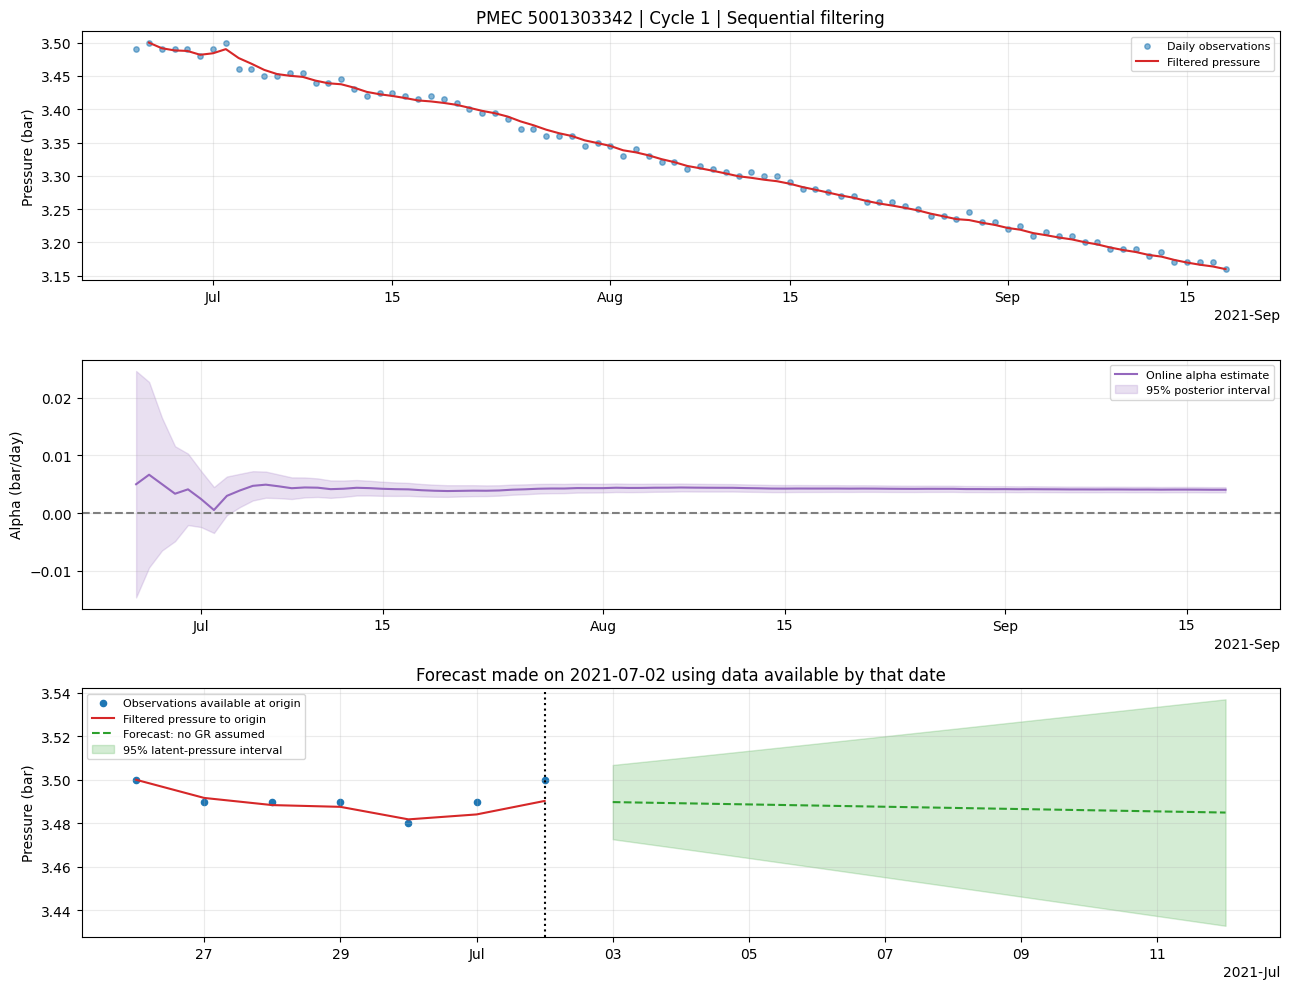

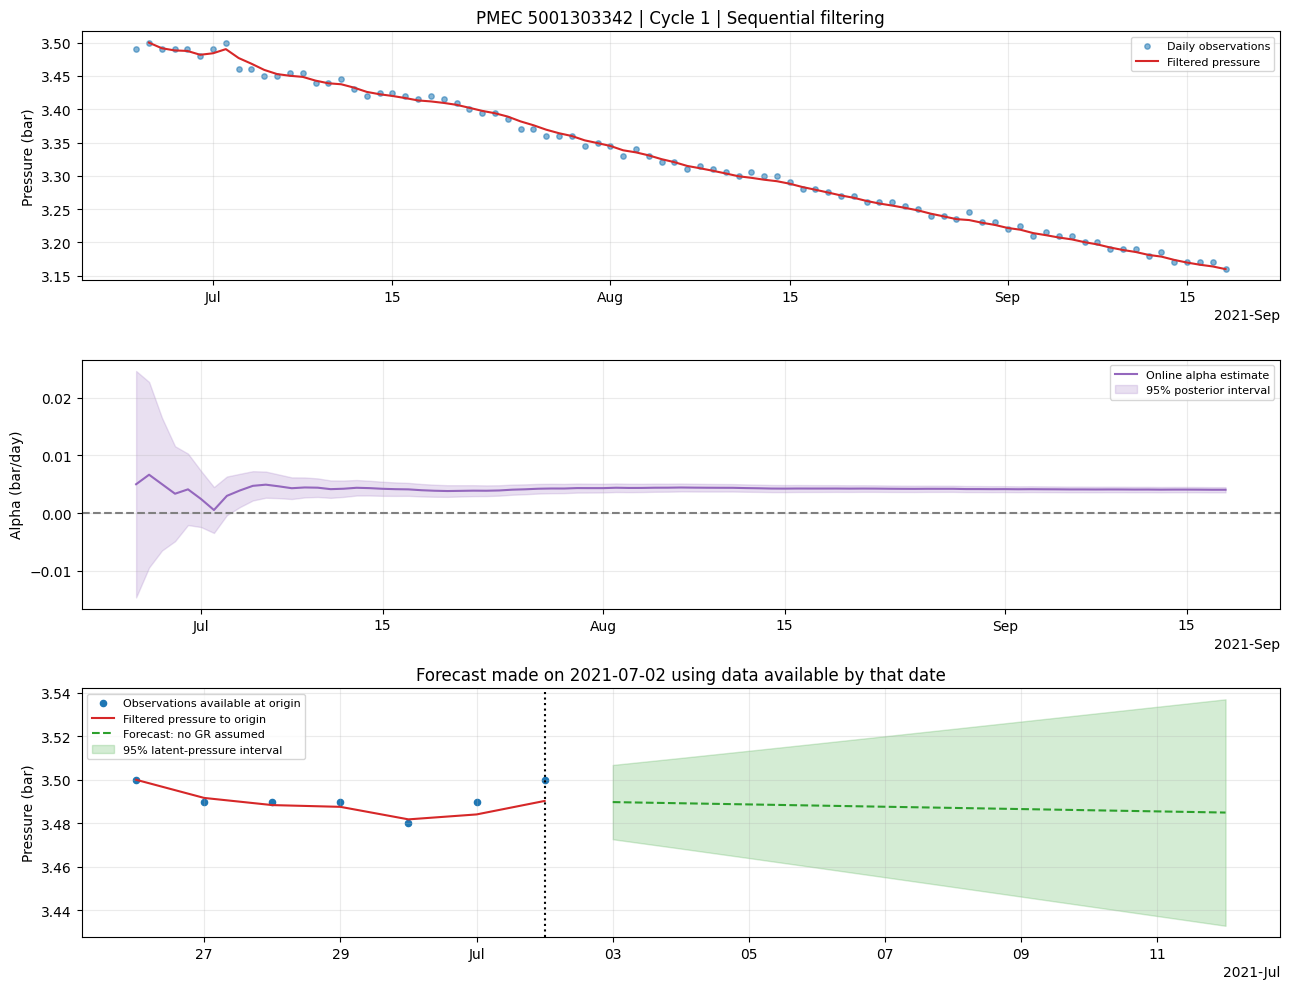

In [123]:
# kalman filter

from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# ============================================================
# 1. Initial settings: illustrative, not calibrated
# ============================================================

@dataclass
class KFConfig:
    alpha_prior_mean: float = 0.005       # bar/day
    alpha_prior_std: float = 0.010        # bar/day
    measurement_std: float = 0.010        # bar, for DAILY observations
    process_pressure_std: float = 0.002   # bar per daily step
    forecast_horizon: int = 10
    confidence_level: float = 0.95
    safety_pressure: float = 3.0


def load_cycle_data(csv_path):
    data = pd.read_csv(
        csv_path,
        dtype={"pmec_id": "string"},
        encoding="utf-8-sig",
    )

    required = {
        "timestamp", "pmec_id", "pressure_obs",
        "cycle_id", "GR executed",
    }

    missing = required.difference(data.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    data["pmec_id"] = data["pmec_id"].str.strip()
    data["timestamp"] = pd.to_datetime(
        data["timestamp"], errors="raise"
    ).dt.normalize()

    if (
        data["timestamp"].isna().any()
        or data["pmec_id"].isna().any()
        or data["pmec_id"].eq("").any()
    ):
        raise ValueError("Missing date or PMEC ID.")

    cycle_ids = pd.to_numeric(data["cycle_id"], errors="raise")
    if (
        cycle_ids.isna().any()
        or not np.isfinite(cycle_ids.to_numpy(dtype=float)).all()
        or (cycle_ids < 0).any()
        or (cycle_ids != np.floor(cycle_ids)).any()
    ):
        raise ValueError("cycle_id must contain non-negative integers.")
    data["cycle_id"] = cycle_ids.astype(int)

    flags = pd.to_numeric(data["GR executed"], errors="raise")
    if flags.isna().any() or not flags.isin([0, 1]).all():
        raise ValueError("GR executed must contain only 0 and 1.")
    data["GR executed"] = flags.astype(int)

    data["pressure_obs"] = pd.to_numeric(
        data["pressure_obs"], errors="coerce"
    ).astype(float)

    data.loc[
        ~np.isfinite(data["pressure_obs"]), "pressure_obs"
    ] = np.nan

    if data.duplicated(["pmec_id", "timestamp"]).any():
        raise ValueError("Duplicate PMEC-day rows found.")

    if "cycle_start_gr" in data.columns:
        data["cycle_start_gr"] = pd.to_datetime(
            data["cycle_start_gr"], errors="raise"
        )

    return data.sort_values(
        ["pmec_id", "cycle_id", "timestamp"]
    ).reset_index(drop=True)


# ============================================================
# 2. Kalman operations
# ============================================================

def predict_one_day(x, P, Q):
    F = np.array([[1.0, -1.0], [0.0, 1.0]])
    x_next = F @ x
    P_next = F @ P @ F.T + Q
    return x_next, (P_next + P_next.T) / 2.0


def update_pressure(x, P, y, R):
    innovation = float(y - x[0])
    innovation_var = float(P[0, 0] + R)

    K = P[:, 0] / innovation_var
    x_new = x + K * innovation

    H = np.array([1.0, 0.0])
    A = np.eye(2) - np.outer(K, H)

    P_new = A @ P @ A.T + np.outer(K, K) * R
    P_new = (P_new + P_new.T) / 2.0

    return x_new, P_new, innovation, innovation_var


# ============================================================
# 3. Sequential filtering and rolling forecasts
# ============================================================

def run_cycle_kalman(
    cycle_data,
    cfg,
    pmec_ids=None,
):
    if cfg.measurement_std <= 0 or cfg.alpha_prior_std <= 0:
        raise ValueError("Measurement and alpha prior std must be positive.")
    if cfg.process_pressure_std < 0:
        raise ValueError("Process std cannot be negative.")
    if cfg.forecast_horizon < 1:
        raise ValueError("forecast_horizon must be at least 1.")
    if not 0 < cfg.confidence_level < 1:
        raise ValueError("confidence_level must be in (0,1).")

    data = cycle_data.copy()

    if pmec_ids is not None:
        selected = [str(x).strip() for x in pmec_ids]
        data = data.loc[data["pmec_id"].isin(selected)].copy()

    if data.empty:
        raise ValueError("No selected data.")

    R = cfg.measurement_std**2
    Q = np.diag([cfg.process_pressure_std**2, 0.0])

    z = norm.ppf(0.5 + cfg.confidence_level / 2.0)
    z_one_sided = norm.ppf(cfg.confidence_level)

    state_rows = []
    forecast_rows = []
    cycle_rows = []

    for (pmec_id, cycle_id), group in data.groupby(
        ["pmec_id", "cycle_id"], sort=True
    ):
        group = group.sort_values("timestamp").copy()

        # GR-day daily aggregates are excluded.
        usable = group.loc[
            group["GR executed"].eq(0)
            & group["pressure_obs"].notna()
        ]

        if usable.empty:
            cycle_rows.append({
                "pmec_id": pmec_id,
                "cycle_id": cycle_id,
                "status": "no_non_gr_observation",
                "n_observations": 0,
            })
            continue

        start = usable["timestamp"].iloc[0]
        end = group["timestamp"].max()

        observations = usable.set_index("timestamp")["pressure_obs"]

        # Diffuse-pressure initialization using the first observation once.
        # This starts the filter at start, not one day before start.
        x = np.array([
            float(observations.loc[start]),
            cfg.alpha_prior_mean,
        ])
        P = np.diag([R, cfg.alpha_prior_std**2])

        n_observations = 0

        for date in pd.date_range(start, end, freq="D"):
            innovation = np.nan
            innovation_var = np.nan
            y = float(observations.get(date, np.nan))
            initialization = date == start

            if initialization:
                n_observations = 1
            else:
                x, P = predict_one_day(x, P, Q)

                if np.isfinite(y):
                    x, P, innovation, innovation_var = update_pressure(
                        x, P, y, R
                    )
                    n_observations += 1

            p_std = np.sqrt(max(float(P[0, 0]), 0.0))
            alpha_std = np.sqrt(max(float(P[1, 1]), 0.0))

            state_rows.append({
                "pmec_id": pmec_id,
                "cycle_id": int(cycle_id),
                "timestamp": date,
                "pressure_obs": y,
                "is_initialization": initialization,
                "has_observation": np.isfinite(y),
                "n_observations_seen": n_observations,
                "pressure_mean": float(x[0]),
                "pressure_std": p_std,
                "alpha_mean": float(x[1]),
                "alpha_std": alpha_std,
                "alpha_ci_low": float(x[1] - z * alpha_std),
                "alpha_ci_high": float(x[1] + z * alpha_std),
                "alpha_positive_probability": float(
                    norm.cdf(x[1] / max(alpha_std, 1e-15))
                ),
                "innovation": innovation,
                "innovation_std": (
                    np.sqrt(innovation_var)
                    if np.isfinite(innovation_var)
                    else np.nan
                ),
                "standardized_innovation": (
                    innovation / np.sqrt(innovation_var)
                    if np.isfinite(innovation_var)
                    else np.nan
                ),
            })

            # Forecast conditional on no GR before each target date.
            xf, Pf = x.copy(), P.copy()

            for h in range(1, cfg.forecast_horizon + 1):
                xf, Pf = predict_one_day(xf, Pf, Q)

                state_std = np.sqrt(max(float(Pf[0, 0]), 0.0))
                observation_std = np.sqrt(
                    max(float(Pf[0, 0] + R), 0.0)
                )
                mu = float(xf[0])

                forecast_rows.append({
                    "pmec_id": pmec_id,
                    "cycle_id": int(cycle_id),
                    "forecast_origin": date,
                    "target_date": date + pd.Timedelta(days=h),
                    "h": h,
                    "pressure_mean": mu,
                    "pressure_state_std": state_std,
                    "pressure_obs_std": observation_std,
                    "pressure_state_ci_low": mu - z * state_std,
                    "pressure_state_ci_high": mu + z * state_std,
                    "pressure_obs_ci_low": mu - z * observation_std,
                    "pressure_obs_ci_high": mu + z * observation_std,
                    "pressure_one_sided_lower": (
                        mu - z_one_sided * state_std
                    ),
                    "endpoint_low_pressure_risk": float(
                        norm.cdf(
                            (cfg.safety_pressure - mu)
                            / max(state_std, 1e-15)
                        )
                    ),
                })

        cycle_rows.append({
            "pmec_id": pmec_id,
            "cycle_id": int(cycle_id),
            "status": "filtered",
            "filter_start": start,
            "filter_end": end,
            "n_observations": n_observations,
            "alpha_last": float(x[1]),
            "alpha_std_last": np.sqrt(max(float(P[1, 1]), 0.0)),
        })

    return (
        pd.DataFrame(state_rows),
        pd.DataFrame(forecast_rows),
        pd.DataFrame(cycle_rows),
    )


# ============================================================
# 4. Plot one cycle and a forecast made on one selected date
# ============================================================

def plot_online_cycle(
    cycle_data,
    states,
    forecasts,
    pmec_id,
    cycle_id,
    forecast_date=None,
    observations_to_use=7,
    confidence_level=0.95,
):
    pmec_id = str(pmec_id).strip()

    raw = cycle_data.loc[
        cycle_data["pmec_id"].eq(pmec_id)
        & cycle_data["cycle_id"].eq(cycle_id)
    ].sort_values("timestamp")

    s = states.loc[
        states["pmec_id"].eq(pmec_id)
        & states["cycle_id"].eq(cycle_id)
    ].sort_values("timestamp")

    if s.empty:
        raise ValueError("This cycle has no initialized filter.")

    if forecast_date is None:
        observed_states = s.loc[s["has_observation"]]
        k = min(observations_to_use, len(observed_states)) - 1
        if k < 0:
            raise ValueError("No observations.")
        origin = observed_states.iloc[k]["timestamp"]
    else:
        origin = pd.Timestamp(forecast_date).normalize()

    if not s["timestamp"].eq(origin).any():
        raise ValueError("forecast_date is outside the filtered dates.")

    f = forecasts.loc[
        forecasts["pmec_id"].eq(pmec_id)
        & forecasts["cycle_id"].eq(cycle_id)
        & forecasts["forecast_origin"].eq(origin)
    ].sort_values("target_date")

    past = s.loc[s["timestamp"] <= origin]

    fig, axes = plt.subplots(3, 1, figsize=(13, 10))

    # Full-period filtering: no future observations enter each state update.
    axes[0].scatter(
        raw["timestamp"], raw["pressure_obs"],
        s=15, alpha=0.55, label="Daily observations"
    )
    axes[0].plot(
        s["timestamp"], s["pressure_mean"],
        color="tab:red", label="Filtered pressure"
    )
    axes[0].set_ylabel("Pressure (bar)")
    axes[0].set_title(
        f"PMEC {pmec_id} | Cycle {cycle_id} | Sequential filtering"
    )

    axes[1].plot(
        s["timestamp"], s["alpha_mean"],
        color="tab:purple", label="Online alpha estimate"
    )
    axes[1].fill_between(
        s["timestamp"],
        s["alpha_ci_low"].to_numpy(dtype=float),
        s["alpha_ci_high"].to_numpy(dtype=float),
        alpha=0.2, color="tab:purple",
        label=f"{confidence_level:.0%} posterior interval",
    )
    axes[1].axhline(0, color="gray", linestyle="--")
    axes[1].set_ylabel("Alpha (bar/day)")

    # Show only observations at/before the forecast origin.
    axes[2].scatter(
        past["timestamp"], past["pressure_obs"],
        s=20, label="Observations available at origin"
    )
    axes[2].plot(
        past["timestamp"], past["pressure_mean"],
        color="tab:red", label="Filtered pressure to origin"
    )
    axes[2].plot(
        f["target_date"], f["pressure_mean"],
        "--", color="tab:green", label="Forecast: no GR assumed"
    )
    axes[2].fill_between(
        f["target_date"],
        f["pressure_state_ci_low"].to_numpy(dtype=float),
        f["pressure_state_ci_high"].to_numpy(dtype=float),
        alpha=0.2, color="tab:green",
        label=f"{confidence_level:.0%} latent-pressure interval",
    )
    axes[2].axvline(origin, color="black", linestyle=":")
    axes[2].set_title(
        f"Forecast made on {origin.date()} using data available by that date"
    )
    axes[2].set_ylabel("Pressure (bar)")

    for ax in axes:
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)
        locator = mdates.AutoDateLocator()
        ax.xaxis.set_major_locator(locator)
        ax.xaxis.set_major_formatter(
            mdates.ConciseDateFormatter(locator)
        )

    fig.tight_layout()
    plt.show()
    return fig


# ============================================================
# 5. Run
# ============================================================

data = load_cycle_data(
    "cycle_results/pressure_data_with_cycles.csv"
)

# Start with one PMEC; replace with your selected IDs if needed.
PMEC_IDS = ["5001303342"]

cfg = KFConfig(
    alpha_prior_mean=0.005,
    alpha_prior_std=0.010,
    measurement_std=0.010,
    process_pressure_std=0.002,
    forecast_horizon=10,
    confidence_level=0.95,
    safety_pressure=3.0,
)

states, forecasts, run_summary = run_cycle_kalman(
    cycle_data=data,
    cfg=cfg,
    pmec_ids=PMEC_IDS,
)

output_dir = Path("output/kalman_results")
output_dir.mkdir(parents=True, exist_ok=True)

states.to_csv(
    output_dir / "online_states.csv",
    index=False,
    date_format="%Y-%m-%d",
)
forecasts.to_csv(
    output_dir / "rolling_forecasts.csv",
    index=False,
    date_format="%Y-%m-%d",
)
run_summary.to_csv(
    output_dir / "filter_summary.csv",
    index=False,
    date_format="%Y-%m-%d",
)

print(run_summary.to_string(index=False))

plot_online_cycle(
    cycle_data=data,
    states=states,
    forecasts=forecasts,
    pmec_id="5001303342",
    cycle_id=1,
    observations_to_use=7,
    confidence_level=cfg.confidence_level,
)

In [124]:
# predict values vs actual values
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import norm


# ============================================================
# 1. Helpers
# ============================================================

def require_columns(data, required, table_name):
    missing = set(required).difference(data.columns)
    if missing:
        raise ValueError(
            f"{table_name} 缺少字段：{sorted(missing)}"
        )


def parse_integer_column(series, name, minimum=0):
    values = pd.to_numeric(series, errors="raise")

    array = values.to_numpy(dtype=float, na_value=np.nan)

    if (
        not np.isfinite(array).all()
        or (array < minimum).any()
        or (array != np.floor(array)).any()
    ):
        raise ValueError(
            f"{name} 必须是大于等于 {minimum} 的整数。"
        )

    return values.astype("int64")


def parse_daily_dates(series, name):
    values = pd.to_datetime(series, errors="raise")

    if values.isna().any():
        raise ValueError(f"{name} 存在空日期。")

    return values.dt.normalize()


# ============================================================
# 2. Build forecast-observation comparison tables
# ============================================================

def build_forecast_observation_table(
    forecasts_csv_path,
    cycle_data_csv_path,
    output_dir="output/forecast_evaluation",
    pmec_ids=None,
    central_coverage=0.95,
    lower_tail_probability=0.05,
):
    """
    建立历史滚动预测与后续实际观测的对照表。

    输入预测表：
        pmec_id
        cycle_id
        forecast_origin
        target_date
        h
        pressure_mean
        pressure_state_std
        pressure_obs_std

    输入实际压力表：
        pmec_id
        timestamp
        cycle_id
        pressure_obs
        GR executed

    返回：
        comparison_all:
            所有预测，包含有效性及未参与评估原因。

        evaluation_valid:
            可以用于评估的预测—观测对。

        reason_summary:
            各 PMEC 的匹配状态统计。

    注意：
        不填补实际压力缺失值。
        不修改预测值。
        不使用补气后的观测评价补气前的无干预预测。
    """

    if not 0 < central_coverage < 1:
        raise ValueError("central_coverage 必须在 (0, 1) 内。")

    if not 0 < lower_tail_probability < 0.5:
        raise ValueError(
            "lower_tail_probability 必须在 (0, 0.5) 内。"
        )

    # --------------------------------------------------------
    # A. Read input files
    # --------------------------------------------------------

    forecasts = pd.read_csv(
        forecasts_csv_path,
        dtype={"pmec_id": "string"},
        encoding="utf-8-sig",
    )

    observations = pd.read_csv(
        cycle_data_csv_path,
        dtype={"pmec_id": "string"},
        encoding="utf-8-sig",
    )

    require_columns(
        forecasts,
        [
            "pmec_id",
            "cycle_id",
            "forecast_origin",
            "target_date",
            "h",
            "pressure_mean",
            "pressure_state_std",
            "pressure_obs_std",
        ],
        "预测表",
    )

    require_columns(
        observations,
        [
            "pmec_id",
            "timestamp",
            "cycle_id",
            "pressure_obs",
            "GR executed",
        ],
        "压力观测表",
    )

    # --------------------------------------------------------
    # B. Standardize IDs and select PMECs
    # --------------------------------------------------------

    for table_name, table in [
        ("预测表", forecasts),
        ("压力观测表", observations),
    ]:
        table["pmec_id"] = table["pmec_id"].str.strip()

        if (
            table["pmec_id"].isna().any()
            or table["pmec_id"].eq("").any()
        ):
            raise ValueError(f"{table_name} 中存在空 PMEC 编号。")

    if pmec_ids is not None:
        selected_ids = list(
            dict.fromkeys(str(x).strip() for x in pmec_ids)
        )

        forecasts = forecasts.loc[
            forecasts["pmec_id"].isin(selected_ids)
        ].copy()

        observations = observations.loc[
            observations["pmec_id"].isin(selected_ids)
        ].copy()

    if forecasts.empty:
        raise ValueError("没有可处理的预测记录。")

    if observations.empty:
        raise ValueError("没有可匹配的压力观测记录。")

    # --------------------------------------------------------
    # C. Parse dates and cycle labels
    # --------------------------------------------------------

    forecasts["forecast_origin"] = parse_daily_dates(
        forecasts["forecast_origin"], "forecast_origin"
    )

    forecasts["target_date"] = parse_daily_dates(
        forecasts["target_date"], "target_date"
    )

    observations["timestamp"] = parse_daily_dates(
        observations["timestamp"], "timestamp"
    )

    forecasts["cycle_id"] = parse_integer_column(
        forecasts["cycle_id"], "预测表 cycle_id"
    )

    observations["cycle_id"] = parse_integer_column(
        observations["cycle_id"], "观测表 cycle_id"
    )

    forecasts["h"] = parse_integer_column(
        forecasts["h"], "h", minimum=1
    )

    gr_flag = pd.to_numeric(
        observations["GR executed"], errors="raise"
    )

    if gr_flag.isna().any() or not gr_flag.isin([0, 1]).all():
        raise ValueError("GR executed 必须全部是 0 或 1。")

    observations["GR executed"] = gr_flag.astype("int8")

    for column in [
        "pressure_mean",
        "pressure_state_std",
        "pressure_obs_std",
    ]:
        forecasts[column] = pd.to_numeric(
            forecasts[column], errors="coerce"
        ).astype(float)

    observations["pressure_obs"] = pd.to_numeric(
        observations["pressure_obs"], errors="coerce"
    ).astype(float)

    # --------------------------------------------------------
    # D. Check duplicate keys
    # --------------------------------------------------------

    forecast_keys = [
        "pmec_id", "cycle_id", "forecast_origin", "h"
    ]

    if forecasts.duplicated(forecast_keys).any():
        duplicates = forecasts.loc[
            forecasts.duplicated(forecast_keys, keep=False),
            forecast_keys,
        ]
        raise ValueError(
            "预测表存在重复预测键，不能直接匹配：\n"
            + duplicates.head(10).to_string(index=False)
        )

    if observations.duplicated(
        ["pmec_id", "timestamp"]
    ).any():
        raise ValueError(
            "压力表同一 PMEC 同一天存在多行。"
            "请使用日级数据。"
        )

    # Ignore old interval columns and explicitly recalculate
    # the evaluation intervals below.
    forecasts = forecasts[
        [
            "pmec_id",
            "cycle_id",
            "forecast_origin",
            "target_date",
            "h",
            "pressure_mean",
            "pressure_state_std",
            "pressure_obs_std",
        ]
    ].rename(
        columns={
            "cycle_id": "forecast_cycle_id",
            "pressure_mean": "predicted_pressure",
            "pressure_state_std": "predicted_state_std",
            "pressure_obs_std": "predicted_observation_std",
        }
    )

    # --------------------------------------------------------
    # E. Match the forecast origin to its recorded cycle
    # --------------------------------------------------------

    origin_reference = observations[
        ["pmec_id", "timestamp", "cycle_id", "GR executed"]
    ].rename(
        columns={
            "timestamp": "forecast_origin",
            "cycle_id": "origin_recorded_cycle_id",
            "GR executed": "origin_gr_executed",
        }
    )

    comparison = forecasts.merge(
        origin_reference,
        on=["pmec_id", "forecast_origin"],
        how="left",
        validate="many_to_one",
    )

    # Missing origin observations are allowed: the Kalman filter
    # can produce forecasts on days without a measurement.
    # Infer the cycle from known historical GR start dates.
    observed_cycle_starts = observations.loc[
        observations["GR executed"].eq(1),
        ["pmec_id", "timestamp", "cycle_id"],
    ].rename(
        columns={"timestamp": "known_cycle_start"}
    )

    cycle_start_lookup = observed_cycle_starts.set_index(
        ["pmec_id", "cycle_id"]
    )["known_cycle_start"]

    cycle_has_multiple_starts = (
        observed_cycle_starts.duplicated(
            ["pmec_id", "cycle_id"]
        ).any()
    )

    if cycle_has_multiple_starts:
        raise ValueError(
            "同一周期有多个 GR 开始日期，请检查 cycle_id。"
        )

    # Determine each origin's cycle using all marked GR dates.
    inferred_origin_cycles = np.zeros(len(comparison), dtype=int)

    for pmec_id, positions in comparison.groupby(
        "pmec_id", sort=False
    ).indices.items():
        starts = (
            observed_cycle_starts.loc[
                observed_cycle_starts["pmec_id"].eq(pmec_id)
            ]
            .sort_values("known_cycle_start")
        )

        if starts.empty:
            continue

        start_dates = starts["known_cycle_start"].to_numpy(
            dtype="datetime64[ns]"
        )
        start_cycles = starts["cycle_id"].to_numpy(dtype=int)
        origin_dates = comparison.iloc[positions][
            "forecast_origin"
        ].to_numpy(dtype="datetime64[ns]")

        indices = np.searchsorted(
            start_dates, origin_dates, side="right"
        ) - 1

        values = np.zeros(len(positions), dtype=int)
        has_known_start = indices >= 0

        values[has_known_start] = start_cycles[
            indices[has_known_start]
        ]

        inferred_origin_cycles[positions] = values

    comparison["origin_inferred_cycle_id"] = inferred_origin_cycles

    # --------------------------------------------------------
    # F. Match actual observations at target dates
    # --------------------------------------------------------

    target_reference = observations[
        [
            "pmec_id",
            "timestamp",
            "cycle_id",
            "pressure_obs",
            "GR executed",
        ]
    ].rename(
        columns={
            "timestamp": "target_date",
            "cycle_id": "target_cycle_id",
            "pressure_obs": "actual_pressure",
            "GR executed": "target_gr_executed",
        }
    )

    comparison = comparison.merge(
        target_reference,
        on=["pmec_id", "target_date"],
        how="left",
        validate="many_to_one",
        indicator="_target_match",
    )

    # --------------------------------------------------------
    # G. Explain which rows can be evaluated
    # --------------------------------------------------------

    comparison["evaluation_reason"] = "valid"

    def reject(mask, reason):
        take = mask & comparison["evaluation_reason"].eq("valid")
        comparison.loc[take, "evaluation_reason"] = reason

    calendar_h = (
        comparison["target_date"] - comparison["forecast_origin"]
    ).dt.days

    reject(
        calendar_h.ne(comparison["h"]),
        "inconsistent_h",
    )

    reject(
        comparison["origin_gr_executed"].eq(1),
        "origin_is_gr_day",
    )

    origin_cycle = comparison[
        "origin_recorded_cycle_id"
    ].fillna(comparison["origin_inferred_cycle_id"])

    reject(
        origin_cycle.ne(comparison["forecast_cycle_id"]),
        "origin_cycle_mismatch",
    )

    reject(
        comparison["_target_match"].ne("both"),
        "no_target_record",
    )

    reject(
        comparison["target_gr_executed"].eq(1),
        "target_is_gr_day",
    )

    reject(
        comparison["target_cycle_id"].ne(
            comparison["forecast_cycle_id"]
        ),
        "target_in_different_cycle",
    )

    reject(
        ~np.isfinite(comparison["actual_pressure"]),
        "invalid_actual_pressure",
    )

    reject(
        ~np.isfinite(comparison["predicted_pressure"]),
        "invalid_prediction_mean",
    )

    reject(
        ~np.isfinite(comparison["predicted_observation_std"])
        | comparison["predicted_observation_std"].le(0),
        "invalid_observation_std",
    )

    reject(
        ~np.isfinite(comparison["predicted_state_std"])
        | comparison["predicted_state_std"].lt(0),
        "invalid_state_std",
    )

    reject(
        comparison["predicted_observation_std"]
        < comparison["predicted_state_std"] - 1e-12,
        "observation_std_smaller_than_state_std",
    )

    comparison["valid_for_evaluation"] = (
        comparison["evaluation_reason"].eq("valid")
    )

    # --------------------------------------------------------
    # H. Calculate errors only for valid matches
    # --------------------------------------------------------

    z_two_sided = norm.ppf(
        (1.0 + central_coverage) / 2.0
    )
    z_one_sided = norm.ppf(
        1.0 - lower_tail_probability
    )

    numeric_output_columns = [
        "error",
        "absolute_error",
        "squared_error",
        "standardized_error",
        "observation_ci_low",
        "observation_ci_high",
        "observation_lower_bound",
        "gaussian_nll",
    ]

    for column in numeric_output_columns:
        comparison[column] = np.nan

    comparison["inside_central_interval"] = pd.Series(
        pd.NA, index=comparison.index, dtype="boolean"
    )

    comparison["below_lower_bound"] = pd.Series(
        pd.NA, index=comparison.index, dtype="boolean"
    )

    valid = comparison["valid_for_evaluation"]

    actual = comparison.loc[valid, "actual_pressure"]
    mean = comparison.loc[valid, "predicted_pressure"]
    std = comparison.loc[valid, "predicted_observation_std"]

    error = actual - mean
    standardized = error / std

    ci_low = mean - z_two_sided * std
    ci_high = mean + z_two_sided * std
    lower_bound = mean - z_one_sided * std

    comparison.loc[valid, "error"] = error
    comparison.loc[valid, "absolute_error"] = error.abs()
    comparison.loc[valid, "squared_error"] = error**2
    comparison.loc[valid, "standardized_error"] = standardized

    comparison.loc[valid, "observation_ci_low"] = ci_low
    comparison.loc[valid, "observation_ci_high"] = ci_high

    comparison.loc[valid, "observation_lower_bound"] = lower_bound

    comparison.loc[valid, "inside_central_interval"] = (
        actual.ge(ci_low) & actual.le(ci_high)
    ).to_numpy()

    comparison.loc[valid, "below_lower_bound"] = (
        actual < lower_bound
    ).to_numpy()

    comparison.loc[valid, "gaussian_nll"] = (
        0.5 * np.log(2.0 * np.pi)
        + np.log(std)
        + 0.5 * standardized**2
    )

    comparison["central_coverage_nominal"] = central_coverage
    comparison["lower_tail_probability_nominal"] = (
        lower_tail_probability
    )

    for column in [
        "origin_recorded_cycle_id",
        "target_cycle_id",
        "origin_gr_executed",
        "target_gr_executed",
    ]:
        comparison[column] = comparison[column].astype("Int64")

    comparison = (
        comparison.drop(columns="_target_match")
        .sort_values(
            ["pmec_id", "forecast_origin", "h"]
        )
        .reset_index(drop=True)
    )

    evaluation_valid = comparison.loc[
        comparison["valid_for_evaluation"]
    ].copy().reset_index(drop=True)

    reason_summary = (
        comparison.groupby(
            ["pmec_id", "evaluation_reason"]
        )
        .size()
        .rename("n_predictions")
        .reset_index()
    )

    # --------------------------------------------------------
    # I. Save
    # --------------------------------------------------------

    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)

    tables = {
        "forecast_observation_all.csv": comparison,
        "forecast_observation_valid.csv": evaluation_valid,
        "forecast_matching_summary.csv": reason_summary,
    }

    for filename, table in tables.items():
        table.to_csv(
            output_path / filename,
            index=False,
            encoding="utf-8-sig",
            date_format="%Y-%m-%d",
        )

    print(f"预测总数：{len(comparison):,}")
    print(f"有效预测—观测对：{len(evaluation_valid):,}")
    print(
        f"未参与评估："
        f"{len(comparison) - len(evaluation_valid):,}"
    )

    print("\n各 PMEC 匹配状态：")
    print(reason_summary.to_string(index=False))

    preview_columns = [
        "pmec_id",
        "forecast_cycle_id",
        "forecast_origin",
        "target_date",
        "h",
        "predicted_pressure",
        "actual_pressure",
        "predicted_observation_std",
        "error",
        "standardized_error",
        "below_lower_bound",
    ]

    print("\n有效对照表前 15 行：")
    print(
        evaluation_valid[preview_columns]
        .head(15)
        .to_string(index=False)
    )

    print(f"\n输出目录：{output_path.resolve()}")

    return comparison, evaluation_valid, reason_summary


# ============================================================
# 3. Run
# ============================================================

comparison_all, evaluation_valid, matching_summary = (
    build_forecast_observation_table(
        forecasts_csv_path=(
            "output/kalman_results/rolling_forecasts.csv"
        ),
        cycle_data_csv_path=(
            "cycle_results/pressure_data_with_cycles.csv"
        ),
        output_dir="output/forecast_evaluation",

        # None：处理预测文件中全部 PMEC。
        # 也可以设置为 ["5001303342", "5001319385"]。
        pmec_ids=None,

        # 双侧 95% 观测预测区间。
        central_coverage=0.95,

        # 单侧下界，名义下尾概率 5%。
        lower_tail_probability=0.05,
    )
)

预测总数：1,480
有效预测—观测对：1,370
未参与评估：110

各 PMEC 匹配状态：
   pmec_id         evaluation_reason  n_predictions
5001303342          no_target_record             45
5001303342 target_in_different_cycle             45
5001303342          target_is_gr_day             20
5001303342                     valid           1370

有效对照表前 15 行：
   pmec_id  forecast_cycle_id forecast_origin target_date  h  predicted_pressure  actual_pressure  predicted_observation_std         error  standardized_error  below_lower_bound
5001303342                  1      2021-06-26  2021-06-27  1            3.495000             3.49                   0.017436 -4.999990e-03       -2.867691e-01              False
5001303342                  1      2021-06-26  2021-06-28  2            3.490000             3.49                   0.024658  9.536743e-09        3.867660e-07              False
5001303342                  1      2021-06-26  2021-06-29  3            3.485000             3.49                   0.033347  5.000010e-03    

In [125]:
# 表一：按预测步长统计 表二：按 PMEC 和预测步长统计

from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import norm


# ============================================================
# 1. Configuration helpers
# ============================================================

def resolve_probability_setting(
    data: pd.DataFrame,
    metadata_column: str,
    requested_value: float | None,
    default_value: float,
) -> float:
    """
    If requested_value is provided:
        Recalculate all intervals using this value.

    Otherwise:
        Use the unique nominal probability saved in the input table.
        If metadata is absent, use default_value.
    """

    if requested_value is not None:
        value = float(requested_value)

    elif metadata_column in data.columns:
        values = pd.to_numeric(
            data[metadata_column],
            errors="raise",
        )

        if values.isna().any():
            raise ValueError(
                f"{metadata_column} 存在空值。"
            )

        array = values.to_numpy(dtype=float)

        if not np.isfinite(array).all():
            raise ValueError(
                f"{metadata_column} 存在非有限值。"
            )

        value = float(array[0])

        if not np.allclose(
            array,
            value,
            rtol=0,
            atol=1e-12,
        ):
            raise ValueError(
                f"{metadata_column} 包含多个设置。"
                "请显式指定统一概率参数后重新计算，"
                "或分别统计不同设置。"
            )

    else:
        value = float(default_value)

    if not 0 < value < 1:
        raise ValueError(
            f"{metadata_column} 对应概率必须在 (0, 1) 内。"
        )

    return value


# ============================================================
# 2. Prepare valid forecast-observation pairs
# ============================================================

def prepare_evaluation_data(
    input_csv_path: str | Path,
    pmec_ids: list[str] | None = None,
    central_coverage: float | None = None,
    lower_tail_probability: float | None = None,
) -> tuple[pd.DataFrame, float, float]:
    """
    Read the valid comparison table and recalculate evaluation metrics.

    Error convention:
        error = actual_pressure - predicted_pressure

    Observation interval:
        Uses predicted_observation_std, NOT predicted_state_std.
    """

    data = pd.read_csv(
        input_csv_path,
        dtype={"pmec_id": "string"},
        encoding="utf-8-sig",
    )

    required = {
        "pmec_id",
        "forecast_cycle_id",
        "forecast_origin",
        "target_date",
        "h",
        "predicted_pressure",
        "actual_pressure",
        "predicted_observation_std",
    }

    missing = required.difference(data.columns)

    if missing:
        raise ValueError(
            f"输入表缺少字段：{sorted(missing)}"
        )

    data["pmec_id"] = data["pmec_id"].str.strip()

    if (
        data["pmec_id"].isna().any()
        or data["pmec_id"].eq("").any()
    ):
        raise ValueError("PMEC 编号存在空值。")

    if pmec_ids is not None:
        selected_ids = [
            str(pmec_id).strip()
            for pmec_id in pmec_ids
        ]
        data = data.loc[
            data["pmec_id"].isin(selected_ids)
        ].copy()

    if data.empty:
        raise ValueError("没有可统计的数据。")

    # Prevent accidental use of the unfiltered 'all' comparison table.
    if "evaluation_reason" in data.columns:
        if not data["evaluation_reason"].eq("valid").all():
            raise ValueError(
                "输入包含无效匹配。"
                "请使用 forecast_observation_valid.csv，"
                "或先筛选 evaluation_reason == 'valid'。"
            )

    for column in ["forecast_origin", "target_date"]:
        data[column] = pd.to_datetime(
            data[column],
            errors="raise",
        ).dt.normalize()

        if data[column].isna().any():
            raise ValueError(f"{column} 存在空日期。")

    for column, minimum in [
        ("h", 1),
        ("forecast_cycle_id", 0),
    ]:
        values = pd.to_numeric(
            data[column],
            errors="raise",
        ).to_numpy(dtype=float)

        if (
            not np.isfinite(values).all()
            or (values < minimum).any()
            or (values != np.floor(values)).any()
        ):
            raise ValueError(
                f"{column} 必须是大于等于 {minimum} 的整数。"
            )

        data[column] = values.astype(int)

    calendar_h = (
        data["target_date"] - data["forecast_origin"]
    ).dt.days

    if not calendar_h.eq(data["h"]).all():
        raise ValueError(
            "部分记录的 target_date - forecast_origin 与 h 不一致。"
        )

    keys = [
        "pmec_id",
        "forecast_cycle_id",
        "forecast_origin",
        "h",
    ]

    if data.duplicated(keys).any():
        raise ValueError(
            "存在重复预测记录，请先检查输入表。"
        )

    numeric_columns = [
        "predicted_pressure",
        "actual_pressure",
        "predicted_observation_std",
    ]

    for column in numeric_columns:
        data[column] = pd.to_numeric(
            data[column],
            errors="raise",
        ).astype(float)

        if not np.isfinite(data[column]).all():
            raise ValueError(
                f"{column} 包含缺失值或非有限值。"
            )

    if data["predicted_observation_std"].le(0).any():
        raise ValueError(
            "predicted_observation_std 必须大于 0。"
        )

    coverage = resolve_probability_setting(
        data=data,
        metadata_column="central_coverage_nominal",
        requested_value=central_coverage,
        default_value=0.95,
    )

    tail_probability = resolve_probability_setting(
        data=data,
        metadata_column="lower_tail_probability_nominal",
        requested_value=lower_tail_probability,
        default_value=0.05,
    )

    if tail_probability >= 0.5:
        raise ValueError(
            "lower_tail_probability 必须小于 0.5。"
        )

    # Recalculate all metrics from the basic prediction columns.
    mean = data["predicted_pressure"]
    actual = data["actual_pressure"]
    std = data["predicted_observation_std"]

    error = actual - mean

    data["error"] = error
    data["absolute_error"] = error.abs()
    data["squared_error"] = error**2
    data["standardized_error"] = error / std

    z_central = norm.ppf((1 + coverage) / 2)
    z_lower = norm.ppf(1 - tail_probability)

    data["observation_ci_low"] = mean - z_central * std
    data["observation_ci_high"] = mean + z_central * std

    data["observation_interval_width"] = (
        data["observation_ci_high"]
        - data["observation_ci_low"]
    )

    data["observation_lower_bound"] = (
        mean - z_lower * std
    )

    data["inside_central_interval"] = (
        actual.ge(data["observation_ci_low"])
        & actual.le(data["observation_ci_high"])
    )

    data["below_lower_bound"] = (
        actual < data["observation_lower_bound"]
    )

    data["gaussian_nll"] = (
        0.5 * np.log(2 * np.pi)
        + np.log(std)
        + 0.5 * data["standardized_error"]**2
    )

    # Used only to count distinct PMEC-cycle pairs.
    data["_pmec_cycle_key"] = list(
        zip(data["pmec_id"], data["forecast_cycle_id"])
    )

    return data, coverage, tail_probability


# ============================================================
# 3. Aggregate by horizon / PMEC × horizon
# ============================================================

def aggregate_forecast_metrics(
    data: pd.DataFrame,
    group_columns: list[str],
    central_coverage: float,
    lower_tail_probability: float,
) -> pd.DataFrame:

    summary = (
        data.groupby(
            group_columns,
            as_index=False,
            sort=True,
        )
        .agg(
            n_predictions=("error", "size"),
            n_pmecs=("pmec_id", "nunique"),
            n_cycles=("_pmec_cycle_key", "nunique"),
            n_origin_dates=("forecast_origin", "nunique"),

            first_forecast_origin=("forecast_origin", "min"),
            last_forecast_origin=("forecast_origin", "max"),

            bias=("error", "mean"),
            mae=("absolute_error", "mean"),
            mse=("squared_error", "mean"),

            standardized_error_mean=(
                "standardized_error", "mean"
            ),
            standardized_error_std=(
                "standardized_error", "std"
            ),

            central_coverage=(
                "inside_central_interval", "mean"
            ),
            n_outside_central_interval=(
                "inside_central_interval",
                lambda values: int((~values).sum()),
            ),

            lower_tail_rate=("below_lower_bound", "mean"),
            n_below_lower_bound=("below_lower_bound", "sum"),

            mean_observation_std=(
                "predicted_observation_std", "mean"
            ),
            mean_interval_width=(
                "observation_interval_width", "mean"
            ),
            mean_nll=("gaussian_nll", "mean"),
        )
    )

    summary["rmse"] = np.sqrt(summary.pop("mse"))

    summary["nominal_central_coverage"] = central_coverage
    summary["nominal_lower_tail_rate"] = lower_tail_probability

    # Positive gap:
    # coverage_gap -> observed coverage exceeds nominal
    # lower_tail_gap -> actual lower-tail exceedance exceeds nominal
    summary["central_coverage_gap"] = (
        summary["central_coverage"] - central_coverage
    )

    summary["lower_tail_gap"] = (
        summary["lower_tail_rate"] - lower_tail_probability
    )

    leading_columns = group_columns + [
        "n_predictions",
        "n_pmecs",
        "n_cycles",
        "n_origin_dates",
        "bias",
        "mae",
        "rmse",
        "central_coverage",
        "nominal_central_coverage",
        "central_coverage_gap",
        "lower_tail_rate",
        "nominal_lower_tail_rate",
        "lower_tail_gap",
        "n_below_lower_bound",
        "mean_interval_width",
        "mean_observation_std",
        "mean_nll",
        "standardized_error_mean",
        "standardized_error_std",
        "n_outside_central_interval",
        "first_forecast_origin",
        "last_forecast_origin",
    ]

    return summary[leading_columns]


# ============================================================
# 4. Main function
# ============================================================

def build_forecast_statistics(
    input_csv_path=(
        "output/forecast_evaluation/"
        "forecast_observation_valid.csv"
    ),
    output_dir="output/forecast_evaluation",
    pmec_ids=None,
    central_coverage=None,
    lower_tail_probability=None,
):
    """
    Return two tables:
        by_horizon
        by_pmec_horizon

    Probability settings:
        None -> use input metadata, or defaults if metadata is absent.
        Explicit value -> recalculate intervals using that value.
    """

    data, coverage, tail_probability = prepare_evaluation_data(
        input_csv_path=input_csv_path,
        pmec_ids=pmec_ids,
        central_coverage=central_coverage,
        lower_tail_probability=lower_tail_probability,
    )

    by_horizon = aggregate_forecast_metrics(
        data=data,
        group_columns=["h"],
        central_coverage=coverage,
        lower_tail_probability=tail_probability,
    )

    by_pmec_horizon = aggregate_forecast_metrics(
        data=data,
        group_columns=["pmec_id", "h"],
        central_coverage=coverage,
        lower_tail_probability=tail_probability,
    )

    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)

    by_horizon.to_csv(
        output_path / "forecast_metrics_by_horizon.csv",
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d",
    )

    by_pmec_horizon.to_csv(
        output_path / "forecast_metrics_by_pmec_horizon.csv",
        index=False,
        encoding="utf-8-sig",
        date_format="%Y-%m-%d",
    )

    display_columns = [
        "h",
        "n_predictions",
        "n_cycles",
        "bias",
        "mae",
        "rmse",
        "central_coverage",
        "lower_tail_rate",
        "n_below_lower_bound",
        "mean_interval_width",
        "mean_nll",
    ]

    with pd.option_context(
        "display.max_columns", None,
        "display.width", 200,
        "display.float_format", "{:.6f}".format,
    ):
        print(
            f"\n双侧区间名义覆盖率：{coverage:.1%}"
            f"\n单侧下尾名义概率：{tail_probability:.1%}"
        )

        print("\n========== 按预测步长汇总 ==========")
        print(
            by_horizon[display_columns]
            .to_string(index=False)
        )

        print("\n========== 按 PMEC × 预测步长汇总 ==========")
        print(
            by_pmec_horizon[
                ["pmec_id"] + display_columns
            ].to_string(index=False)
        )

    print("\n统计文件已保存：")
    print(output_path / "forecast_metrics_by_horizon.csv")
    print(output_path / "forecast_metrics_by_pmec_horizon.csv")

    return by_horizon, by_pmec_horizon


# ============================================================
# 5. Run
# ============================================================

metrics_by_horizon, metrics_by_pmec_horizon = (
    build_forecast_statistics(
        input_csv_path=(
            "output/forecast_evaluation/"
            "forecast_observation_valid.csv"
        ),
        output_dir="output/forecast_evaluation",

        # None: evaluate all PMECs in the input file.
        # Example: ["5001303342", "5001319385"]
        pmec_ids=None,

        # None: inherit the probabilities saved in the input CSV.
        central_coverage=None,
        lower_tail_probability=None,
    )
)





双侧区间名义覆盖率：95.0%
单侧下尾名义概率：5.0%

========== 按预测步长汇总 ==========
 h  n_predictions  n_cycles     bias      mae     rmse  central_coverage  lower_tail_rate  n_below_lower_bound  mean_interval_width  mean_nll
 1            146         2 0.000933 0.004994 0.006466          0.993151         0.006849                    1             0.046148 -3.383452
 2            144         2 0.001209 0.005238 0.007198          0.993056         0.006944                    1             0.048758 -3.327355
 3            142         2 0.001410 0.005586 0.007620          0.992958         0.007042                    1             0.051674 -3.283167
 4            140         2 0.001540 0.005984 0.008376          0.992857         0.007143                    1             0.054798 -3.238895
 5            138         2 0.001755 0.006528 0.008794          1.000000         0.007246                    1             0.058086 -3.192473
 6            136         2 0.001851 0.006751 0.008798          1.000000         0.000

In [ ]:
# Generation tasks and their sets of probable safe dates
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import norm


# ============================================================
# 1. Read existing Kalman outputs
# ============================================================

def load_b0_inputs(states_csv_path, forecasts_csv_path):
    states = pd.read_csv(
        states_csv_path,
        dtype={"pmec_id": "string"},
        encoding="utf-8-sig",
    )

    forecasts = pd.read_csv(
        forecasts_csv_path,
        dtype={"pmec_id": "string"},
        encoding="utf-8-sig",
    )

    required_states = {
        "pmec_id",
        "cycle_id",
        "timestamp",
        "pressure_mean",
        "pressure_std",
    }

    required_forecasts = {
        "pmec_id",
        "cycle_id",
        "forecast_origin",
        "target_date",
        "h",
        "pressure_mean",
        "pressure_state_std",
    }

    for name, table, required in [
        ("states", states, required_states),
        ("forecasts", forecasts, required_forecasts),
    ]:
        missing = required.difference(table.columns)
        if missing:
            raise ValueError(
                f"{name} 缺少字段：{sorted(missing)}"
            )

        table["pmec_id"] = (
            table["pmec_id"].astype("string").str.strip()
        )

        if (
            table["pmec_id"].isna().any()
            or table["pmec_id"].eq("").any()
        ):
            raise ValueError(f"{name} 存在空 PMEC 编号。")

        cycle_values = pd.to_numeric(
            table["cycle_id"], errors="raise"
        ).to_numpy(dtype=float)

        if (
            not np.isfinite(cycle_values).all()
            or (cycle_values < 0).any()
            or (cycle_values != np.floor(cycle_values)).any()
        ):
            raise ValueError(f"{name} 的 cycle_id 不合法。")

        table["cycle_id"] = cycle_values.astype(int)

    states["timestamp"] = pd.to_datetime(
        states["timestamp"], errors="raise"
    ).dt.normalize()

    forecasts["forecast_origin"] = pd.to_datetime(
        forecasts["forecast_origin"], errors="raise"
    ).dt.normalize()

    forecasts["target_date"] = pd.to_datetime(
        forecasts["target_date"], errors="raise"
    ).dt.normalize()

    if (
        states["timestamp"].isna().any()
        or forecasts["forecast_origin"].isna().any()
        or forecasts["target_date"].isna().any()
    ):
        raise ValueError("输入包含空日期。")

    for column in ["pressure_mean", "pressure_std"]:
        states[column] = pd.to_numeric(
            states[column], errors="raise"
        ).astype(float)

    for column in ["pressure_mean", "pressure_state_std"]:
        forecasts[column] = pd.to_numeric(
            forecasts[column], errors="raise"
        ).astype(float)

    h_values = pd.to_numeric(
        forecasts["h"], errors="raise"
    ).to_numpy(dtype=float)

    if (
        not np.isfinite(h_values).all()
        or (h_values < 1).any()
        or (h_values != np.floor(h_values)).any()
    ):
        raise ValueError("预测 h 必须是正整数。")

    forecasts["h"] = h_values.astype(int)

    if not np.isfinite(
        states[["pressure_mean", "pressure_std"]].to_numpy()
    ).all():
        raise ValueError("状态表包含非有限均值或标准差。")

    if not np.isfinite(
        forecasts[
            ["pressure_mean", "pressure_state_std"]
        ].to_numpy()
    ).all():
        raise ValueError("预测表包含非有限均值或标准差。")

    if (
        states["pressure_std"].lt(0).any()
        or forecasts["pressure_state_std"].lt(0).any()
    ):
        raise ValueError("标准差不能为负。")

    if states.duplicated(["pmec_id", "timestamp"]).any():
        raise ValueError("同一 PMEC 同一天存在多个状态记录。")

    if forecasts.duplicated(
        ["pmec_id", "forecast_origin", "h"]
    ).any():
        raise ValueError("存在重复预测记录。")

    calendar_h = (
        forecasts["target_date"]
        - forecasts["forecast_origin"]
    ).dt.days

    if not calendar_h.eq(forecasts["h"]).all():
        raise ValueError("预测 target_date 与 h 不一致。")

    return states, forecasts


# ============================================================
# 2. Find dates available for ALL selected PMECs
# ============================================================

def find_common_decision_dates(
    states,
    forecasts,
    pmec_ids,
    required_forecast_horizon,
):
    """
    Return dates on which all selected PMECs have:
        - a current posterior;
        - complete forecasts h=1,...,required_forecast_horizon.
    """

    selected_ids = list(
        dict.fromkeys(str(x).strip() for x in pmec_ids)
    )

    if not selected_ids:
        raise ValueError("pmec_ids 不能为空。")

    if required_forecast_horizon < 1:
        raise ValueError("required_forecast_horizon 必须至少为 1。")

    common_dates = None
    required_h = set(range(1, required_forecast_horizon + 1))

    for pmec_id in selected_ids:
        state_dates = set(
            states.loc[
                states["pmec_id"].eq(pmec_id), "timestamp"
            ]
        )

        pmec_forecasts = forecasts.loc[
            forecasts["pmec_id"].eq(pmec_id)
        ]

        forecast_dates = {
            origin
            for origin, group in pmec_forecasts.groupby(
                "forecast_origin"
            )
            if required_h.issubset(set(group["h"]))
        }

        available = state_dates.intersection(forecast_dates)

        common_dates = (
            available
            if common_dates is None
            else common_dates.intersection(available)
        )

    return pd.DatetimeIndex(sorted(common_dates))


# ============================================================
# 3. Compute endpoint Gaussian risk
# ============================================================

def endpoint_risk_and_lower_bound(mean, std, p_safe, epsilon):
    """
    Risk event: pressure < p_safe.

    Zero-variance case is evaluated deterministically.
    """

    mean = np.asarray(mean, dtype=float)
    std = np.asarray(std, dtype=float)

    risk = np.empty(len(mean), dtype=float)
    positive_std = std > 0

    risk[positive_std] = norm.cdf(
        (p_safe - mean[positive_std]) / std[positive_std]
    )

    risk[~positive_std] = (
        mean[~positive_std] < p_safe
    ).astype(float)

    lower = mean - norm.ppf(1 - epsilon) * std

    return risk, lower


# ============================================================
# 4. Build B0 safety table and task-date sets
# ============================================================

def build_b0_windows(
    states,
    forecasts,
    pmec_ids,
    decision_date,
    planning_horizon=7,
    max_advance=3,
    epsilon=0.05,
    epsilon_by_pmec=None,
    p_gr=3.2,
    p_safe=3.0,
    output_dir="output/b0_windows",
):
    """
    B0: constrain pressure at the maintenance execution time only.

    Candidate execution days:
        tau, tau+1, ..., tau+L

    Forecasts required:
        h=1,...,L+A

    nominal_gr_date:
        First daily forecast mean <= p_gr.

    earliest_date:
        max(tau, nominal_gr_date - A)

    No time buffer is added.

    This is a snapshot task-generation module.
    It does not track pending tasks or locked plans across multiple runs.
    """

    if (
        int(planning_horizon) != planning_horizon
        or planning_horizon < 1
        or int(max_advance) != max_advance
        or max_advance < 0
    ):
        raise ValueError("规划长度和提前量必须是合法整数。")

    planning_horizon = int(planning_horizon)
    max_advance = int(max_advance)

    if not 0 < epsilon < 0.5:
        raise ValueError("epsilon 必须在 (0, 0.5) 内。")

    if p_gr <= p_safe:
        raise ValueError("p_gr 必须高于 p_safe。")

    selected_ids = list(
        dict.fromkeys(str(x).strip() for x in pmec_ids)
    )

    if not selected_ids:
        raise ValueError("pmec_ids 不能为空。")

    tau = pd.Timestamp(decision_date).normalize()

    if pd.isna(tau):
        raise ValueError("decision_date 不能为空。")

    required_horizon = planning_horizon + max_advance
    window_end = tau + pd.Timedelta(days=planning_horizon)

    safety_parts = []
    task_rows = []
    option_parts = []

    option_columns = [
        "task_id",
        "pmec_id",
        "cycle_id",
        "decision_date",
        "candidate_date",
        "h",
        "nominal_gr_date",
        "earliest_date",
        "pressure_mean",
        "pressure_state_std",
        "endpoint_risk",
        "safe_lower_bound",
        "epsilon",
        "shift_days",
    ]

    for pmec_id in selected_ids:
        eps = float(
            epsilon_by_pmec.get(pmec_id, epsilon)
            if epsilon_by_pmec is not None
            else epsilon
        )

        if not 0 < eps < 0.5:
            raise ValueError(
                f"PMEC {pmec_id} 的 epsilon 不合法。"
            )

        current = states.loc[
            states["pmec_id"].eq(pmec_id)
            & states["timestamp"].eq(tau)
        ]

        if len(current) != 1:
            raise ValueError(
                f"PMEC {pmec_id} 在 {tau.date()} "
                "没有唯一的状态后验。"
            )

        current = current.iloc[0]
        cycle_id = int(current["cycle_id"])

        future = forecasts.loc[
            forecasts["pmec_id"].eq(pmec_id)
            & forecasts["forecast_origin"].eq(tau)
            & forecasts["h"].between(1, required_horizon)
        ].copy()

        expected_h = set(range(1, required_horizon + 1))
        missing_h = expected_h.difference(set(future["h"]))

        if missing_h:
            raise ValueError(
                f"PMEC {pmec_id} 缺少预测步长：{sorted(missing_h)}。"
                f"需要至少预测 {required_horizon} 天；"
                "请增大 KFConfig.forecast_horizon 后重新生成预测。"
            )

        if not future["cycle_id"].eq(cycle_id).all():
            raise ValueError(
                f"PMEC {pmec_id} 的状态与预测周期不一致。"
            )

        current_row = pd.DataFrame([{
            "h": 0,
            "candidate_date": tau,
            "pressure_mean": float(current["pressure_mean"]),
            "pressure_state_std": float(current["pressure_std"]),
        }])

        future_rows = future[
            [
                "h",
                "target_date",
                "pressure_mean",
                "pressure_state_std",
            ]
        ].rename(columns={"target_date": "candidate_date"})

        full = (
            pd.concat([current_row, future_rows], ignore_index=True)
            .sort_values("h")
            .reset_index(drop=True)
        )

        full["pmec_id"] = pmec_id
        full["cycle_id"] = cycle_id
        full["decision_date"] = tau
        full["epsilon"] = eps

        risk, lower = endpoint_risk_and_lower_bound(
            mean=full["pressure_mean"].to_numpy(),
            std=full["pressure_state_std"].to_numpy(),
            p_safe=p_safe,
            epsilon=eps,
        )

        full["endpoint_risk"] = risk
        full["safe_lower_bound"] = lower
        full["feasible_b0"] = full["endpoint_risk"].le(eps)

        # Nominal date uses mean pressure, not actual future measurements.
        hits = full.loc[full["pressure_mean"].le(p_gr)]

        if hits.empty:
            nominal_date = pd.NaT
            earliest_date = pd.NaT
        else:
            nominal_date = hits.iloc[0]["candidate_date"]
            earliest_date = max(
                tau,
                nominal_date - pd.Timedelta(days=max_advance),
            )

        candidates = full.loc[
            full["h"].between(0, planning_horizon)
        ].copy()

        candidates["nominal_gr_date"] = nominal_date
        candidates["earliest_date"] = earliest_date

        if pd.notna(earliest_date):
            candidates["allowed_by_advance"] = (
                candidates["candidate_date"] >= earliest_date
            )
        else:
            candidates["allowed_by_advance"] = False

        candidates["feasible_for_regular_task"] = (
            candidates["feasible_b0"]
            & candidates["allowed_by_advance"]
        )

        safe_dates = candidates.loc[
            candidates["feasible_b0"], "candidate_date"
        ]

        first_unsafe = candidates.loc[
            ~candidates["feasible_b0"], "candidate_date"
        ]

        current_safe = bool(candidates.iloc[0]["feasible_b0"])
        any_unsafe = not first_unsafe.empty

        # Since forecasts extend to L+A, a nominal hit in that
        # range can be advanced into the planning window.
        nominal_relevant = (
            pd.notna(nominal_date)
            and earliest_date <= window_end
        )

        task_id = f"{pmec_id}_cycle_{cycle_id}"

        if not current_safe:
            status = "urgent_current_risk"
            create_regular_task = False

        elif nominal_relevant:
            if candidates["feasible_for_regular_task"].any():
                status = "regular_task_ready"
                create_regular_task = True
            else:
                status = "conflict_safety_vs_advance"
                create_regular_task = False

        elif any_unsafe:
            # Do not invent a nominal date or silently override
            # the advancement rule.
            status = "risk_review_without_nominal_trigger"
            create_regular_task = False

        else:
            status = "no_task_in_window"
            create_regular_task = False

        candidates["task_id"] = task_id
        candidates["task_status"] = status

        safety_parts.append(candidates)

        task_rows.append({
            "task_id": task_id,
            "pmec_id": pmec_id,
            "cycle_id": cycle_id,
            "decision_date": tau,
            "window_end": window_end,
            "epsilon": eps,
            "current_pressure_mean": float(current["pressure_mean"]),
            "current_pressure_std": float(current["pressure_std"]),
            "current_endpoint_risk": float(
                candidates.iloc[0]["endpoint_risk"]
            ),
            "nominal_gr_date": nominal_date,
            "earliest_date": earliest_date,
            "nominal_not_reached_within_days": (
                required_horizon if pd.isna(nominal_date) else np.nan
            ),
            "last_b0_safe_date_in_window": (
                safe_dates.max() if not safe_dates.empty else pd.NaT
            ),
            "first_b0_unsafe_date_in_window": (
                first_unsafe.min()
                if not first_unsafe.empty
                else pd.NaT
            ),
            "n_regular_feasible_dates": int(
                candidates["feasible_for_regular_task"].sum()
            ),
            "create_regular_task": create_regular_task,
            "status": status,
        })

        if create_regular_task:
            options = candidates.loc[
                candidates["feasible_for_regular_task"]
            ].copy()

            options["shift_days"] = (
                options["candidate_date"] - nominal_date
            ).dt.days

            option_parts.append(options[option_columns])

    safety_table = (
        pd.concat(safety_parts, ignore_index=True)
        .sort_values(["pmec_id", "candidate_date"])
        .reset_index(drop=True)
    )

    task_summary = pd.DataFrame(task_rows)

    task_options = (
        pd.concat(option_parts, ignore_index=True)
        if option_parts
        else pd.DataFrame(columns=option_columns)
    )

    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)

    for filename, table in [
        ("b0_safety_dates.csv", safety_table),
        ("b0_task_summary.csv", task_summary),
        ("b0_task_date_options.csv", task_options),
    ]:
        table.to_csv(
            output_path / filename,
            index=False,
            encoding="utf-8-sig",
            date_format="%Y-%m-%d",
        )

    print(f"\n共同决策日期：{tau.date()}")
    print(f"候选执行范围：今天至未来 {planning_horizon} 天")
    print(f"名义需求预测范围：未来 {required_horizon} 天")

    print("\n任务摘要：")
    print(task_summary.to_string(index=False))

    print("\n可交给 ILP 的任务日期选项：")
    print(task_options.to_string(index=False))

    print(f"\n输出目录：{output_path.resolve()}")

    return safety_table, task_summary, task_options


# ============================================================
# 5. Usage
# ============================================================

states, forecasts = load_b0_inputs(
    states_csv_path="output/kalman_results/online_states.csv",
    forecasts_csv_path="output/kalman_results/rolling_forecasts.csv",
)

# These PMECs must already be included in your Kalman outputs.
PMEC_IDS = [
    "5001303342",
    # Add other PMECs with overlapping historical dates.
]

# Existing forecasts cover 10 days:
# L=7, A=3 requires forecasts through L+A=10 days.
PLANNING_HORIZON = 7
MAX_ADVANCE = 3

common_dates = find_common_decision_dates(
    states=states,
    forecasts=forecasts,
    pmec_ids=PMEC_IDS,
    required_forecast_horizon=PLANNING_HORIZON + MAX_ADVANCE,
)

print(f"\n共同可选日期数：{len(common_dates)}")

if len(common_dates):
    print("前 10 个可选日期：")
    print(common_dates[:10].strftime("%Y-%m-%d").tolist())

    print("后 10 个可选日期：")
    print(common_dates[-10:].strftime("%Y-%m-%d").tolist())
else:
    print(
        "没有共同可选日期。"
        "请检查是否已为这些 PMEC 生成预测、"
        "时间是否重叠，以及预测长度是否足够。"
    )

# First run: keep None to inspect available dates.
# Then replace with one of the listed dates, for example:
DECISION_DATE = "2021-11-13"
# DECISION_DATE = None

if DECISION_DATE is not None:
    tau = pd.Timestamp(DECISION_DATE).normalize()

    if tau not in common_dates:
        raise ValueError(
            "DECISION_DATE 不在共同可选日期中。"
            "请从 common_dates 中选择。"
        )

    safety_table, task_summary, task_options = build_b0_windows(
        states=states,
        forecasts=forecasts,
        pmec_ids=PMEC_IDS,
        decision_date=DECISION_DATE,
        planning_horizon=PLANNING_HORIZON,
        max_advance=MAX_ADVANCE,
        epsilon=0.05,
        epsilon_by_pmec=None,
        p_gr=3.2,
        p_safe=3.0,
        output_dir="output/b0_windows",
    )
else:
    print(
        "\n请设置 DECISION_DATE，"
        "然后重新运行本段以生成 B0 安全时间窗。"
    )


共同可选日期数：148
前 10 个可选日期：
['2021-06-26', '2021-06-27', '2021-06-28', '2021-06-29', '2021-06-30', '2021-07-01', '2021-07-02', '2021-07-03', '2021-07-04', '2021-07-05']
后 10 个可选日期：
['2021-11-12', '2021-11-13', '2021-11-14', '2021-11-15', '2021-11-16', '2021-11-17', '2021-11-18', '2021-11-19', '2021-11-20', '2021-11-21']

共同决策日期：2021-11-13
候选执行范围：今天至未来 7 天
名义需求预测范围：未来 10 天

任务摘要：
           task_id    pmec_id  cycle_id decision_date window_end  epsilon  current_pressure_mean  current_pressure_std  current_endpoint_risk nominal_gr_date earliest_date  nominal_not_reached_within_days last_b0_safe_date_in_window first_b0_unsafe_date_in_window  n_regular_feasible_dates  create_regular_task             status
5001303342_cycle_2 5001303342         2    2021-11-13 2021-11-20     0.05               3.208656              0.004463                    0.0      2021-11-15    2021-11-13                              NaN                  2021-11-20                            NaT                         8  

In [131]:
# ILP
from pathlib import Path

import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB


def solve_b0_grouping_gurobi(
    task_summary_csv="output/b0_windows/b0_task_summary.csv",
    task_options_csv="output/b0_windows/b0_task_date_options.csv",
    daily_capacity=5,
    advance_penalty=1.0,
    delay_penalty=2.0,
    p_safe=3.0,
    time_limit_seconds=120,
    output_dir="output/b0_gurobi",
    solver_messages=True,
    save_models=True,
):
    """
    Single-decision-date B0 task grouping ILP.

    Stage 1:
        Minimize maintenance visits.

    Stage 2:
        Fix the minimum visit count, then minimize
        advancement/delay costs.

    Unresolved risk/conflict tasks stop normal scheduling.
    No tasks are silently removed.

    time_limit_seconds:
        Time limit for EACH optimization stage.
    """

    if (
        isinstance(daily_capacity, bool)
        or not isinstance(daily_capacity, (int, np.integer))
        or daily_capacity < 1
    ):
        raise ValueError("daily_capacity 必须是正整数。")

    parameter_values = [
        advance_penalty, delay_penalty,
        p_safe, time_limit_seconds,
    ]

    if not np.isfinite(parameter_values).all():
        raise ValueError("输入参数必须是有限数值。")

    if advance_penalty < 0 or delay_penalty < 0:
        raise ValueError("提前和延后成本不能为负。")

    if time_limit_seconds <= 0:
        raise ValueError("time_limit_seconds 必须大于 0。")

    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------------
    # 1. Read and validate input tables
    # --------------------------------------------------------

    summary = pd.read_csv(
        task_summary_csv,
        dtype={"task_id": "string", "pmec_id": "string"},
        encoding="utf-8-sig",
    )

    options = pd.read_csv(
        task_options_csv,
        dtype={"task_id": "string", "pmec_id": "string"},
        encoding="utf-8-sig",
    )

    required_summary = {
        "task_id", "pmec_id", "decision_date", "status",
    }

    required_options = {
        "task_id", "pmec_id", "cycle_id",
        "decision_date", "candidate_date",
        "nominal_gr_date", "earliest_date",
        "pressure_mean", "pressure_state_std",
        "endpoint_risk", "safe_lower_bound", "epsilon",
    }

    for name, table, required in [
        ("summary", summary, required_summary),
        ("options", options, required_options),
    ]:
        missing = required.difference(table.columns)

        if missing:
            raise ValueError(
                f"{name} 缺少字段：{sorted(missing)}"
            )

        for column in ["task_id", "pmec_id"]:
            table[column] = table[column].str.strip()

            if (
                table[column].isna().any()
                or table[column].eq("").any()
            ):
                raise ValueError(f"{name} 存在空 {column}。")

        table["decision_date"] = pd.to_datetime(
            table["decision_date"], errors="raise"
        ).dt.normalize()

        if table["decision_date"].isna().any():
            raise ValueError(f"{name} 存在空决策日期。")

    if summary.empty:
        raise ValueError("任务摘要为空。")

    if summary["task_id"].duplicated().any():
        raise ValueError("摘要中存在重复 task_id。")

    if summary["decision_date"].nunique() != 1:
        raise ValueError("所有任务必须使用同一个决策日期。")

    decision_date = summary["decision_date"].iloc[0]

    unresolved = summary.loc[
        ~summary["status"].isin(
            ["regular_task_ready", "no_task_in_window"]
        )
    ]

    if not unresolved.empty:
        raise ValueError(
            "以下任务存在风险或运行规则冲突，"
            "请先处理，再运行常规组合优化：\n"
            + unresolved[
                ["task_id", "pmec_id", "status"]
            ].to_string(index=False)
        )

    regular = summary.loc[
        summary["status"].eq("regular_task_ready")
    ].copy()

    if regular.empty:
        if not options.empty:
            raise ValueError(
                "摘要没有常规任务，但选项表中存在任务。"
            )

        print("当前窗口没有常规任务，不需要求解 ILP。")

        return pd.DataFrame(), pd.DataFrame(), {
            "status": "NO_TASKS",
            "n_tasks": 0,
            "n_visits": 0,
        }

    if options.empty:
        raise ValueError("存在常规任务，但日期选项表为空。")

    if not options["decision_date"].eq(decision_date).all():
        raise ValueError("摘要与日期选项的决策日期不一致。")

    for column in [
        "candidate_date", "nominal_gr_date", "earliest_date"
    ]:
        options[column] = pd.to_datetime(
            options[column], errors="raise"
        ).dt.normalize()

        if options[column].isna().any():
            raise ValueError(f"选项表存在空 {column}。")

    for column in [
        "pressure_mean", "pressure_state_std",
        "endpoint_risk", "safe_lower_bound", "epsilon",
    ]:
        options[column] = pd.to_numeric(
            options[column], errors="raise"
        ).astype(float)

        if not np.isfinite(options[column]).all():
            raise ValueError(f"{column} 包含非有限数值。")

    if options["pressure_state_std"].lt(0).any():
        raise ValueError("压力标准差不能为负。")

    if not options["epsilon"].between(
        0, 0.5, inclusive="neither"
    ).all():
        raise ValueError("epsilon 必须在 (0, 0.5) 内。")

    if not options["endpoint_risk"].between(0, 1).all():
        raise ValueError("endpoint_risk 必须在 [0, 1] 内。")

    if (
        options["endpoint_risk"] > options["epsilon"] + 1e-12
    ).any():
        raise ValueError("输入日期中存在不满足 B0 的风险值。")

    if (options["safe_lower_bound"] < p_safe - 1e-9).any():
        raise ValueError(
            "输入日期的安全下界低于 p_safe，"
            "请检查 B0 生成时使用的阈值。"
        )

    if (options["candidate_date"] < decision_date).any():
        raise ValueError("存在过去的候选执行日期。")

    if (
        options["candidate_date"] < options["earliest_date"]
    ).any():
        raise ValueError("候选日期违反最早执行日期限制。")

    if options.duplicated(
        ["task_id", "candidate_date"]
    ).any():
        raise ValueError("存在重复任务—日期选项。")

    expected_tasks = set(regular["task_id"])
    actual_tasks = set(options["task_id"])

    if expected_tasks != actual_tasks:
        raise ValueError(
            f"缺少选项的任务：{expected_tasks - actual_tasks}\n"
            f"不应出现的任务：{actual_tasks - expected_tasks}"
        )

    pmec_lookup = regular.set_index("task_id")["pmec_id"]

    if not options["task_id"].map(pmec_lookup).eq(
        options["pmec_id"]
    ).all():
        raise ValueError("摘要与选项表的 PMEC 编号不一致。")

    if regular["pmec_id"].duplicated().any():
        raise ValueError(
            "当前单次窗口模型要求每个 PMEC 最多一个常规任务。"
        )

    for column in [
        "cycle_id", "nominal_gr_date", "earliest_date"
    ]:
        if options.groupby("task_id")[column].nunique().gt(1).any():
            raise ValueError(
                f"同一任务的 {column} 不一致。"
            )

    if "window_end" in regular.columns:
        ends = pd.to_datetime(
            regular.set_index("task_id")["window_end"],
            errors="raise",
        ).dt.normalize()

        if ends.isna().any():
            raise ValueError("摘要中存在空 window_end。")

        if (
            options["candidate_date"]
            > options["task_id"].map(ends)
        ).any():
            raise ValueError("候选日期超过任务规划窗口。")

    options = (
        options.sort_values(["task_id", "candidate_date"])
        .reset_index(drop=True)
    )

    options["shift_days"] = (
        options["candidate_date"] - options["nominal_gr_date"]
    ).dt.days

    options["shift_cost"] = (
        advance_penalty * (-options["shift_days"]).clip(lower=0)
        + delay_penalty * options["shift_days"].clip(lower=0)
    )

    # Numerical row indices avoid issues with IDs/date variable names.
    option_indices = options.index.tolist()
    task_ids = sorted(expected_tasks)
    dates = sorted(options["candidate_date"].unique())

    date_to_index = {
        date: index for index, date in enumerate(dates)
    }

    by_task = {
        task_id: options.index[
            options["task_id"].eq(task_id)
        ].tolist()
        for task_id in task_ids
    }

    by_date = {
        date: options.index[
            options["candidate_date"].eq(date)
        ].tolist()
        for date in dates
    }

    # --------------------------------------------------------
    # 2. Build Gurobi model
    # --------------------------------------------------------

    with gp.Model("B0_Task_Grouping") as model:
        model.Params.OutputFlag = int(solver_messages)
        model.Params.TimeLimit = time_limit_seconds
        model.Params.MIPGap = 0.0
        model.Params.MIPGapAbs = 0.0

        x = model.addVars(
            option_indices,
            vtype=GRB.BINARY,
            name="assign",
        )

        z = model.addVars(
            range(len(dates)),
            vtype=GRB.BINARY,
            name="visit",
        )

        for task_index, task_id in enumerate(task_ids):
            model.addConstr(
                gp.quicksum(x[k] for k in by_task[task_id]) == 1,
                name=f"assign_once_{task_index}",
            )

        for date in dates:
            date_index = date_to_index[date]
            load = gp.quicksum(x[k] for k in by_date[date])

            model.addConstr(
                load <= daily_capacity * z[date_index],
                name=f"capacity_activation_{date_index}",
            )

            model.addConstr(
                z[date_index] <= load,
                name=f"no_empty_visit_{date_index}",
            )

        visit_count = gp.quicksum(z.values())

        # ----------------------------------------------------
        # 3. Stage 1: minimize visit count
        # ----------------------------------------------------

        model.setObjective(visit_count, GRB.MINIMIZE)

        if save_models:
            model.write(str(output_path / "stage1_min_visits.lp"))

        model.optimize()

        # Distinguish infeasibility from an ambiguous presolve status.
        if model.Status == GRB.INF_OR_UNBD:
            model.Params.DualReductions = 0
            model.optimize()

        stage1_status = int(model.Status)
        stage1_runtime = float(model.Runtime)

        if stage1_status == GRB.INFEASIBLE:
            model.computeIIS()

            iis_path = output_path / "stage1_infeasible.ilp"
            model.write(str(iis_path))

            raise RuntimeError(
                "第一阶段不可行：任务日期集合与每日容量不兼容。"
                f"\n已保存 IIS：{iis_path}"
                "\n没有导出维修计划，也没有删除任何任务。"
            )

        if stage1_status != GRB.OPTIMAL:
            raise RuntimeError(
                "第一阶段未证明最优，停止导出最终计划。"
                f"\nGurobi status = {stage1_status}"
                f"\n可用解数量 = {model.SolCount}"
                "\n若为时间限制，可增加 time_limit_seconds。"
            )

        best_visits = int(round(visit_count.getValue()))

        # Store Stage-1 solution outside Gurobi before re-optimization.
        stage1_selected = [
            k for k in option_indices if x[k].X > 0.5
        ]

        # ----------------------------------------------------
        # 4. Stage 2: minimize timing cost
        # ----------------------------------------------------

        model.addConstr(
            visit_count == best_visits,
            name="fix_minimum_visit_count",
        )

        shift_cost = gp.quicksum(
            float(options.at[k, "shift_cost"]) * x[k]
            for k in option_indices
        )

        model.setObjective(shift_cost, GRB.MINIMIZE)

        if save_models:
            model.write(str(output_path / "stage2_min_shift.lp"))

        model.optimize()

        stage2_status = int(model.Status)
        stage2_runtime = float(model.Runtime)

        if stage2_status == GRB.OPTIMAL:
            chosen_indices = [
                k for k in option_indices if x[k].X > 0.5
            ]
            final_status = "LEXICOGRAPHIC_OPTIMAL"
        else:
            chosen_indices = stage1_selected
            final_status = (
                "MIN_VISITS_OPTIMAL_TIMING_NOT_OPTIMIZED"
            )

            print(
                "\n注意：第二阶段未证明最优。"
                "保留第一阶段已验证的最少出勤计划。"
            )

    # --------------------------------------------------------
    # 5. Build and validate exported schedule
    # --------------------------------------------------------

    assignments = options.loc[chosen_indices].copy()

    assignments = (
        assignments.rename(
            columns={"candidate_date": "scheduled_date"}
        )
        .sort_values(["scheduled_date", "task_id"])
        .reset_index(drop=True)
    )

    if (
        len(assignments) != len(task_ids)
        or assignments["task_id"].nunique() != len(task_ids)
    ):
        raise RuntimeError("结果验证失败：任务未恰好分配一次。")

    daily_loads = assignments.groupby("scheduled_date").size()

    if daily_loads.gt(daily_capacity).any():
        raise RuntimeError("结果验证失败：违反每日容量。")

    if len(daily_loads) != best_visits:
        raise RuntimeError("结果验证失败：出勤次数与最优值不一致。")

    clusters = (
        assignments.groupby("scheduled_date", as_index=False)
        .agg(
            n_tasks=("task_id", "size"),
            task_ids=("task_id", lambda s: ";".join(s)),
            pmec_ids=("pmec_id", lambda s: ";".join(s)),
            max_individual_endpoint_risk=("endpoint_risk", "max"),
        )
        .sort_values("scheduled_date")
        .reset_index(drop=True)
    )

    clusters.insert(
        0, "cluster_id", range(1, len(clusters) + 1)
    )
    clusters["capacity_utilization"] = (
        clusters["n_tasks"] / daily_capacity
    )

    run_info = {
        "status": final_status,
        "solver": "Gurobi",
        "decision_date": decision_date,
        "stage1_status_code": stage1_status,
        "stage2_status_code": stage2_status,
        "stage1_runtime_seconds": stage1_runtime,
        "stage2_runtime_seconds": stage2_runtime,
        "n_tasks": len(task_ids),
        "n_visits": len(clusters),
        "daily_capacity": daily_capacity,
        "advance_penalty": advance_penalty,
        "delay_penalty": delay_penalty,
        "total_shift_cost": float(
            assignments["shift_cost"].sum()
        ),
        "comparison_baseline": "one_separate_visit_per_task",
        "visit_reduction_vs_separate_tasks": (
            1 - len(clusters) / len(task_ids)
        ),
    }

    for filename, table in [
        ("b0_task_assignments.csv", assignments),
        ("b0_clusters.csv", clusters),
        ("b0_ilp_run_summary.csv", pd.DataFrame([run_info])),
    ]:
        table.to_csv(
            output_path / filename,
            index=False,
            encoding="utf-8-sig",
            date_format="%Y-%m-%d",
        )

    print("\n========== 求解摘要 ==========")
    print(pd.DataFrame([run_info]).to_string(index=False))

    print("\n========== 每个任务的安排 ==========")
    print(
        assignments[
            [
                "task_id",
                "pmec_id",
                "scheduled_date",
                "nominal_gr_date",
                "shift_days",
                "endpoint_risk",
                "safe_lower_bound",
            ]
        ].to_string(index=False)
    )

    print("\n========== 维护出勤批次 ==========")
    print(clusters.to_string(index=False))

    print(f"\n输出目录：{output_path.resolve()}")

    return assignments, clusters, run_info


# ============================================================
# Run
# ============================================================

assignments, clusters, run_info = solve_b0_grouping_gurobi(
    task_summary_csv="output/b0_windows/b0_task_summary.csv",
    task_options_csv="output/b0_windows/b0_task_date_options.csv",
    daily_capacity=5,
    advance_penalty=1.0,
    delay_penalty=2.0,
    p_safe=3.0,
    time_limit_seconds=120,
    output_dir="output/b0_gurobi",
    solver_messages=True,
    save_models=True,
)

Set parameter Username
Set parameter LicenseID to value 2773682
Academic license - for non-commercial use only - expires 2027-02-02
Set parameter TimeLimit to value 120
Set parameter MIPGap to value 0
Set parameter MIPGapAbs to value 0
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 17 rows, 16 columns and 40 nonzeros
Model fingerprint: 0x52553e6a
Variable types: 0 continuous, 16 integer (16 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective 1.0000000
Presolve removed 17 rows and 16 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.00 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 1: 1 

Opti

In [1]:
# ILP new
from pathlib import Path

import numpy as np
import pandas as pd
import gurobipy as gp
from gurobipy import GRB


def solve_b0_grouping_gurobi(
    task_summary_csv="output/b0_windows/b0_task_summary.csv",
    task_options_csv="output/b0_windows/b0_task_date_options.csv",
    daily_capacity=5,
    setup_cost=100.0,
    advance_penalty=5.0,
    delay_penalty=10.0,
    reference_date_column="nominal_gr_date",
    p_safe=3.0,
    interval_rules_csv=None,
    time_limit_seconds=120,
    output_dir="output/b0_gurobi_m2",
    solver_messages=True,
    save_models=True,
):
    """
    M2-B0 single-objective task grouping ILP.

    Maximize:
        setup_saving - shift_penalty

    setup_saving:
        setup_cost * (number_of_tasks - number_of_visits)

    shift_penalty:
        sum(
            advance_penalty * advancement_days
            + delay_penalty * delay_days
        )

    B0 feasible dates are supplied by task_options_csv.

    Optional interval_rules_csv columns:
        task_id
        last_gr_date
        min_interval_days
        max_interval_days

    One PMEC may have at most one regular task in this snapshot.

    Only a proven optimal solution is exported as the final schedule.
    """

    # --------------------------------------------------------
    # 1. Validate function parameters
    # --------------------------------------------------------

    if (
        isinstance(daily_capacity, bool)
        or not isinstance(daily_capacity, (int, np.integer))
        or daily_capacity < 1
    ):
        raise ValueError("daily_capacity 必须是正整数。")

    parameter_values = [
        setup_cost,
        advance_penalty,
        delay_penalty,
        p_safe,
        time_limit_seconds,
    ]

    if not np.isfinite(parameter_values).all():
        raise ValueError("输入参数必须是有限数值。")

    if setup_cost <= 0:
        raise ValueError("setup_cost 必须大于 0。")

    if advance_penalty < 0 or delay_penalty < 0:
        raise ValueError("提前和延后惩罚不能为负。")

    if time_limit_seconds <= 0:
        raise ValueError("time_limit_seconds 必须大于 0。")

    output_path = Path(output_dir)
    output_path.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------------
    # 2. Read input tables
    # --------------------------------------------------------

    summary = pd.read_csv(
        task_summary_csv,
        dtype={"task_id": "string", "pmec_id": "string"},
        encoding="utf-8-sig",
    )

    options = pd.read_csv(
        task_options_csv,
        dtype={"task_id": "string", "pmec_id": "string"},
        encoding="utf-8-sig",
    )

    required_summary = {
        "task_id",
        "pmec_id",
        "decision_date",
        "status",
    }

    required_options = {
        "task_id",
        "pmec_id",
        "cycle_id",
        "decision_date",
        "candidate_date",
        "nominal_gr_date",
        "earliest_date",
        "pressure_mean",
        "pressure_state_std",
        "endpoint_risk",
        "safe_lower_bound",
        "epsilon",
        reference_date_column,
    }

    for name, table, required in [
        ("summary", summary, required_summary),
        ("options", options, required_options),
    ]:
        missing = required.difference(table.columns)

        if missing:
            raise ValueError(
                f"{name} 缺少字段：{sorted(missing)}"
            )

        for column in ["task_id", "pmec_id"]:
            table[column] = table[column].str.strip()

            if (
                table[column].isna().any()
                or table[column].eq("").any()
            ):
                raise ValueError(f"{name} 存在空 {column}。")

        table["decision_date"] = pd.to_datetime(
            table["decision_date"],
            errors="raise",
        ).dt.normalize()

        if table["decision_date"].isna().any():
            raise ValueError(f"{name} 存在空决策日期。")

    if summary.empty:
        raise ValueError("任务摘要为空。")

    if summary["task_id"].duplicated().any():
        raise ValueError("摘要中存在重复 task_id。")

    if summary["decision_date"].nunique() != 1:
        raise ValueError("所有任务必须使用同一个决策日期。")

    decision_date = summary["decision_date"].iloc[0]

    # --------------------------------------------------------
    # 3. Check unresolved tasks
    # --------------------------------------------------------

    unresolved = summary.loc[
        ~summary["status"].isin(
            ["regular_task_ready", "no_task_in_window"]
        )
    ]

    if not unresolved.empty:
        raise ValueError(
            "以下任务存在风险或规则冲突，需先处理：\n"
            + unresolved[
                ["task_id", "pmec_id", "status"]
            ].to_string(index=False)
        )

    regular = summary.loc[
        summary["status"].eq("regular_task_ready")
    ].copy()

    if regular.empty:
        if not options.empty:
            raise ValueError(
                "摘要中没有常规任务，但选项表中存在任务。"
            )

        run_info = {
            "status": "NO_TASKS",
            "model": "M2-B0",
            "decision_date": decision_date,
            "n_tasks": 0,
            "n_visits": 0,
            "baseline_setup_cost": 0.0,
            "grouped_setup_cost": 0.0,
            "setup_saving": 0.0,
            "total_shift_cost": 0.0,
            "total_cost": 0.0,
            "net_benefit": 0.0,
        }

        print("当前窗口没有常规任务，不需要求解。")
        return pd.DataFrame(), pd.DataFrame(), run_info

    if options.empty:
        raise ValueError("存在常规任务，但日期选项表为空。")

    if regular["pmec_id"].duplicated().any():
        raise ValueError(
            "当前窗口模型要求每个 PMEC 最多一个常规任务。"
        )

    if not options["decision_date"].eq(decision_date).all():
        raise ValueError("摘要与选项表的决策日期不一致。")

    # --------------------------------------------------------
    # 4. Validate dates and B0 fields
    # --------------------------------------------------------

    date_columns = list(dict.fromkeys([
        "candidate_date",
        "nominal_gr_date",
        "earliest_date",
        reference_date_column,
    ]))

    for column in date_columns:
        options[column] = pd.to_datetime(
            options[column],
            errors="raise",
        ).dt.normalize()

        if options[column].isna().any():
            raise ValueError(f"选项表存在空 {column}。")

    numeric_columns = [
        "pressure_mean",
        "pressure_state_std",
        "endpoint_risk",
        "safe_lower_bound",
        "epsilon",
    ]

    for column in numeric_columns:
        options[column] = pd.to_numeric(
            options[column],
            errors="raise",
        ).astype(float)

        if not np.isfinite(options[column]).all():
            raise ValueError(f"{column} 包含非有限数值。")

    if options["pressure_state_std"].lt(0).any():
        raise ValueError("压力标准差不能为负。")

    if not options["epsilon"].between(
        0, 0.5, inclusive="neither"
    ).all():
        raise ValueError("epsilon 必须在 (0, 0.5) 内。")

    if not options["endpoint_risk"].between(0, 1).all():
        raise ValueError("endpoint_risk 必须在 [0, 1] 内。")

    if (
        options["endpoint_risk"]
        > options["epsilon"] + 1e-12
    ).any():
        raise ValueError("日期选项中存在违反 B0 的风险值。")

    if (
        options["safe_lower_bound"] < p_safe - 1e-9
    ).any():
        raise ValueError(
            "安全下界低于 p_safe。"
            "请检查 B0 生成模块使用的阈值。"
        )

    if (options["candidate_date"] < decision_date).any():
        raise ValueError("候选日期包含过去日期。")

    if (
        options["candidate_date"] < options["earliest_date"]
    ).any():
        raise ValueError("候选日期违反最早执行限制。")

    if options.duplicated(
        ["task_id", "candidate_date"]
    ).any():
        raise ValueError("存在重复任务—日期选项。")

    expected_tasks = set(regular["task_id"])
    actual_tasks = set(options["task_id"])

    if expected_tasks != actual_tasks:
        raise ValueError(
            f"缺少选项的任务：{expected_tasks - actual_tasks}\n"
            f"不应出现的任务：{actual_tasks - expected_tasks}"
        )

    pmec_lookup = regular.set_index("task_id")["pmec_id"]

    if not options["task_id"].map(pmec_lookup).eq(
        options["pmec_id"]
    ).all():
        raise ValueError("任务摘要与选项表的 PMEC 编号不一致。")

    consistency_columns = list(dict.fromkeys([
        "cycle_id",
        "nominal_gr_date",
        "earliest_date",
        reference_date_column,
    ]))

    for column in consistency_columns:
        if (
            options[column].isna().any()
            or options.groupby("task_id")[column].nunique().gt(1).any()
        ):
            raise ValueError(
                f"同一任务的 {column} 存在空值或不一致。"
            )

    if "window_end" in regular.columns:
        ends = pd.to_datetime(
            regular.set_index("task_id")["window_end"],
            errors="raise",
        ).dt.normalize()

        if ends.isna().any():
            raise ValueError("摘要中存在空 window_end。")

        if (
            options["candidate_date"]
            > options["task_id"].map(ends)
        ).any():
            raise ValueError("候选日期超过规划窗口。")

    # --------------------------------------------------------
    # 5. Calculate M2 penalties
    # --------------------------------------------------------

    options = (
        options.sort_values(["task_id", "candidate_date"])
        .reset_index(drop=True)
    )

    # reference_date is fixed during this optimization run.
    options["reference_date"] = options[reference_date_column]

    options["shift_days"] = (
        options["candidate_date"] - options["reference_date"]
    ).dt.days

    options["advance_days"] = (
        -options["shift_days"]
    ).clip(lower=0)

    options["delay_days"] = (
        options["shift_days"]
    ).clip(lower=0)

    options["shift_cost"] = (
        advance_penalty * options["advance_days"]
        + delay_penalty * options["delay_days"]
    )

    option_indices = options.index.tolist()
    task_ids = sorted(expected_tasks)
    dates = sorted(options["candidate_date"].unique())

    date_to_index = {
        date: index for index, date in enumerate(dates)
    }

    by_task = {
        task_id: options.index[
            options["task_id"].eq(task_id)
        ].tolist()
        for task_id in task_ids
    }

    by_date = {
        date: options.index[
            options["candidate_date"].eq(date)
        ].tolist()
        for date in dates
    }

    # --------------------------------------------------------
    # 6. Optional maintenance interval rules
    # --------------------------------------------------------

    interval_rules = None

    if interval_rules_csv is not None:
        interval_rules = pd.read_csv(
            interval_rules_csv,
            dtype={"task_id": "string"},
            encoding="utf-8-sig",
        )

        required_interval = {
            "task_id",
            "last_gr_date",
            "min_interval_days",
            "max_interval_days",
        }

        missing = required_interval.difference(
            interval_rules.columns
        )

        if missing:
            raise ValueError(
                f"维护间隔表缺少字段：{sorted(missing)}"
            )

        interval_rules["task_id"] = (
            interval_rules["task_id"].str.strip()
        )

        if (
            interval_rules["task_id"].isna().any()
            or interval_rules["task_id"].eq("").any()
            or interval_rules["task_id"].duplicated().any()
        ):
            raise ValueError("维护间隔表的 task_id 为空或重复。")

        missing_rules = expected_tasks.difference(
            set(interval_rules["task_id"])
        )

        if missing_rules:
            raise ValueError(
                f"以下任务缺少维护间隔规则：{missing_rules}"
            )

        interval_rules = interval_rules.loc[
            interval_rules["task_id"].isin(expected_tasks)
        ].copy()

        interval_rules["last_gr_date"] = pd.to_datetime(
            interval_rules["last_gr_date"],
            errors="raise",
        ).dt.normalize()

        if interval_rules["last_gr_date"].isna().any():
            raise ValueError("维护间隔表存在空 last_gr_date。")

        if (
            interval_rules["last_gr_date"] > decision_date
        ).any():
            raise ValueError(
                "last_gr_date 不能晚于当前决策日期。"
            )

        for column in [
            "min_interval_days",
            "max_interval_days",
        ]:
            interval_rules[column] = pd.to_numeric(
                interval_rules[column],
                errors="raise",
            ).astype(float)

            if not np.isfinite(interval_rules[column]).all():
                raise ValueError(
                    f"{column} 必须是有限数值。"
                )

        if (
            interval_rules["min_interval_days"].lt(0).any()
            or (
                interval_rules["max_interval_days"]
                < interval_rules["min_interval_days"]
            ).any()
        ):
            raise ValueError("维护间隔上下界不合法。")

        interval_rules = interval_rules.set_index("task_id")

    # --------------------------------------------------------
    # 7. Build the single-objective Gurobi ILP
    # --------------------------------------------------------

    baseline_setup_cost = setup_cost * len(task_ids)

    with gp.Model("M2_B0_Net_Benefit") as model:
        model.Params.OutputFlag = int(solver_messages)
        model.Params.TimeLimit = time_limit_seconds
        model.Params.MIPGap = 0.0
        model.Params.MIPGapAbs = 0.0

        x = model.addVars(
            option_indices,
            vtype=GRB.BINARY,
            name="assign",
        )

        z = model.addVars(
            range(len(dates)),
            vtype=GRB.BINARY,
            name="visit",
        )

        # Each task must be assigned exactly once.
        for task_index, task_id in enumerate(task_ids):
            model.addConstr(
                gp.quicksum(
                    x[k] for k in by_task[task_id]
                ) == 1,
                name=f"assign_once_{task_index}",
            )

        # Capacity, activation and no empty visit.
        for date in dates:
            date_index = date_to_index[date]

            load = gp.quicksum(
                x[k] for k in by_date[date]
            )

            model.addConstr(
                load <= daily_capacity * z[date_index],
                name=f"capacity_activation_{date_index}",
            )

            model.addConstr(
                z[date_index] <= load,
                name=f"no_empty_visit_{date_index}",
            )

        # Optional interval from the last executed GR.
        if interval_rules is not None:
            for task_index, task_id in enumerate(task_ids):
                rule = interval_rules.loc[task_id]
                last_gr = rule["last_gr_date"]

                interval_expression = gp.quicksum(
                    float(
                        (
                            options.at[k, "candidate_date"]
                            - last_gr
                        ).days
                    ) * x[k]
                    for k in by_task[task_id]
                )

                model.addConstr(
                    interval_expression
                    >= float(rule["min_interval_days"]),
                    name=f"min_interval_{task_index}",
                )

                model.addConstr(
                    interval_expression
                    <= float(rule["max_interval_days"]),
                    name=f"max_interval_{task_index}",
                )

        visit_count = gp.quicksum(z.values())

        grouped_setup_expression = (
            setup_cost * visit_count
        )

        setup_saving_expression = (
            baseline_setup_cost - grouped_setup_expression
        )

        penalty_expression = gp.quicksum(
            float(options.at[k, "shift_cost"]) * x[k]
            for k in option_indices
        )

        net_benefit_expression = (
            setup_saving_expression - penalty_expression
        )

        model.setObjective(
            net_benefit_expression,
            GRB.MAXIMIZE,
        )

        if save_models:
            model.write(
                str(output_path / "m2_b0_net_benefit.lp")
            )

        model.optimize()

        if model.Status == GRB.INF_OR_UNBD:
            model.Params.DualReductions = 0
            model.optimize()

        solver_status = int(model.Status)
        solver_runtime = float(model.Runtime)

        if solver_status == GRB.INFEASIBLE:
            model.computeIIS()

            iis_path = output_path / "m2_b0_infeasible.ilp"
            model.write(str(iis_path))

            raise RuntimeError(
                "M2-B0 模型不可行。"
                "\n请检查任务日期集合、每日容量和维护间隔规则。"
                f"\nIIS 已保存：{iis_path}"
                "\n没有删除任务，也没有导出最终计划。"
            )

        if solver_status != GRB.OPTIMAL:
            raise RuntimeError(
                "求解未证明最优，未导出最终计划。"
                f"\nGurobi status = {solver_status}"
                f"\n可用解数量 = {model.SolCount}"
                "\n若达到时间限制，可增加 time_limit_seconds。"
            )

        chosen_indices = [
            k for k in option_indices if x[k].X > 0.5
        ]

        solver_objective = float(model.ObjVal)
        solver_bound = float(model.ObjBound)
        solver_gap = float(model.MIPGap)

        if save_models:
            model.write(
                str(output_path / "m2_b0_solution.sol")
            )

    # --------------------------------------------------------
    # 8. Build and independently validate results
    # --------------------------------------------------------

    assignments = options.loc[chosen_indices].copy()

    assignments = (
        assignments.rename(
            columns={"candidate_date": "scheduled_date"}
        )
        .sort_values(["scheduled_date", "task_id"])
        .reset_index(drop=True)
    )

    if (
        len(assignments) != len(task_ids)
        or set(assignments["task_id"]) != expected_tasks
        or assignments["task_id"].duplicated().any()
    ):
        raise RuntimeError(
            "结果验证失败：任务未恰好分配一次。"
        )

    daily_loads = assignments.groupby(
        "scheduled_date"
    ).size()

    if daily_loads.gt(daily_capacity).any():
        raise RuntimeError("结果验证失败：违反每日容量。")

    if (
        assignments["endpoint_risk"]
        > assignments["epsilon"] + 1e-12
    ).any():
        raise RuntimeError("结果验证失败：违反输入 B0 条件。")

    if interval_rules is not None:
        last_gr_lookup = interval_rules["last_gr_date"]

        assignments["last_gr_date"] = (
            assignments["task_id"].map(last_gr_lookup)
        )

        assignments["interval_days"] = (
            assignments["scheduled_date"]
            - assignments["last_gr_date"]
        ).dt.days

        assignments["min_interval_days"] = (
            assignments["task_id"].map(
                interval_rules["min_interval_days"]
            )
        )

        assignments["max_interval_days"] = (
            assignments["task_id"].map(
                interval_rules["max_interval_days"]
            )
        )

        if (
            (
                assignments["interval_days"]
                < assignments["min_interval_days"] - 1e-9
            ).any()
            or (
                assignments["interval_days"]
                > assignments["max_interval_days"] + 1e-9
            ).any()
        ):
            raise RuntimeError(
                "结果验证失败：违反维护间隔约束。"
            )

    # --------------------------------------------------------
    # 9. Cluster-level economic results
    # --------------------------------------------------------

    clusters = (
        assignments.groupby(
            "scheduled_date", as_index=False
        )
        .agg(
            n_tasks=("task_id", "size"),
            task_ids=(
                "task_id",
                lambda values: ";".join(values),
            ),
            pmec_ids=(
                "pmec_id",
                lambda values: ";".join(values),
            ),
            cluster_shift_cost=("shift_cost", "sum"),
            max_individual_endpoint_risk=(
                "endpoint_risk", "max"
            ),
        )
        .sort_values("scheduled_date")
        .reset_index(drop=True)
    )

    clusters.insert(
        0, "cluster_id", range(1, len(clusters) + 1)
    )

    clusters["capacity_utilization"] = (
        clusters["n_tasks"] / daily_capacity
    )

    clusters["baseline_setup_cost"] = (
        setup_cost * clusters["n_tasks"]
    )

    clusters["grouped_setup_cost"] = setup_cost

    clusters["setup_saving"] = (
        clusters["baseline_setup_cost"]
        - clusters["grouped_setup_cost"]
    )

    clusters["net_benefit"] = (
        clusters["setup_saving"]
        - clusters["cluster_shift_cost"]
    )

    n_tasks = len(task_ids)
    n_visits = len(clusters)

    grouped_setup_cost = setup_cost * n_visits
    setup_saving = baseline_setup_cost - grouped_setup_cost
    total_shift_cost = float(assignments["shift_cost"].sum())
    total_cost = grouped_setup_cost + total_shift_cost
    net_benefit = setup_saving - total_shift_cost

    if not np.isclose(
        net_benefit,
        solver_objective,
        rtol=1e-8,
        atol=1e-6,
    ):
        raise RuntimeError(
            "结果验证失败：重新计算的净收益与求解目标不一致。"
        )

    # --------------------------------------------------------
    # 10. Check whether reference-date execution is feasible
    # --------------------------------------------------------

    nominal_schedule_is_feasible = True
    selected_reference_rows = []

    for task_id in task_ids:
        task_options = options.loc[
            options["task_id"].eq(task_id)
        ]

        reference_rows = task_options.loc[
            task_options["candidate_date"].eq(
                task_options["reference_date"]
            )
        ]

        if reference_rows.empty:
            nominal_schedule_is_feasible = False
            break

        selected_reference_rows.append(reference_rows.iloc[0])

    if nominal_schedule_is_feasible:
        reference_schedule = pd.DataFrame(
            selected_reference_rows
        )

        if (
            reference_schedule.groupby("candidate_date")
            .size()
            .gt(daily_capacity)
            .any()
        ):
            nominal_schedule_is_feasible = False

        if (
            nominal_schedule_is_feasible
            and interval_rules is not None
        ):
            for row in reference_schedule.itertuples():
                rule = interval_rules.loc[row.task_id]
                interval_days = (
                    row.candidate_date - rule["last_gr_date"]
                ).days

                if not (
                    rule["min_interval_days"]
                    <= interval_days
                    <= rule["max_interval_days"]
                ):
                    nominal_schedule_is_feasible = False
                    break

    # --------------------------------------------------------
    # 11. Run summary
    # --------------------------------------------------------

    run_info = {
        "status": "OPTIMAL",
        "model": "M2-B0",
        "solver": "Gurobi",
        "decision_date": decision_date,
        "solver_status_code": solver_status,
        "runtime_seconds": solver_runtime,
        "objective_value": solver_objective,
        "objective_bound": solver_bound,
        "mip_gap": solver_gap,
        "n_tasks": n_tasks,
        "n_visits": n_visits,
        "daily_capacity": daily_capacity,
        "setup_cost_per_visit": setup_cost,
        "advance_penalty_per_day": advance_penalty,
        "delay_penalty_per_day": delay_penalty,
        "reference_date_column": reference_date_column,
        "interval_constraints_enabled": (
            interval_rules is not None
        ),
        "baseline_setup_cost": baseline_setup_cost,
        "grouped_setup_cost": grouped_setup_cost,
        "setup_saving": setup_saving,
        "total_shift_cost": total_shift_cost,
        "total_cost": total_cost,
        "net_benefit": net_benefit,
        "net_saving_rate": (
            net_benefit / baseline_setup_cost
        ),
        "visit_reduction_vs_separate_tasks": (
            1 - n_visits / n_tasks
        ),
        "n_advanced": int(
            assignments["shift_days"].lt(0).sum()
        ),
        "n_delayed": int(
            assignments["shift_days"].gt(0).sum()
        ),
        "n_unchanged": int(
            assignments["shift_days"].eq(0).sum()
        ),
        "reference_schedule_feasible": (
            nominal_schedule_is_feasible
        ),
        "comparison_baseline": (
            "one_separate_visit_per_task_zero_shift_penalty"
        ),
    }

    # --------------------------------------------------------
    # 12. Save results
    # --------------------------------------------------------

    for filename, table in [
        ("b0_task_assignments.csv", assignments),
        ("b0_clusters.csv", clusters),
        ("b0_ilp_run_summary.csv", pd.DataFrame([run_info])),
        ("m2_b0_options_with_penalties.csv", options),
    ]:
        table.to_csv(
            output_path / filename,
            index=False,
            encoding="utf-8-sig",
            date_format="%Y-%m-%d",
        )

    print("\n========== M2-B0 求解摘要 ==========")
    print(pd.DataFrame([run_info]).to_string(index=False))

    print("\n========== 每个任务的安排 ==========")
    print(
        assignments[
            [
                "task_id",
                "pmec_id",
                "scheduled_date",
                "nominal_gr_date",
                "reference_date",
                "shift_days",
                "shift_cost",
                "endpoint_risk",
                "safe_lower_bound",
            ]
        ].to_string(index=False)
    )

    print("\n========== 维护组合与收益 ==========")
    print(
        clusters[
            [
                "cluster_id",
                "scheduled_date",
                "n_tasks",
                "pmec_ids",
                "setup_saving",
                "cluster_shift_cost",
                "net_benefit",
            ]
        ].to_string(index=False)
    )

    print("\n========== 成本分解 ==========")
    print(f"独立任务 setup 基线：{baseline_setup_cost:.4f}")
    print(f"组合后 setup 成本：{grouped_setup_cost:.4f}")
    print(f"setup 节省：{setup_saving:.4f}")
    print(f"移动 penalties：{total_shift_cost:.4f}")
    print(f"组合后总成本：{total_cost:.4f}")
    print(f"净收益：{net_benefit:.4f}")
    print(f"净节省比例：{net_benefit / baseline_setup_cost:.2%}")

    if net_benefit < -1e-6:
        print(
            "\n注意：净收益为负。请检查参考日期是否安全可行、"
            "任务是否必须因容量或间隔约束而移动。"
            "程序没有将负收益强制截断为 0。"
        )

    print(f"\n输出目录：{output_path.resolve()}")

    return assignments, clusters, run_info


# ============================================================
# Run
# ============================================================

assignments, clusters, run_info = solve_b0_grouping_gurobi(
    task_summary_csv="output/b0_windows/b0_task_summary.csv",
    task_options_csv="output/b0_windows/b0_task_date_options.csv",

    daily_capacity=5,

    # M2 economic parameters
    setup_cost=100.0,
    advance_penalty=5.0,
    delay_penalty=10.0,

    # Current predicted nominal date is the penalty reference.
    reference_date_column="nominal_gr_date",

    p_safe=3.0,

    # Optional maintenance interval rules:
    interval_rules_csv=None,

    time_limit_seconds=120,
    output_dir="output/b0_gurobi_m2",
    solver_messages=True,
    save_models=True,
)

Set parameter Username
Set parameter LicenseID to value 2773682
Academic license - for non-commercial use only - expires 2027-02-02
Set parameter TimeLimit to value 120
Set parameter MIPGap to value 0
Set parameter MIPGapAbs to value 0
Gurobi Optimizer version 10.0.1 build v10.0.1rc0 (mac64[arm])

CPU model: Apple M4 Pro
Thread count: 12 physical cores, 12 logical processors, using up to 12 threads

Optimize a model with 17 rows, 16 columns and 40 nonzeros
Model fingerprint: 0xb13bc6f9
Variable types: 0 continuous, 16 integer (16 binary)
Coefficient statistics:
  Matrix range     [1e+00, 5e+00]
  Objective range  [5e+00, 1e+02]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 1e+00]
Found heuristic solution: objective -10.0000000
Presolve removed 17 rows and 16 columns
Presolve time: 0.00s
Presolve: All rows and columns removed

Explored 0 nodes (0 simplex iterations) in 0.01 seconds (0.00 work units)
Thread count was 1 (of 12 available processors)

Solution count 2: -0 -10

In [ ]:

from __future__ import annotations

from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple, Literal
import math

import numpy as np
import pandas as pd
from scipy.stats import norm
import pulp


# ============================================================
# 1. Global configuration
# ============================================================

@dataclass
class MaintenanceConfig:
    # Pressure thresholds (bar)
    p_reset: float = 3.5
    p_gr: float = 3.2
    p_safe: float = 3.0

    # Scheduling parameters
    horizon: int = 10
    max_advance: int = 3
    daily_capacity: int = 5
    time_buffer: int = 2
    lock_horizon: int = 1

    # Cost / tie-breaking terms
    cluster_cost: float = 10.0
    advance_penalty: float = 0.01
    delay_penalty: float = 0.05
    risk_penalty: float = 0.0
    emergency_penalty: float = 1e5

    # Model B: chance-constraint violation probability
    epsilon: float = 0.05

    # Model A: empirical lower-tail residual quantile
    robust_beta: float = 0.05

    # Task generation:
    # "mean": create task when mean pressure reaches p_gr inside horizon
    # "probability": create task when P(p <= p_gr) >= trigger_probability
    trigger_mode: Literal["mean", "probability"] = "mean"
    trigger_probability: float = 0.50


@dataclass
class FilterConfig:
    dt: float = 1.0

    # State equation:
    # [p_{t+1}]   [1  -dt] [p_t] + w_t
    # [alpha  ] = [0   1 ] [alpha]
    #
    # alpha is constant within a GR cycle, hence Q[1,1] = 0.
    process_var_pressure: float = 1e-5
    measurement_var: float = 4e-4
    reset_var: float = 1e-4

    # Cross-cycle prior:
    # alpha_{c+1} = rho * alpha_c + (1-rho) * alpha_longrun + xi_c
    rho_cycle: float = 0.70
    cycle_alpha_var: float = 2e-5

    # Numerical / physical lower bound
    alpha_min: float = 1e-5

    # Innovation outlier threshold:
    # chi2(1, 0.99) approximately 6.63
    nis_threshold: float = 6.63


# ============================================================
# 2. Kalman state for one PMEC and one active GR cycle
# ============================================================

@dataclass
class PMECFilterState:
    pmec_id: str
    cycle_id: int

    # Posterior state x = [pressure, alpha]^T
    x: np.ndarray
    P: np.ndarray

    # Long-run PMEC-level prior mean alpha
    alpha_longrun_mean: float

    # Pending task state
    pending_task_id: Optional[str] = None

    # Diagnostics
    last_time: Optional[int] = None
    last_gr_time: Optional[int] = None
    innovation_history: List[float] = field(default_factory=list)
    nis_history: List[float] = field(default_factory=list)

    def pressure_mean(self) -> float:
        return float(self.x[0])

    def alpha_mean(self) -> float:
        return float(self.x[1])

    def alpha_var(self) -> float:
        return float(self.P[1, 1])


# ============================================================
# 3. Kalman operations
# ============================================================

def transition_matrix(dt: float) -> np.ndarray:
    return np.array([[1.0, -dt],
                     [0.0,  1.0]])


def process_covariance(cfg: FilterConfig) -> np.ndarray:
    # Alpha is constant within the current GR cycle.
    return np.array([
        [cfg.process_var_pressure, 0.0],
        [0.0, 0.0]
    ])


def kalman_predict(
    state: PMECFilterState,
    filter_cfg: FilterConfig
) -> None:
    F = transition_matrix(filter_cfg.dt)
    Q = process_covariance(filter_cfg)

    state.x = F @ state.x
    state.P = F @ state.P @ F.T + Q

    # Numerical/physical guard only.
    state.x[1] = max(state.x[1], filter_cfg.alpha_min)


def kalman_update(
    state: PMECFilterState,
    y: Optional[float],
    filter_cfg: FilterConfig
) -> Dict[str, float]:
    """
    Update with noisy directly observed pressure y.
    If y is None, only prediction is retained.

    Outliers are handled by skipping the standard update when NIS is too large.
    """
    if y is None or pd.isna(y):
        return {
            "updated": 0.0,
            "innovation": np.nan,
            "nis": np.nan,
            "outlier": 0.0,
        }

    H = np.array([[1.0, 0.0]])
    R = np.array([[filter_cfg.measurement_var]])

    y_pred = float(H @ state.x)
    innovation = float(y - y_pred)
    S = H @ state.P @ H.T + R
    S_scalar = float(S[0, 0])

    nis = innovation**2 / max(S_scalar, 1e-12)
    state.innovation_history.append(innovation)
    state.nis_history.append(nis)

    if nis > filter_cfg.nis_threshold:
        return {
            "updated": 0.0,
            "innovation": innovation,
            "nis": nis,
            "outlier": 1.0,
        }

    K = state.P @ H.T / S_scalar
    state.x = state.x + K.flatten() * innovation

    I = np.eye(2)
    # Joseph form is numerically more stable than (I-KH)P.
    KH = K @ H
    state.P = (I - KH) @ state.P @ (I - KH).T + K @ R @ K.T

    state.x[1] = max(state.x[1], filter_cfg.alpha_min)

    return {
        "updated": 1.0,
        "innovation": innovation,
        "nis": nis,
        "outlier": 0.0,
    }


def reset_after_gr(
    state: PMECFilterState,
    filter_cfg: FilterConfig,
    current_time: int
) -> None:
    """
    Close the current cycle and initialize the next cycle.

    Pressure resets near p_reset externally in the calling function.
    Alpha changes across cycles according to:
        alpha_{c+1} = rho * alpha_c + (1-rho) * alpha_longrun + xi.
    """
    alpha_old = float(state.x[1])
    var_old = float(state.P[1, 1])

    rho = filter_cfg.rho_cycle
    alpha_new_mean = (
        rho * alpha_old
        + (1.0 - rho) * state.alpha_longrun_mean
    )
    alpha_new_var = (
        rho**2 * var_old
        + filter_cfg.cycle_alpha_var
    )

    state.cycle_id += 1
    state.x = np.array([3.5, max(alpha_new_mean, filter_cfg.alpha_min)])
    state.P = np.array([
        [filter_cfg.reset_var, 0.0],
        [0.0, max(alpha_new_var, 1e-12)]
    ])

    state.pending_task_id = None
    state.last_time = current_time
    state.last_gr_time = current_time


def reset_after_gr_with_config(
    state: PMECFilterState,
    maint_cfg: MaintenanceConfig,
    filter_cfg: FilterConfig,
    current_time: int
) -> None:
    reset_after_gr(state, filter_cfg, current_time)
    state.x[0] = maint_cfg.p_reset


# ============================================================
# 4. Multi-step forecast
# ============================================================

def forecast_pressure_distribution(
    state: PMECFilterState,
    horizon: int,
    filter_cfg: FilterConfig
) -> pd.DataFrame:
    """
    Return h-step-ahead predictive distribution of pressure:
        mean[h], variance[h], std[h]

    The forecast remains in the current GR cycle and assumes no future GR
    before the candidate maintenance date.
    """
    F = transition_matrix(filter_cfg.dt)
    Q = process_covariance(filter_cfg)
    H = np.array([[1.0, 0.0]])

    x = state.x.copy()
    P = state.P.copy()

    records = []
    for h in range(horizon + 1):
        mean = float(H @ x)
        var = max(float(H @ P @ H.T), 1e-12)

        records.append({
            "h": h,
            "pressure_mean": mean,
            "pressure_var": var,
            "pressure_std": math.sqrt(var),
            "alpha_mean": float(x[1]),
            "alpha_var": max(float(P[1, 1]), 1e-12),
        })

        if h < horizon:
            x = F @ x
            P = F @ P @ F.T + Q
            x[1] = max(x[1], filter_cfg.alpha_min)

    return pd.DataFrame(records)


# ============================================================
# 5. Task generation
# ============================================================

def first_gr_trigger_time(
    forecast: pd.DataFrame,
    current_time: int,
    maint_cfg: MaintenanceConfig
) -> Optional[int]:
    """
    Find nominal GR trigger time within the horizon.
    """
    if maint_cfg.trigger_mode == "mean":
        hit = forecast.loc[
            forecast["pressure_mean"] <= maint_cfg.p_gr
        ]
    elif maint_cfg.trigger_mode == "probability":
        z = (
            maint_cfg.p_gr - forecast["pressure_mean"]
        ) / forecast["pressure_std"]
        prob_below_gr = norm.cdf(z)
        hit = forecast.loc[
            prob_below_gr >= maint_cfg.trigger_probability
        ]
    else:
        raise ValueError(f"Unsupported trigger mode: {maint_cfg.trigger_mode}")

    hit = hit[hit["h"] >= 0]

    if hit.empty:
        return None

    return current_time + int(hit.iloc[0]["h"])


def create_or_update_pending_tasks(
    states: Dict[str, PMECFilterState],
    forecasts: Dict[str, pd.DataFrame],
    current_time: int,
    maint_cfg: MaintenanceConfig
) -> pd.DataFrame:
    """
    At most one pending GR task per PMEC.
    """
    rows = []

    for pmec_id, state in states.items():
        forecast = forecasts[pmec_id]
        nominal_day = first_gr_trigger_time(
            forecast=forecast,
            current_time=current_time,
            maint_cfg=maint_cfg
        )

        if state.pending_task_id is None and nominal_day is not None:
            state.pending_task_id = f"{pmec_id}_cycle_{state.cycle_id}"

        if state.pending_task_id is not None:
            # Keep existing task even if a later updated forecast no longer
            # predicts a threshold crossing. This avoids task disappearance.
            if nominal_day is None:
                nominal_day = current_time

            earliest_day = max(
                current_time,
                nominal_day - maint_cfg.max_advance
            )

            rows.append({
                "task_id": state.pending_task_id,
                "pmec_id": pmec_id,
                "cycle_id": state.cycle_id,
                "nominal_day": nominal_day,
                "earliest_day": earliest_day,
            })

    return pd.DataFrame(rows)


# ============================================================
# 6. Method A: empirical robust time windows
# ============================================================

def build_empirical_residual_quantiles(
    residuals: pd.DataFrame,
    beta: float,
    horizon: int,
    residual_col: str = "residual",
    h_col: str = "h"
) -> Dict[int, float]:
    """
    residuals must contain OUT-OF-SAMPLE rolling forecast residuals:
        residual = observed_pressure - predicted_mean_pressure.

    Return lower-tail empirical quantile q_h^low for each h.

    If a horizon h has insufficient samples, it uses the pooled lower quantile.
    """
    if residuals.empty:
        raise ValueError("Residual table is empty.")

    pooled_q = float(residuals[residual_col].quantile(beta))
    q_low = {}

    for h in range(0, horizon + 1):
        values = residuals.loc[
            residuals[h_col] == h,
            residual_col
        ].dropna()

        if len(values) >= 20:
            q_low[h] = float(values.quantile(beta))
        else:
            q_low[h] = pooled_q

    # Conservative monotone envelope:
    # farther-ahead lower errors should not become less conservative.
    running = 0.0
    for h in range(0, horizon + 1):
        if h == 0:
            running = min(0.0, q_low[h])
        else:
            running = min(running, q_low[h])
        q_low[h] = running

    return q_low


def feasible_dates_method_a(
    task: pd.Series,
    forecast: pd.DataFrame,
    current_time: int,
    maint_cfg: MaintenanceConfig,
    q_low_by_h: Dict[int, float]
) -> pd.DataFrame:
    """
    Method A:
    empirical robust lower pressure bound:
        lower_p = mean_p + q_h_low.

    A candidate day is feasible if:
      - it is no earlier than earliest_day
      - robust lower bound remains above p_safe
      - it includes the operational time buffer m_t
    """
    rows = []

    for _, rec in forecast.iterrows():
        h = int(rec["h"])
        day = current_time + h

        if day < int(task["earliest_day"]):
            continue

        # Keep the final m_t days before robust threshold as unavailable.
        future_h = h + maint_cfg.time_buffer
        q = q_low_by_h.get(
            min(future_h, max(q_low_by_h.keys())),
            min(q_low_by_h.values())
        )

        # Robust test includes a time buffer by evaluating pressure
        # h + m_t steps forward.
        if future_h <= int(forecast["h"].max()):
            future_rec = forecast.loc[forecast["h"] == future_h].iloc[0]
            robust_lower_pressure = (
                float(future_rec["pressure_mean"]) + q
            )
        else:
            # If h+m_t is beyond forecast horizon, use current-h estimate
            # and conservative residual adjustment.
            robust_lower_pressure = float(rec["pressure_mean"]) + q

        feasible = robust_lower_pressure >= maint_cfg.p_safe

        rows.append({
            "task_id": task["task_id"],
            "pmec_id": task["pmec_id"],
            "day": day,
            "h": h,
            "pressure_mean": float(rec["pressure_mean"]),
            "pressure_std": float(rec["pressure_std"]),
            "robust_lower_pressure": robust_lower_pressure,
            "feasible_A": int(feasible),
        })

    return pd.DataFrame(rows)


# ============================================================
# 7. Method B: chance-constrained time windows
# ============================================================

def feasible_dates_method_b(
    task: pd.Series,
    forecast: pd.DataFrame,
    current_time: int,
    maint_cfg: MaintenanceConfig,
    epsilon: Optional[float] = None
) -> pd.DataFrame:
    """
    Method B:
        P(p_t >= p_safe) >= 1 - epsilon.

    Under Gaussian predictive distribution:
        mu_t - z_(1-epsilon) sigma_t >= p_safe.

    We apply the existing time buffer by evaluating safety at t + m_t.
    """
    eps = maint_cfg.epsilon if epsilon is None else epsilon
    z_value = float(norm.ppf(1.0 - eps))

    rows = []

    max_h = int(forecast["h"].max())

    for _, rec in forecast.iterrows():
        h = int(rec["h"])
        day = current_time + h

        if day < int(task["earliest_day"]):
            continue

        future_h = h + maint_cfg.time_buffer

        if future_h <= max_h:
            eval_rec = forecast.loc[forecast["h"] == future_h].iloc[0]
        else:
            eval_rec = rec

        mu = float(eval_rec["pressure_mean"])
        sigma = float(eval_rec["pressure_std"])

        risk = float(
            norm.cdf(
                (maint_cfg.p_safe - mu) / max(sigma, 1e-12)
            )
        )

        lower_quantile = mu - z_value * sigma
        feasible = lower_quantile >= maint_cfg.p_safe

        rows.append({
            "task_id": task["task_id"],
            "pmec_id": task["pmec_id"],
            "day": day,
            "h": h,
            "pressure_mean": float(rec["pressure_mean"]),
            "pressure_std": float(rec["pressure_std"]),
            "risk_at_safe_threshold": risk,
            "chance_lower_quantile": lower_quantile,
            "feasible_B": int(feasible),
        })

    return pd.DataFrame(rows)


# ============================================================
# 8. Task grouping ILP
# ============================================================

def solve_task_grouping_ilp(
    tasks: pd.DataFrame,
    feasibility: pd.DataFrame,
    current_time: int,
    maint_cfg: MaintenanceConfig,
    method: Literal["A", "B"],
    add_risk_penalty: bool = False,
    solver: Optional[pulp.LpSolver] = None
) -> Tuple[pd.DataFrame, pd.DataFrame, str]:
    """
    Solve one sliding-window task grouping ILP.

    Returns:
      assignment_df: task-to-day assignments
      cluster_df: active clusters
      status: solver status
    """
    if tasks.empty:
        return (
            pd.DataFrame(columns=["task_id", "pmec_id", "day", "emergency"]),
            pd.DataFrame(columns=["day", "cluster_active", "n_tasks"]),
            "NO_TASKS"
        )

    feasible_col = "feasible_A" if method == "A" else "feasible_B"
    horizon_days = list(
        range(current_time, current_time + maint_cfg.horizon + 1)
    )

    feas = feasibility.copy()
    feas = feas[feas["day"].isin(horizon_days)]

    task_ids = tasks["task_id"].tolist()
    task_to_pmec = tasks.set_index("task_id")["pmec_id"].to_dict()
    nominal_days = tasks.set_index("task_id")["nominal_day"].to_dict()

    feasible_pairs = []
    risk_by_pair = {}

    for _, row in feas.iterrows():
        n = row["task_id"]
        t = int(row["day"])

        if int(row[feasible_col]) == 1:
            feasible_pairs.append((n, t))
            if "risk_at_safe_threshold" in row.index:
                risk_by_pair[(n, t)] = float(
                    row["risk_at_safe_threshold"]
                )
            else:
                risk_by_pair[(n, t)] = 0.0

    feasible_by_task = {
        n: [t for (task_id, t) in feasible_pairs if task_id == n]
        for n in task_ids
    }

    model = pulp.LpProblem(
        f"TaskGrouping_{method}_t{current_time}",
        pulp.LpMinimize
    )

    theta = {
        (n, t): pulp.LpVariable(
            f"theta_{n}_{t}",
            lowBound=0,
            upBound=1,
            cat=pulp.LpBinary
        )
        for n, t in feasible_pairs
    }

    z = {
        t: pulp.LpVariable(
            f"cluster_{t}",
            lowBound=0,
            upBound=1,
            cat=pulp.LpBinary
        )
        for t in horizon_days
    }

    emergency = {
        n: pulp.LpVariable(
            f"emergency_{n}",
            lowBound=0,
            upBound=1,
            cat=pulp.LpBinary
        )
        for n in task_ids
    }

    # Objective
    objective = maint_cfg.cluster_cost * pulp.lpSum(z[t] for t in horizon_days)

    shift_cost = []
    risk_cost = []

    for (n, t), var in theta.items():
        nominal = int(nominal_days[n])

        advance_days = max(0, nominal - t)
        delay_days = max(0, t - nominal)

        shift_cost.append(
            (
                maint_cfg.advance_penalty * advance_days
                + maint_cfg.delay_penalty * delay_days
            ) * var
        )

        if add_risk_penalty:
            risk_cost.append(
                maint_cfg.risk_penalty
                * risk_by_pair.get((n, t), 0.0)
                * var
            )

    objective += pulp.lpSum(shift_cost)
    objective += pulp.lpSum(risk_cost)
    objective += maint_cfg.emergency_penalty * pulp.lpSum(
        emergency[n] for n in task_ids
    )

    model += objective

    # Every task is either assigned once or declared emergency.
    for n in task_ids:
        model += (
            pulp.lpSum(
                theta[(n, t)]
                for t in feasible_by_task.get(n, [])
            )
            + emergency[n]
            == 1
        ), f"assign_or_emergency_{n}"

    # If a task is assigned to day t, the cluster of day t is active.
    for (n, t), var in theta.items():
        model += var <= z[t], f"activate_cluster_{n}_{t}"

    # Daily capacity.
    for t in horizon_days:
        model += (
            pulp.lpSum(
                theta[(n, tt)]
                for (n, tt) in feasible_pairs
                if tt == t
            )
            <= maint_cfg.daily_capacity
        ), f"capacity_{t}"

    if solver is None:
        solver = pulp.PULP_CBC_CMD(msg=False)

    model.solve(solver)
    status = pulp.LpStatus[model.status]

    assignment_rows = []
    for n in task_ids:
        assigned = False

        for t in feasible_by_task.get(n, []):
            if pulp.value(theta[(n, t)]) is not None and pulp.value(theta[(n, t)]) > 0.5:
                assignment_rows.append({
                    "task_id": n,
                    "pmec_id": task_to_pmec[n],
                    "day": t,
                    "emergency": 0,
                })
                assigned = True
                break

        if not assigned:
            assignment_rows.append({
                "task_id": n,
                "pmec_id": task_to_pmec[n],
                "day": current_time,
                "emergency": int(
                    pulp.value(emergency[n]) is not None
                    and pulp.value(emergency[n]) > 0.5
                ),
            })

    assignment_df = pd.DataFrame(assignment_rows)

    cluster_rows = []
    for t in horizon_days:
        active = int(
            pulp.value(z[t]) is not None
            and pulp.value(z[t]) > 0.5
        )

        n_tasks = int(
            (
                (assignment_df["day"] == t)
                & (assignment_df["emergency"] == 0)
            ).sum()
        )

        if active or n_tasks > 0:
            cluster_rows.append({
                "day": t,
                "cluster_active": active,
                "n_tasks": n_tasks,
            })

    cluster_df = pd.DataFrame(cluster_rows)

    return assignment_df, cluster_df, status


# ============================================================
# 9. One rolling optimization step
# ============================================================

def rolling_decision_step(
    states: Dict[str, PMECFilterState],
    observations_at_t: Dict[str, Optional[float]],
    current_time: int,
    maint_cfg: MaintenanceConfig,
    filter_cfg: FilterConfig,
    method: Literal["A", "B"],
    q_low_by_h: Optional[Dict[int, float]] = None,
    add_risk_penalty: bool = False,
) -> Dict[str, pd.DataFrame]:
    """
    One decision epoch:
      1) Kalman predict/update
      2) forecast
      3) generate pending tasks
      4) construct A or B feasible windows
      5) solve ILP
      6) return near-term implementation plan
    """
    diagnostics = []

    # Step 1: update each PMEC filtering state.
    for pmec_id, state in states.items():
        kalman_predict(state, filter_cfg)

        diag = kalman_update(
            state=state,
            y=observations_at_t.get(pmec_id),
            filter_cfg=filter_cfg
        )
        diag.update({
            "pmec_id": pmec_id,
            "time": current_time,
            "pressure_post": state.pressure_mean(),
            "alpha_post": state.alpha_mean(),
            "alpha_var_post": state.alpha_var(),
        })
        diagnostics.append(diag)
        state.last_time = current_time

    # Step 2: forecast over current horizon.
    forecasts = {
        pmec_id: forecast_pressure_distribution(
            state=state,
            horizon=maint_cfg.horizon + maint_cfg.time_buffer,
            filter_cfg=filter_cfg
        )
        for pmec_id, state in states.items()
    }

    # Step 3: generate/update one pending task per PMEC.
    tasks = create_or_update_pending_tasks(
        states=states,
        forecasts=forecasts,
        current_time=current_time,
        maint_cfg=maint_cfg
    )

    if tasks.empty:
        return {
            "tasks": tasks,
            "feasibility": pd.DataFrame(),
            "assignments": pd.DataFrame(),
            "clusters": pd.DataFrame(),
            "diagnostics": pd.DataFrame(diagnostics),
            "status": pd.DataFrame({"status": ["NO_TASKS"]}),
        }

    # Step 4: construct model-specific feasible date matrix.
    feasibility_list = []

    for _, task in tasks.iterrows():
        pmec_id = task["pmec_id"]
        forecast = forecasts[pmec_id]

        if method == "A":
            if q_low_by_h is None:
                raise ValueError(
                    "Method A requires q_low_by_h empirical residual quantiles."
                )
            feasible = feasible_dates_method_a(
                task=task,
                forecast=forecast,
                current_time=current_time,
                maint_cfg=maint_cfg,
                q_low_by_h=q_low_by_h
            )
        elif method == "B":
            feasible = feasible_dates_method_b(
                task=task,
                forecast=forecast,
                current_time=current_time,
                maint_cfg=maint_cfg
            )
        else:
            raise ValueError("method must be 'A' or 'B'.")

        feasibility_list.append(feasible)

    feasibility = pd.concat(feasibility_list, ignore_index=True)

    # Step 5: solve grouping ILP.
    assignments, clusters, status = solve_task_grouping_ilp(
        tasks=tasks,
        feasibility=feasibility,
        current_time=current_time,
        maint_cfg=maint_cfg,
        method=method,
        add_risk_penalty=add_risk_penalty
    )

    # Step 6: decisions to execute now / in the lock horizon.
    execution_cutoff = current_time + maint_cfg.lock_horizon - 1

    if not assignments.empty:
        implementation = assignments.loc[
            assignments["day"] <= execution_cutoff
        ].copy()
    else:
        implementation = assignments.copy()

    return {
        "tasks": tasks,
        "feasibility": feasibility,
        "assignments": assignments,
        "clusters": clusters,
        "implementation": implementation,
        "diagnostics": pd.DataFrame(diagnostics),
        "status": pd.DataFrame({"status": [status]}),
        "forecasts": forecasts,
    }


# ============================================================
# 10. Simulation utility for a reproducible test
# ============================================================

def simulate_pressure_dataset(
    n_pmecs: int = 10,
    n_days: int = 90,
    seed: int = 42,
    p_reset: float = 3.5,
    p_gr: float = 3.2,
    measurement_std: float = 0.02,
    process_std: float = 0.005,
    alpha_mean: float = 0.025,
    alpha_sd_between_cycles: float = 0.008,
    rho_cycle: float = 0.65,
) -> pd.DataFrame:
    """
    Create synthetic daily data with:
      - true pressure
      - noisy observed pressure
      - GR when true pressure <= p_gr
      - cycle-specific alpha, constant inside cycle
      - alpha changes between cycles
    """
    rng = np.random.default_rng(seed)
    records = []

    for i in range(n_pmecs):
        pmec_id = f"PMEC_{i:02d}"

        alpha_longrun = max(
            0.005,
            rng.normal(alpha_mean, alpha_sd_between_cycles / 2.0)
        )
        alpha = max(
            0.005,
            rng.normal(alpha_longrun, alpha_sd_between_cycles)
        )

        p_true = p_reset
        cycle_id = 0

        for t in range(n_days):
            gr_executed = 0

            if p_true <= p_gr:
                gr_executed = 1
                cycle_id += 1

                p_true = p_reset + rng.normal(0.0, 0.005)
                alpha = max(
                    0.002,
                    rho_cycle * alpha
                    + (1.0 - rho_cycle) * alpha_longrun
                    + rng.normal(0.0, alpha_sd_between_cycles)
                )

            y = p_true + rng.normal(0.0, measurement_std)

            records.append({
                "time": t,
                "pmec_id": pmec_id,
                "cycle_id_true": cycle_id,
                "pressure_true": p_true,
                "pressure_obs": y,
                "alpha_true": alpha,
                "gr_executed_true": gr_executed,
            })

            p_true = p_true - alpha + rng.normal(0.0, process_std)

    return pd.DataFrame(records)


# ============================================================
# 11. Initialize filter states from historical information
# ============================================================

def initialize_states(
    pmec_ids: List[str],
    maint_cfg: MaintenanceConfig,
    filter_cfg: FilterConfig,
    alpha_longrun_by_pmec: Optional[Dict[str, float]] = None,
    alpha_var_prior: float = 1e-4
) -> Dict[str, PMECFilterState]:
    """
    Create one state per PMEC.

    In real use:
    - alpha_longrun_by_pmec should be estimated from historical GR cycles.
    - alpha_var_prior should reflect uncertainty across historical cycle slopes.
    """
    if alpha_longrun_by_pmec is None:
        alpha_longrun_by_pmec = {
            pmec_id: 0.025 for pmec_id in pmec_ids
        }

    states = {}

    for pmec_id in pmec_ids:
        alpha_prior = max(
            alpha_longrun_by_pmec.get(pmec_id, 0.025),
            filter_cfg.alpha_min
        )

        states[pmec_id] = PMECFilterState(
            pmec_id=pmec_id,
            cycle_id=0,
            x=np.array([maint_cfg.p_reset, alpha_prior]),
            P=np.array([
                [filter_cfg.reset_var, 0.0],
                [0.0, alpha_var_prior]
            ]),
            alpha_longrun_mean=alpha_prior,
            last_time=None,
            last_gr_time=0,
        )

    return states


# ============================================================
# 12. Build empirical residual bank for Method A
# ============================================================

def make_demo_residual_bank(
    horizon: int,
    n_samples_per_h: int = 200,
    seed: int = 123
) -> pd.DataFrame:
    """
    Demonstration only.

    For real data, replace this by rolling out-of-sample Kalman forecast
    residuals:
        residual = observed pressure - forecast mean pressure.
    """
    rng = np.random.default_rng(seed)
    rows = []

    for h in range(horizon + 1):
        # Forecast error grows with horizon.
        std_h = 0.01 + 0.004 * h

        for _ in range(n_samples_per_h):
            residual = rng.normal(0.0, std_h)
            rows.append({
                "h": h,
                "residual": residual
            })

    return pd.DataFrame(rows)


# ============================================================
# 13. Demonstration: rolling task grouping
# ============================================================

if __name__ == "__main__":

    maint_cfg = MaintenanceConfig(
        horizon=10,
        max_advance=3,
        daily_capacity=5,
        time_buffer=2,
        lock_horizon=1,
        epsilon=0.05,
        robust_beta=0.05,
        cluster_cost=10.0,
        advance_penalty=0.01,
        delay_penalty=0.05,
        risk_penalty=1.0,
        trigger_mode="mean",
    )

    filter_cfg = FilterConfig(
        process_var_pressure=1e-5,
        measurement_var=0.02**2,
        reset_var=0.01**2,
        rho_cycle=0.65,
        cycle_alpha_var=0.008**2,
        alpha_min=1e-4,
    )

    # Synthetic dataset. Replace this with your real daily pressure table.
    data = simulate_pressure_dataset(
        n_pmecs=10,
        n_days=60,
        seed=8,
        p_reset=maint_cfg.p_reset,
        p_gr=maint_cfg.p_gr,
        measurement_std=0.02,
        process_std=0.004,
        alpha_mean=0.025,
        alpha_sd_between_cycles=0.006,
        rho_cycle=filter_cfg.rho_cycle,
    )

    pmec_ids = sorted(data["pmec_id"].unique())

    # In real work, alpha_longrun_by_pmec comes from historical cycle slopes.
    alpha_longrun_by_pmec = (
        data.groupby("pmec_id")["alpha_true"]
        .mean()
        .to_dict()
    )

    states = initialize_states(
        pmec_ids=pmec_ids,
        maint_cfg=maint_cfg,
        filter_cfg=filter_cfg,
        alpha_longrun_by_pmec=alpha_longrun_by_pmec,
        alpha_var_prior=0.01**2
    )

    # Method A: demo empirical forecast residual library.
    demo_residuals = make_demo_residual_bank(
        horizon=maint_cfg.horizon + maint_cfg.time_buffer,
        n_samples_per_h=500
    )

    q_low_by_h = build_empirical_residual_quantiles(
        residuals=demo_residuals,
        beta=maint_cfg.robust_beta,
        horizon=maint_cfg.horizon + maint_cfg.time_buffer
    )

    all_assignments = []
    all_clusters = []
    all_diagnostics = []

    METHOD = "B"  # Change to "A" for empirical-robust time windows.

    for current_time in range(0, 50):

        today = data.loc[data["time"] == current_time]

        observations_at_t = (
            today.set_index("pmec_id")["pressure_obs"]
            .to_dict()
        )

        # First, apply actual GR events from the synthetic plant.
        # In a real deployment, these would be actions that your scheduler
        # actually executed, not hidden "true" events.
        gr_pmecs = today.loc[
            today["gr_executed_true"] == 1,
            "pmec_id"
        ].tolist()

        for pmec_id in gr_pmecs:
            reset_after_gr_with_config(
                state=states[pmec_id],
                maint_cfg=maint_cfg,
                filter_cfg=filter_cfg,
                current_time=current_time
            )

        result = rolling_decision_step(
            states=states,
            observations_at_t=observations_at_t,
            current_time=current_time,
            maint_cfg=maint_cfg,
            filter_cfg=filter_cfg,
            method=METHOD,
            q_low_by_h=q_low_by_h if METHOD == "A" else None,
            add_risk_penalty=(METHOD == "B")
        )

        if not result["assignments"].empty:
            tmp = result["assignments"].copy()
            tmp["decision_time"] = current_time
            all_assignments.append(tmp)

        if not result["clusters"].empty:
            tmp = result["clusters"].copy()
            tmp["decision_time"] = current_time
            all_clusters.append(tmp)

        if not result["diagnostics"].empty:
            all_diagnostics.append(result["diagnostics"])

    assignments_history = (
        pd.concat(all_assignments, ignore_index=True)
        if all_assignments else pd.DataFrame()
    )

    clusters_history = (
        pd.concat(all_clusters, ignore_index=True)
        if all_clusters else pd.DataFrame()
    )

    diagnostics_history = (
        pd.concat(all_diagnostics, ignore_index=True)
        if all_diagnostics else pd.DataFrame()
    )

    print("\n=== Latest assignments ===")
    print(assignments_history.tail(20))

    print("\n=== Latest clusters ===")
    print(clusters_history.tail(20))

    print("\n=== Latest Kalman diagnostics ===")
    print(diagnostics_history.tail(20))